In [ ]:

# ============================================================
# PHASE 1 -
# STEP 1: ENVIRONMENT SETUP
# ============================================================

from google.colab import drive
from pathlib import Path
import os
import sys

# Mount the NEW Google Drive
drive.mount('/content/drive')

# Main project directory
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

# Create project structure
folders = [
    "data/raw/train2017",
    "data/raw/val2017",
    "data/raw/annotations",
    "data/processed/train",
    "data/processed/validation",
    "data/processed/test",
    "data/splits",
    "data/metadata",
    "embeddings",
    "indexes",
    "reports/figures",
    "reports/tables",
    "notebooks"
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("=" * 60)
print("IMAGE CAPTIONING - PHASE 1")
print("ENVIRONMENT INITIALIZATION")
print("=" * 60)

print("Python version:", sys.version)
print("Project directory:", PROJECT_DIR)
print("Project exists:", PROJECT_DIR.exists())

print("\nCreated project structure:")

for folder in folders:
    print("[OK]", folder)

print("\nSTEP 1 COMPLETED SUCCESSFULLY")


Mounted at /content/drive
IMAGE CAPTIONING - PHASE 1
ENVIRONMENT INITIALIZATION
Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Project directory: /content/drive/MyDrive/Image_Captioning_Phase1
Project exists: True

Created project structure:
[OK] data/raw/train2017
[OK] data/raw/val2017
[OK] data/raw/annotations
[OK] data/processed/train
[OK] data/processed/validation
[OK] data/processed/test
[OK] data/splits
[OK] data/metadata
[OK] embeddings
[OK] indexes
[OK] reports/figures
[OK] reports/tables
[OK] notebooks

STEP 1 COMPLETED SUCCESSFULLY


In [ ]:

from pathlib import Path
import subprocess
import zipfile
import os

PROJECT_DIR = Path("/content/drive/MyDrive/Image_Captioning_Phase1")
ANNOTATIONS_DIR = PROJECT_DIR / "data/raw/annotations"
ANNOTATIONS_DIR.mkdir(parents=True, exist_ok=True)

ZIP_PATH = "/content/annotations_trainval2017.zip"
URL = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"

print("=" * 60)
print("STEP 2.1 - DOWNLOADING COCO 2017 ANNOTATIONS")
print("=" * 60)

# Download with resume support
result = subprocess.run([
    "wget", "-c", "--show-progress",
    "--tries=5", "--timeout=30",
    URL, "-O", ZIP_PATH
])

if result.returncode != 0:
    raise RuntimeError("Download failed. Run this cell again to resume.")

# Verify ZIP integrity
if not zipfile.is_zipfile(ZIP_PATH):
    raise RuntimeError("Downloaded file is not a valid ZIP archive.")

print("\n[OK] ZIP archive downloaded and verified.")

# Extract annotations
print("\nExtracting annotation files...")
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    archive.extractall(ANNOTATIONS_DIR)

# Check important files
required_files = [
    "captions_train2017.json",
    "captions_val2017.json",
    "instances_train2017.json",
    "instances_val2017.json"
]

print("\nANNOTATION FILES VERIFICATION")
for filename in required_files:
    file_path = ANNOTATIONS_DIR / filename
    if file_path.exists():
        print(f"[OK] {filename} | {file_path.stat().st_size / (1024**2):.2f} MB")
    else:
        raise FileNotFoundError(f"Missing: {filename}")

# Remove temporary ZIP after successful extraction
os.remove(ZIP_PATH)

print("\n[OK] Temporary ZIP removed.")
print("[SUCCESS] COCO annotations downloaded and extracted.")


STEP 2.1 - DOWNLOADING COCO 2017 ANNOTATIONS

[OK] ZIP archive downloaded and verified.

Extracting annotation files...

ANNOTATION FILES VERIFICATION


FileNotFoundError: Missing: captions_train2017.json

In [ ]:

from pathlib import Path
import shutil

PROJECT_DIR = Path("/content/drive/MyDrive/Image_Captioning_Phase1")
ANNOTATIONS_DIR = PROJECT_DIR / "data/raw/annotations"

required_files = [
    "captions_train2017.json",
    "captions_val2017.json",
    "instances_train2017.json",
    "instances_val2017.json"
]

print("=" * 60)
print("STEP 2.1 - ANNOTATIONS PATH CORRECTION")
print("=" * 60)

for filename in required_files:
    # Search recursively in the extraction directory
    matches = list(ANNOTATIONS_DIR.rglob(filename))

    if not matches:
        raise FileNotFoundError(
            f"{filename} was not found anywhere in {ANNOTATIONS_DIR}"
        )

    source = matches[0]
    destination = ANNOTATIONS_DIR / filename

    # Move file to the expected directory if necessary
    if source != destination:
        if not destination.exists():
            shutil.move(str(source), str(destination))

    print(
        f"[OK] {filename} | "
        f"{destination.stat().st_size / (1024**2):.2f} MB"
    )

print("\n" + "=" * 60)
print("[SUCCESS] ALL FOUR ANNOTATION FILES VERIFIED")
print("=" * 60)


STEP 2.1 - ANNOTATIONS PATH CORRECTION
[OK] captions_train2017.json | 87.61 MB
[OK] captions_val2017.json | 3.69 MB
[OK] instances_train2017.json | 448.02 MB
[OK] instances_val2017.json | 19.06 MB

[SUCCESS] ALL FOUR ANNOTATION FILES VERIFIED


In [ ]:

import json
from pathlib import Path
from collections import Counter
import statistics

PROJECT_DIR = Path("/content/drive/MyDrive/Image_Captioning_Phase1")
ANNOTATIONS_DIR = PROJECT_DIR / "data/raw/annotations"

print("=" * 65)
print("STEP 2.2 - COCO ANNOTATIONS INSPECTION")
print("=" * 65)

# --------------------------------------------------
# 1. Load JSON files
# --------------------------------------------------

files = {
    "captions_train": "captions_train2017.json",
    "captions_val": "captions_val2017.json",
    "instances_train": "instances_train2017.json",
    "instances_val": "instances_val2017.json"
}

data = {}

for key, filename in files.items():
    path = ANNOTATIONS_DIR / filename

    if not path.exists():
        raise FileNotFoundError(f"Missing annotation file: {path}")

    with open(path, "r", encoding="utf-8") as f:
        data[key] = json.load(f)

    print(f"[OK] Loaded {filename}")

# --------------------------------------------------
# 2. Inspect captions datasets
# --------------------------------------------------

print("\n" + "=" * 65)
print("CAPTIONS DATASET STATISTICS")
print("=" * 65)

for key in ["captions_train", "captions_val"]:
    dataset = data[key]

    images = dataset.get("images", [])
    annotations = dataset.get("annotations", [])
    categories = dataset.get("categories", [])

    image_ids = {img["id"] for img in images}
    caption_image_ids = {ann["image_id"] for ann in annotations}

    captions_per_image = Counter(
        ann["image_id"] for ann in annotations
    )

    counts = list(captions_per_image.values())

    print(f"\n{key.upper()}")
    print("-" * 45)
    print(f"Images in JSON: {len(images)}")
    print(f"Caption annotations: {len(annotations)}")
    print(f"Categories: {len(categories)}")
    print(f"Unique image IDs in captions: {len(caption_image_ids)}")
    print(f"Images without captions: {len(image_ids - caption_image_ids)}")
    print(f"Caption IDs referencing unknown images: {len(caption_image_ids - image_ids)}")

    if counts:
        print(f"Minimum captions/image: {min(counts)}")
        print(f"Maximum captions/image: {max(counts)}")
        print(f"Average captions/image: {statistics.mean(counts):.2f}")

        distribution = Counter(counts)
        print(f"Caption count distribution: {dict(sorted(distribution.items()))}")

    # Check caption text
    empty_captions = sum(
        1 for ann in annotations
        if not isinstance(ann.get("caption"), str)
        or not ann.get("caption", "").strip()
    )
    print(f"Empty or invalid captions: {empty_captions}")

# --------------------------------------------------
# 3. Inspect object instance datasets
# --------------------------------------------------

print("\n" + "=" * 65)
print("OBJECT INSTANCES STATISTICS")
print("=" * 65)

for key in ["instances_train", "instances_val"]:
    dataset = data[key]

    images = dataset.get("images", [])
    annotations = dataset.get("annotations", [])
    categories = dataset.get("categories", [])

    image_ids = {img["id"] for img in images}
    annotation_image_ids = {ann["image_id"] for ann in annotations}

    category_ids = {cat["id"] for cat in categories}
    annotation_category_ids = {
        ann["category_id"] for ann in annotations
    }

    print(f"\n{key.upper()}")
    print("-" * 45)
    print(f"Images: {len(images)}")
    print(f"Object annotations: {len(annotations)}")
    print(f"Object categories: {len(categories)}")
    print(f"Annotations referencing unknown images: {len(annotation_image_ids - image_ids)}")
    print(f"Annotations referencing unknown categories: {len(annotation_category_ids - category_ids)}")

# --------------------------------------------------
# 4. Compare captions and instances image IDs
# --------------------------------------------------

print("\n" + "=" * 65)
print("IMAGE ID CONSISTENCY")
print("=" * 65)

for split in ["train", "val"]:
    caption_ids = {
        img["id"] for img in data[f"captions_{split}"]["images"]
    }

    instance_ids = {
        img["id"] for img in data[f"instances_{split}"]["images"]
    }

    print(f"\n{split.upper()}2017")
    print(f"Caption image IDs: {len(caption_ids)}")
    print(f"Instance image IDs: {len(instance_ids)}")
    print(f"IDs only in captions: {len(caption_ids - instance_ids)}")
    print(f"IDs only in instances: {len(instance_ids - caption_ids)}")
    print(f"Same image ID sets: {caption_ids == instance_ids}")

print("\n" + "=" * 65)
print("STEP 2.2 INSPECTION COMPLETED")
print("=" * 65)


STEP 2.2 - COCO ANNOTATIONS INSPECTION
[OK] Loaded captions_train2017.json
[OK] Loaded captions_val2017.json
[OK] Loaded instances_train2017.json
[OK] Loaded instances_val2017.json

CAPTIONS DATASET STATISTICS

CAPTIONS_TRAIN
---------------------------------------------
Images in JSON: 118287
Caption annotations: 591753
Categories: 0
Unique image IDs in captions: 118287
Images without captions: 0
Caption IDs referencing unknown images: 0
Minimum captions/image: 5
Maximum captions/image: 7
Average captions/image: 5.00
Caption count distribution: {5: 117972, 6: 312, 7: 3}
Empty or invalid captions: 0

CAPTIONS_VAL
---------------------------------------------
Images in JSON: 5000
Caption annotations: 25014
Categories: 0
Unique image IDs in captions: 5000
Images without captions: 0
Caption IDs referencing unknown images: 0
Minimum captions/image: 5
Maximum captions/image: 7
Average captions/image: 5.00
Caption count distribution: {5: 4987, 6: 12, 7: 1}
Empty or invalid captions: 0

OBJEC

In [ ]:

import json
import random
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Image_Captioning_Phase1")
ANNOTATIONS_DIR = PROJECT_DIR / "data/raw/annotations"
SPLITS_DIR = PROJECT_DIR / "data/splits"
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED)

print("=" * 65)
print("STEP 3 - DATASET SAMPLING")
print("=" * 65)

# Load COCO image IDs
with open(ANNOTATIONS_DIR / "captions_train2017.json") as f:
    train_data = json.load(f)

with open(ANNOTATIONS_DIR / "captions_val2017.json") as f:
    val_data = json.load(f)

train_pool = sorted({
    int(img["id"]) for img in train_data["images"]
})

test_pool = sorted({
    int(img["id"]) for img in val_data["images"]
})

# Sample 10,000 training images
training_ids = set(random.sample(train_pool, 10000))

# Sample 100 validation images from remaining train images
remaining_train = list(set(train_pool) - training_ids)
validation_ids = set(random.sample(remaining_train, 100))

# Sample 1,000 independent test images
test_ids = set(random.sample(test_pool, 1000))

# Save IDs
splits = {
    "train_ids": sorted(training_ids),
    "validation_ids": sorted(validation_ids),
    "test_ids": sorted(test_ids)
}

for name, ids in splits.items():
    with open(SPLITS_DIR / f"{name}.json", "w") as f:
        json.dump(ids, f, indent=2)

    pd.DataFrame({"image_id": ids}).to_csv(
        SPLITS_DIR / f"{name}.csv", index=False
    )

# Overlap audit
print("\nDATASET SIZES")
print("Training:", len(training_ids))
print("Validation:", len(validation_ids))
print("Test:", len(test_ids))

print("\nOVERLAP AUDIT")
print("Train / Validation:", len(training_ids & validation_ids))
print("Train / Test:", len(training_ids & test_ids))
print("Validation / Test:", len(validation_ids & test_ids))

assert len(training_ids) == 10000
assert len(validation_ids) == 100
assert len(test_ids) == 1000

assert len(training_ids & validation_ids) == 0
assert len(training_ids & test_ids) == 0
assert len(validation_ids & test_ids) == 0

print("\n[PASS] All dataset splits are independent.")
print("[PASS] All split files saved successfully.")


STEP 3 - DATASET SAMPLING

DATASET SIZES
Training: 10000
Validation: 100
Test: 1000

OVERLAP AUDIT
Train / Validation: 0
Train / Test: 0
Validation / Test: 0

[PASS] All dataset splits are independent.
[PASS] All split files saved successfully.


In [ ]:

# ============================================================
# STEP 3 — TRAINING DATASET SELECTION AND DOWNLOAD
# MS-COCO 2017 | 10,000 Images
# ============================================================

import os
import json
import random
import time
import requests
import pandas as pd

from pathlib import Path
from PIL import Image
from io import BytesIO
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

ANNOTATIONS_DIR = PROJECT_DIR / "data/raw/annotations"
TRAIN_DIR = PROJECT_DIR / "data/raw/train2017"
SPLITS_DIR = PROJECT_DIR / "data/splits"

TRAIN_DIR.mkdir(parents=True, exist_ok=True)
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

CAPTIONS_FILE = (
    ANNOTATIONS_DIR / "captions_train2017.json"
)

# ------------------------------------------------------------
# 2. CONFIGURATION
# ------------------------------------------------------------

TARGET_IMAGES = 10000
RANDOM_SEED = 42

BASE_URL = "http://images.cocodataset.org/train2017"

# ------------------------------------------------------------
# 3. VERIFY ANNOTATION FILE
# ------------------------------------------------------------

print("=" * 65)
print("STEP 3 — TRAINING DATASET SELECTION AND DOWNLOAD")
print("=" * 65)

if not CAPTIONS_FILE.exists():
    raise FileNotFoundError(
        f"Missing annotation file: {CAPTIONS_FILE}"
    )

with open(CAPTIONS_FILE, "r") as f:
    captions_data = json.load(f)

images_metadata = captions_data["images"]

print(f"Available images: {len(images_metadata)}")

if len(images_metadata) < TARGET_IMAGES:
    raise ValueError("Insufficient images in train2017.")

# ------------------------------------------------------------
# 4. SELECT 10,000 UNIQUE IMAGES
# ------------------------------------------------------------

random.seed(RANDOM_SEED)

# Sort before sampling to ensure reproducibility
images_metadata = sorted(
    images_metadata,
    key=lambda x: x["id"]
)

selected_images = random.sample(
    images_metadata,
    TARGET_IMAGES
)

selected_images = sorted(
    selected_images,
    key=lambda x: x["id"]
)

selected_ids = [
    img["id"] for img in selected_images
]

assert len(selected_ids) == TARGET_IMAGES
assert len(set(selected_ids)) == TARGET_IMAGES

print("\nSelection completed.")
print("Selected images:", len(selected_images))
print("Unique IDs:", len(set(selected_ids)))

# ------------------------------------------------------------
# 5. SAVE TRAINING IDS BEFORE DOWNLOAD
# ------------------------------------------------------------

train_records = []

for img in selected_images:

    image_id = img["id"]

    filename = img["file_name"]

    train_records.append({
        "image_id": image_id,
        "file_name": filename,
        "width": img["width"],
        "height": img["height"]
    })

train_df = pd.DataFrame(train_records)

train_df.to_csv(
    SPLITS_DIR / "train_ids.csv",
    index=False
)

with open(
    SPLITS_DIR / "train_ids.json", "w"
) as f:

    json.dump(
        train_records,
        f,
        indent=2
    )

print("\nTraining ID files saved.")

# ------------------------------------------------------------
# 6. DOWNLOAD AND VERIFY IMAGES
# ------------------------------------------------------------

session = requests.Session()

session.headers.update({
    "User-Agent": "Mozilla/5.0"
})

successful = []
failed = []
existing_valid = []
invalid_existing = []

start_time = time.time()

for img in tqdm(
    selected_images,
    desc="Downloading training images"
):

    image_id = img["id"]
    filename = img["file_name"]

    image_path = TRAIN_DIR / filename

    # Reuse an existing image only after verification
    if image_path.exists():

        try:
            with Image.open(image_path) as im:
                im.verify()

            with Image.open(image_path) as im:
                if im.format != "JPEG":
                    raise ValueError("Unexpected image format")

            existing_valid.append(image_id)
            successful.append(image_id)
            continue

        except Exception:
            invalid_existing.append(image_id)

    url = f"{BASE_URL}/{filename}"

    try:

        response = session.get(
            url,
            timeout=30
        )

        response.raise_for_status()

        image_bytes = response.content

        # Verify downloaded image before saving
        with Image.open(BytesIO(image_bytes)) as im:

            if im.format != "JPEG":
                raise ValueError("Not a JPEG image")

            im.verify()

        # Save only after verification
        with open(image_path, "wb") as f:
            f.write(image_bytes)

        successful.append(image_id)

    except Exception as e:

        failed.append({
            "image_id": image_id,
            "file_name": filename,
            "error": str(e)
        })

elapsed = time.time() - start_time

# ------------------------------------------------------------
# 7. FINAL DISK AUDIT
# ------------------------------------------------------------

verified_images = []
corrupted_images = []

for img in tqdm(
    selected_images,
    desc="Final image integrity audit"
):

    image_id = img["id"]
    filename = img["file_name"]

    image_path = TRAIN_DIR / filename

    if not image_path.exists():
        continue

    try:

        with Image.open(image_path) as im:

            if im.format != "JPEG":
                raise ValueError("Unexpected format")

            im.verify()

        verified_images.append(image_id)

    except Exception:
        corrupted_images.append(image_id)

# ------------------------------------------------------------
# 8. SAVE DOWNLOAD REPORT
# ------------------------------------------------------------

report = {

    "dataset": "MS-COCO 2017",
    "split": "train2017",

    "target_images": TARGET_IMAGES,
    "random_seed": RANDOM_SEED,

    "selected_images": len(selected_images),

    "successful_download_or_reuse": len(successful),

    "verified_images": len(verified_images),

    "existing_valid_images": len(existing_valid),

    "invalid_existing_images": len(invalid_existing),

    "failed_downloads": failed,

    "corrupted_images": corrupted_images,

    "download_time_seconds": round(elapsed, 2),

    "download_directory": str(TRAIN_DIR),

    "status": (
        "COMPLETED"
        if len(verified_images) == TARGET_IMAGES
        else "INCOMPLETE"
    )
}

REPORT_FILE = (
    SPLITS_DIR / "train_download_report.json"
)

with open(REPORT_FILE, "w") as f:

    json.dump(
        report,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 9. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("TRAINING DATASET DOWNLOAD SUMMARY")
print("=" * 65)

print(f"Target images       : {TARGET_IMAGES}")
print(f"Selected images     : {len(selected_images)}")
print(f"Successful/reused   : {len(successful)}")
print(f"Verified images     : {len(verified_images)}")
print(f"Failed downloads    : {len(failed)}")
print(f"Corrupted images    : {len(corrupted_images)}")
print(f"Elapsed time        : {elapsed:.2f} seconds")

print("\nDataset status:", report["status"])

print("\nSaved files:")
print(SPLITS_DIR / "train_ids.csv")
print(SPLITS_DIR / "train_ids.json")
print(REPORT_FILE)

assert len(selected_ids) == 10000
assert len(set(selected_ids)) == 10000

if len(verified_images) == 10000:

    print("\n[PASS] All 10,000 training images verified.")

else:

    print("\n[WARNING] Training dataset is incomplete.")
    print("Do not proceed to STEP 4 yet.")


STEP 3 — TRAINING DATASET SELECTION AND DOWNLOAD
Available images: 118287

Selection completed.
Selected images: 10000
Unique IDs: 10000

Training ID files saved.


Final image integrity audit:   0%|          | 0/10000 [00:00<?, ?it/s]


TRAINING DATASET DOWNLOAD SUMMARY
Target images       : 10000
Selected images     : 10000
Successful/reused   : 10000
Verified images     : 10000
Failed downloads    : 0
Corrupted images    : 0
Elapsed time        : 1474.70 seconds

Dataset status: COMPLETED

Saved files:
/content/drive/MyDrive/Image_Captioning_Phase1/data/splits/train_ids.csv
/content/drive/MyDrive/Image_Captioning_Phase1/data/splits/train_ids.json
/content/drive/MyDrive/Image_Captioning_Phase1/data/splits/train_download_report.json

[PASS] All 10,000 training images verified.


In [ ]:

# ============================================================
# STEP 4 — VALIDATION DATASET SELECTION AND DOWNLOAD
# MS-COCO 2017 | 100 Independent Images
# ============================================================

import json
import time
import random
import requests
import pandas as pd

from pathlib import Path
from PIL import Image
from io import BytesIO
from tqdm.auto import tqdm
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

ANNOTATIONS_DIR = PROJECT_DIR / "data/raw/annotations"

TRAIN_DIR = PROJECT_DIR / "data/raw/train2017"

VALIDATION_DIR = PROJECT_DIR / "data/raw/validation"

SPLITS_DIR = PROJECT_DIR / "data/splits"

VALIDATION_DIR.mkdir(parents=True, exist_ok=True)
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

CAPTIONS_FILE = (
    ANNOTATIONS_DIR / "captions_train2017.json"
)

TRAIN_IDS_FILE = SPLITS_DIR / "train_ids.json"

# ------------------------------------------------------------
# 2. CONFIGURATION
# ------------------------------------------------------------

TARGET_IMAGES = 100
RANDOM_SEED = 123

BASE_URL = "http://images.cocodataset.org/train2017"

# ------------------------------------------------------------
# 3. VERIFY REQUIRED FILES
# ------------------------------------------------------------

print("=" * 65)
print("STEP 4 — VALIDATION DATASET SELECTION AND DOWNLOAD")
print("=" * 65)

for path in [CAPTIONS_FILE, TRAIN_IDS_FILE]:

    if not path.exists():
        raise FileNotFoundError(
            f"Required file missing: {path}"
        )

# ------------------------------------------------------------
# 4. LOAD TRAINING IDS
# ------------------------------------------------------------

with open(TRAIN_IDS_FILE, "r") as f:
    train_records = json.load(f)

train_ids = {
    record["image_id"] for record in train_records
}

if len(train_ids) != 10000:
    raise ValueError(
        f"Expected 10000 unique training IDs, found {len(train_ids)}"
    )

print(f"Training IDs loaded: {len(train_ids)}")

# ------------------------------------------------------------
# 5. LOAD COCO TRAIN ANNOTATIONS
# ------------------------------------------------------------

with open(CAPTIONS_FILE, "r") as f:
    captions_data = json.load(f)

all_images = sorted(
    captions_data["images"],
    key=lambda x: x["id"]
)

print(f"Available train2017 images: {len(all_images)}")

# ------------------------------------------------------------
# 6. REMOVE TRAINING IMAGES FROM CANDIDATES
# ------------------------------------------------------------

validation_candidates = [
    img for img in all_images
    if img["id"] not in train_ids
]

print(
    f"Available independent candidates: "
    f"{len(validation_candidates)}"
)

if len(validation_candidates) < TARGET_IMAGES:
    raise ValueError("Not enough independent validation candidates.")

# ------------------------------------------------------------
# 7. SELECT 100 VALIDATION IMAGES
# ------------------------------------------------------------

random.seed(RANDOM_SEED)

selected_validation = random.sample(
    validation_candidates,
    TARGET_IMAGES
)

selected_validation = sorted(
    selected_validation,
    key=lambda x: x["id"]
)

validation_ids = {
    img["id"] for img in selected_validation
}

assert len(validation_ids) == 100
assert len(validation_ids) == len(set(validation_ids))

# Verify zero overlap before downloading

overlap = train_ids.intersection(validation_ids)

assert len(overlap) == 0

print("\nSelection completed.")
print("Selected validation images:", len(validation_ids))
print("Training/Validation overlap:", len(overlap))

# ------------------------------------------------------------
# 8. SAVE VALIDATION IDS
# ------------------------------------------------------------

validation_records = []

for img in selected_validation:

    validation_records.append({
        "image_id": img["id"],
        "file_name": img["file_name"],
        "width": img["width"],
        "height": img["height"]
    })

validation_df = pd.DataFrame(validation_records)

validation_df.to_csv(
    SPLITS_DIR / "validation_ids.csv",
    index=False
)

with open(
    SPLITS_DIR / "validation_ids.json", "w"
) as f:

    json.dump(
        validation_records,
        f,
        indent=2
    )

print("\nValidation ID files saved.")

# ------------------------------------------------------------
# 9. CONFIGURE DOWNLOAD SESSION WITH RETRIES
# ------------------------------------------------------------

session = requests.Session()

retry_strategy = Retry(
    total=3,
    backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"]
)

adapter = HTTPAdapter(
    max_retries=retry_strategy
)

session.mount("http://", adapter)
session.mount("https://", adapter)

session.headers.update({
    "User-Agent": "Mozilla/5.0"
})

# ------------------------------------------------------------
# 10. DOWNLOAD AND VERIFY IMAGES
# ------------------------------------------------------------

successful = []
existing_valid = []
failed = []

start_time = time.time()

for img in tqdm(
    selected_validation,
    desc="Downloading validation images"
):

    image_id = img["id"]
    filename = img["file_name"]

    image_path = VALIDATION_DIR / filename

    # Check existing image first

    if image_path.exists():

        try:

            with Image.open(image_path) as im:

                if im.format != "JPEG":
                    raise ValueError("Unexpected image format")

                im.verify()

            existing_valid.append(image_id)
            successful.append(image_id)
            continue

        except Exception:
            pass

    url = f"{BASE_URL}/{filename}"

    try:

        response = session.get(
            url,
            timeout=30
        )

        response.raise_for_status()

        image_bytes = response.content

        with Image.open(BytesIO(image_bytes)) as im:

            if im.format != "JPEG":
                raise ValueError("Not a JPEG image")

            im.verify()

        with open(image_path, "wb") as f:
            f.write(image_bytes)

        successful.append(image_id)

    except Exception as e:

        failed.append({
            "image_id": image_id,
            "file_name": filename,
            "error": str(e)
        })

elapsed = time.time() - start_time

# ------------------------------------------------------------
# 11. FINAL IMAGE INTEGRITY AUDIT
# ------------------------------------------------------------

verified_images = []
corrupted_images = []
missing_images = []

for img in tqdm(
    selected_validation,
    desc="Validation integrity audit"
):

    image_id = img["id"]
    image_path = VALIDATION_DIR / img["file_name"]

    if not image_path.exists():

        missing_images.append(image_id)
        continue

    try:

        with Image.open(image_path) as im:

            if im.format != "JPEG":
                raise ValueError("Unexpected image format")

            im.verify()

        verified_images.append(image_id)

    except Exception:

        corrupted_images.append(image_id)

# ------------------------------------------------------------
# 12. FINAL SPLIT INDEPENDENCE AUDIT
# ------------------------------------------------------------

final_overlap = train_ids.intersection(validation_ids)

combined_ids = train_ids.union(validation_ids)

independence_pass = (
    len(final_overlap) == 0
    and len(train_ids) == 10000
    and len(validation_ids) == 100
    and len(combined_ids) == 10100
)

# ------------------------------------------------------------
# 13. SAVE VALIDATION REPORT
# ------------------------------------------------------------

report = {

    "dataset": "MS-COCO 2017",

    "split": "validation",

    "source": "train2017",

    "target_images": TARGET_IMAGES,

    "random_seed": RANDOM_SEED,

    "available_candidates": len(validation_candidates),

    "selected_images": len(validation_ids),

    "successful_download_or_reuse": len(successful),

    "verified_images": len(verified_images),

    "existing_valid_images": len(existing_valid),

    "failed_downloads": failed,

    "missing_images": missing_images,

    "corrupted_images": corrupted_images,

    "training_images": len(train_ids),

    "validation_images": len(validation_ids),

    "training_validation_overlap": len(final_overlap),

    "combined_unique_images": len(combined_ids),

    "independence_check": independence_pass,

    "download_time_seconds": round(elapsed, 2),

    "download_directory": str(VALIDATION_DIR),

    "status": (
        "COMPLETED"
        if (
            len(verified_images) == TARGET_IMAGES
            and independence_pass
        )
        else "INCOMPLETE"
    )
}

REPORT_FILE = (
    SPLITS_DIR / "validation_download_report.json"
)

with open(REPORT_FILE, "w") as f:

    json.dump(
        report,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 14. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("VALIDATION DATASET DOWNLOAD SUMMARY")
print("=" * 65)

print(f"Target images           : {TARGET_IMAGES}")
print(f"Selected images         : {len(validation_ids)}")
print(f"Successful/reused       : {len(successful)}")
print(f"Verified images         : {len(verified_images)}")
print(f"Failed downloads        : {len(failed)}")
print(f"Missing images          : {len(missing_images)}")
print(f"Corrupted images        : {len(corrupted_images)}")

print("\nSPLIT INDEPENDENCE")
print("-" * 65)

print(f"Training images         : {len(train_ids)}")
print(f"Validation images       : {len(validation_ids)}")
print(f"Overlapping IDs         : {len(final_overlap)}")
print(f"Combined unique images  : {len(combined_ids)}")

print("\nIndependence check:", independence_pass)

print(f"\nExecution time: {elapsed:.2f} seconds")

print("\nSaved files:")
print(SPLITS_DIR / "validation_ids.csv")
print(SPLITS_DIR / "validation_ids.json")
print(REPORT_FILE)

print("\nDataset status:", report["status"])

# ------------------------------------------------------------
# 15. ACCEPTANCE TESTS
# ------------------------------------------------------------

assert len(validation_ids) == 100
assert len(verified_images) == 100
assert len(final_overlap) == 0
assert len(combined_ids) == 10100
assert independence_pass

print("\n[PASS] All 100 validation images verified.")
print("[PASS] Zero overlap with training dataset.")
print("[PASS] 10,100 independent images confirmed.")


STEP 4 — VALIDATION DATASET SELECTION AND DOWNLOAD
Training IDs loaded: 10000
Available train2017 images: 118287
Available independent candidates: 108287

Selection completed.
Selected validation images: 100
Training/Validation overlap: 0

Validation ID files saved.


Validation integrity audit:   0%|          | 0/100 [00:00<?, ?it/s]


VALIDATION DATASET DOWNLOAD SUMMARY
Target images           : 100
Selected images         : 100
Successful/reused       : 100
Verified images         : 100
Failed downloads        : 0
Missing images          : 0
Corrupted images        : 0

SPLIT INDEPENDENCE
-----------------------------------------------------------------
Training images         : 10000
Validation images       : 100
Overlapping IDs         : 0
Combined unique images  : 10100

Independence check: True

Execution time: 14.68 seconds

Saved files:
/content/drive/MyDrive/Image_Captioning_Phase1/data/splits/validation_ids.csv
/content/drive/MyDrive/Image_Captioning_Phase1/data/splits/validation_ids.json
/content/drive/MyDrive/Image_Captioning_Phase1/data/splits/validation_download_report.json

Dataset status: COMPLETED

[PASS] All 100 validation images verified.
[PASS] Zero overlap with training dataset.
[PASS] 10,100 independent images confirmed.


In [ ]:

# ============================================================
# STEP 5 — TEST DATASET SELECTION AND DOWNLOAD
# MS-COCO 2017 | 1,000 Images from val2017
# ============================================================

import os
import json
import time
import random
import requests
import pandas as pd

from pathlib import Path
from PIL import Image
from io import BytesIO
from tqdm.auto import tqdm
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

ANNOTATIONS_DIR = PROJECT_DIR / "data/raw/annotations"

TEST_DIR = PROJECT_DIR / "data/raw/val2017"

SPLITS_DIR = PROJECT_DIR / "data/splits"

TEST_DIR.mkdir(parents=True, exist_ok=True)
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

CAPTIONS_FILE = (
    ANNOTATIONS_DIR / "captions_val2017.json"
)

INSTANCES_FILE = (
    ANNOTATIONS_DIR / "instances_val2017.json"
)

TRAIN_IDS_FILE = SPLITS_DIR / "train_ids.json"

VALIDATION_IDS_FILE = (
    SPLITS_DIR / "validation_ids.json"
)

# ------------------------------------------------------------
# 2. CONFIGURATION
# ------------------------------------------------------------

TARGET_IMAGES = 1000
RANDOM_SEED = 2026

BASE_URL = "http://images.cocodataset.org/val2017"

# ------------------------------------------------------------
# 3. VERIFY REQUIRED FILES
# ------------------------------------------------------------

print("=" * 65)
print("STEP 5 — TEST DATASET SELECTION AND DOWNLOAD")
print("=" * 65)

required_files = [
    CAPTIONS_FILE,
    INSTANCES_FILE,
    TRAIN_IDS_FILE,
    VALIDATION_IDS_FILE
]

for path in required_files:

    if not path.exists():

        raise FileNotFoundError(
            f"Required file missing: {path}"
        )

print("\n[OK] All required files found.")

# ------------------------------------------------------------
# 4. LOAD TRAINING AND VALIDATION IDS
# ------------------------------------------------------------

with open(TRAIN_IDS_FILE, "r") as f:
    train_records = json.load(f)

with open(VALIDATION_IDS_FILE, "r") as f:
    validation_records = json.load(f)

train_ids = {
    record["image_id"] for record in train_records
}

validation_ids = {
    record["image_id"] for record in validation_records
}

assert len(train_ids) == 10000
assert len(validation_ids) == 100

assert len(train_ids.intersection(validation_ids)) == 0

print("\nExisting datasets:")
print("Training IDs:", len(train_ids))
print("Validation IDs:", len(validation_ids))

# ------------------------------------------------------------
# 5. LOAD COCO VAL2017 ANNOTATIONS
# ------------------------------------------------------------

with open(CAPTIONS_FILE, "r") as f:
    captions_data = json.load(f)

with open(INSTANCES_FILE, "r") as f:
    instances_data = json.load(f)

caption_images = captions_data["images"]

instance_images = instances_data["images"]

caption_image_ids = {
    img["id"] for img in caption_images
}

instance_image_ids = {
    img["id"] for img in instance_images
}

print("\nVAL2017 ANNOTATION INSPECTION")
print("-" * 65)

print("Caption images:", len(caption_images))
print("Instance images:", len(instance_images))
print("Caption annotations:", len(captions_data["annotations"]))
print("Object annotations:", len(instances_data["annotations"]))

# Verify image ID consistency

if caption_image_ids != instance_image_ids:

    raise ValueError(
        "Caption and instance image IDs do not match."
    )

print("[PASS] Caption and instance IDs match.")

# ------------------------------------------------------------
# 6. SELECT 1,000 TEST IMAGES
# ------------------------------------------------------------

all_val_images = sorted(
    caption_images,
    key=lambda x: x["id"]
)

random.seed(RANDOM_SEED)

selected_test = random.sample(
    all_val_images,
    TARGET_IMAGES
)

selected_test = sorted(
    selected_test,
    key=lambda x: x["id"]
)

test_ids = {
    img["id"] for img in selected_test
}

assert len(test_ids) == TARGET_IMAGES

print("\nTest selection completed.")
print("Selected test images:", len(test_ids))

# ------------------------------------------------------------
# 7. CHECK DATASET INDEPENDENCE
# ------------------------------------------------------------

train_test_overlap = train_ids.intersection(test_ids)

validation_test_overlap = (
    validation_ids.intersection(test_ids)
)

train_validation_overlap = (
    train_ids.intersection(validation_ids)
)

combined_ids = (
    train_ids.union(validation_ids).union(test_ids)
)

independence_pass = (

    len(train_test_overlap) == 0

    and len(validation_test_overlap) == 0

    and len(train_validation_overlap) == 0

    and len(combined_ids) == 11100

)

print("\nDATASET INDEPENDENCE AUDIT")
print("-" * 65)

print("Training/Test overlap:", len(train_test_overlap))
print("Validation/Test overlap:", len(validation_test_overlap))
print("Training/Validation overlap:", len(train_validation_overlap))

print("Combined unique images:", len(combined_ids))

if not independence_pass:

    raise ValueError(
        "Dataset independence verification failed."
    )

print("[PASS] All three datasets are independent.")

# ------------------------------------------------------------
# 8. EXTRACT GROUND-TRUTH CAPTIONS
# ------------------------------------------------------------

test_caption_annotations = [

    annotation

    for annotation in captions_data["annotations"]

    if annotation["image_id"] in test_ids

]

test_caption_ids = {

    annotation["image_id"]

    for annotation in test_caption_annotations

}

missing_caption_ids = test_ids - test_caption_ids

if missing_caption_ids:

    raise ValueError(
        f"Images without captions: {len(missing_caption_ids)}"
    )

test_ground_truth = {

    "info": captions_data.get("info", {}),

    "licenses": captions_data.get("licenses", []),

    "images": selected_test,

    "annotations": test_caption_annotations,

    "type": captions_data.get("type", "captions")

}

GROUND_TRUTH_FILE = (
    SPLITS_DIR / "test_ground_truth.json"
)

with open(GROUND_TRUTH_FILE, "w") as f:

    json.dump(
        test_ground_truth,
        f,
        indent=2
    )

print("\nGROUND-TRUTH CAPTIONS")
print("-" * 65)

print("Test images:", len(selected_test))

print(
    "Caption annotations:",
    len(test_caption_annotations)
)

# ------------------------------------------------------------
# 9. EXTRACT OBJECT ANNOTATIONS
# ------------------------------------------------------------

test_instance_annotations = [

    annotation

    for annotation in instances_data["annotations"]

    if annotation["image_id"] in test_ids

]

test_instances = {

    "info": instances_data.get("info", {}),

    "licenses": instances_data.get("licenses", []),

    "images": [
        img for img in instance_images
        if img["id"] in test_ids
    ],

    "annotations": test_instance_annotations,

    "categories": instances_data["categories"],

    "type": instances_data.get("type", "instances")

}

INSTANCE_FILE = (
    SPLITS_DIR / "test_instances.json"
)

with open(INSTANCE_FILE, "w") as f:

    json.dump(
        test_instances,
        f,
        indent=2
    )

print("\nOBJECT ANNOTATIONS")
print("-" * 65)

print(
    "Test images:",
    len(test_instances["images"])
)

print(
    "Object annotations:",
    len(test_instance_annotations)
)

print(
    "Object categories:",
    len(test_instances["categories"])
)

# ------------------------------------------------------------
# 10. SAVE TEST IMAGE IDS
# ------------------------------------------------------------

test_records = []

for img in selected_test:

    test_records.append({

        "image_id": img["id"],

        "file_name": img["file_name"],

        "width": img["width"],

        "height": img["height"]

    })

test_df = pd.DataFrame(test_records)

test_df.to_csv(
    SPLITS_DIR / "test_ids.csv",
    index=False
)

with open(
    SPLITS_DIR / "test_ids.json", "w"
) as f:

    json.dump(
        test_records,
        f,
        indent=2
    )

print("\n[OK] Test ID files saved.")

# ------------------------------------------------------------
# 11. CONFIGURE DOWNLOAD SESSION
# ------------------------------------------------------------

session = requests.Session()

retry_strategy = Retry(

    total=3,

    backoff_factor=1,

    status_forcelist=[429, 500, 502, 503, 504],

    allowed_methods=["GET"]

)

adapter = HTTPAdapter(
    max_retries=retry_strategy
)

session.mount("http://", adapter)

session.mount("https://", adapter)

session.headers.update({
    "User-Agent": "Mozilla/5.0"
})

# ------------------------------------------------------------
# 12. DOWNLOAD AND VERIFY TEST IMAGES
# ------------------------------------------------------------

successful = []

existing_valid = []

failed = []

start_time = time.time()

for img in tqdm(
    selected_test,
    desc="Downloading test images"
):

    image_id = img["id"]

    filename = img["file_name"]

    image_path = TEST_DIR / filename

    # Reuse existing image only after full verification

    if image_path.exists():

        try:

            with Image.open(image_path) as im:

                if im.format != "JPEG":
                    raise ValueError("Not JPEG")

                if im.size != (
                    img["width"],
                    img["height"]
                ):

                    raise ValueError("Dimension mismatch")

                im.verify()

            existing_valid.append(image_id)

            successful.append(image_id)

            continue

        except Exception:
            pass

    url = f"{BASE_URL}/{filename}"

    try:

        response = session.get(
            url,
            timeout=30
        )

        response.raise_for_status()

        image_bytes = response.content

        with Image.open(BytesIO(image_bytes)) as im:

            if im.format != "JPEG":
                raise ValueError("Not JPEG")

            if im.size != (
                img["width"],
                img["height"]
            ):

                raise ValueError("Dimension mismatch")

            im.verify()

        temp_path = image_path.with_suffix(".tmp")

        with open(temp_path, "wb") as f:

            f.write(image_bytes)

        os.replace(
            temp_path,
            image_path
        )

        successful.append(image_id)

    except Exception as e:

        failed.append({

            "image_id": image_id,

            "file_name": filename,

            "error": str(e)

        })

elapsed = time.time() - start_time

# ------------------------------------------------------------
# 13. FINAL IMAGE INTEGRITY AUDIT
# ------------------------------------------------------------

verified_images = []

missing_images = []

corrupted_images = []

for img in tqdm(
    selected_test,
    desc="Test image integrity audit"
):

    image_id = img["id"]

    image_path = TEST_DIR / img["file_name"]

    if not image_path.exists():

        missing_images.append(image_id)

        continue

    try:

        with Image.open(image_path) as im:

            if im.format != "JPEG":
                raise ValueError("Invalid JPEG format")

            if im.size != (
                img["width"],
                img["height"]
            ):

                raise ValueError("Dimension mismatch")

            im.verify()

        verified_images.append(image_id)

    except Exception:

        corrupted_images.append(image_id)

# ------------------------------------------------------------
# 14. VERIFY GROUND TRUTH CONSISTENCY
# ------------------------------------------------------------

ground_truth_image_ids = {

    img["id"]

    for img in test_ground_truth["images"]

}

instance_image_ids_final = {

    img["id"]

    for img in test_instances["images"]

}

caption_count = len(test_caption_annotations)

object_count = len(test_instance_annotations)

ground_truth_pass = (

    len(ground_truth_image_ids) == 1000

    and len(instance_image_ids_final) == 1000

    and ground_truth_image_ids == test_ids

    and instance_image_ids_final == test_ids

    and len(test_caption_ids) == 1000

)

# ------------------------------------------------------------
# 15. SAVE FINAL DOWNLOAD REPORT
# ------------------------------------------------------------

report = {

    "dataset": "MS-COCO 2017",

    "split": "test",

    "source": "val2017",

    "target_images": TARGET_IMAGES,

    "random_seed": RANDOM_SEED,

    "selected_images": len(test_ids),

    "successful_download_or_reuse": len(successful),

    "verified_images": len(verified_images),

    "existing_valid_images": len(existing_valid),

    "failed_downloads": failed,

    "missing_images": missing_images,

    "corrupted_images": corrupted_images,

    "caption_annotations": caption_count,

    "object_annotations": object_count,

    "object_categories": len(test_instances["categories"]),

    "training_test_overlap": len(train_test_overlap),

    "validation_test_overlap": len(validation_test_overlap),

    "combined_unique_images": len(combined_ids),

    "independence_check": independence_pass,

    "ground_truth_check": ground_truth_pass,

    "download_time_seconds": round(elapsed, 2),

    "download_directory": str(TEST_DIR),

    "status": (

        "COMPLETED"

        if (

            len(verified_images) == TARGET_IMAGES

            and independence_pass

            and ground_truth_pass

        )

        else "INCOMPLETE"

    )

}

REPORT_FILE = (
    SPLITS_DIR / "test_download_report.json"
)

with open(REPORT_FILE, "w") as f:

    json.dump(
        report,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 16. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)

print("TEST DATASET DOWNLOAD SUMMARY")

print("=" * 65)

print("Target images:", TARGET_IMAGES)

print("Selected images:", len(test_ids))

print("Successful/reused:", len(successful))

print("Verified images:", len(verified_images))

print("Failed downloads:", len(failed))

print("Missing images:", len(missing_images))

print("Corrupted images:", len(corrupted_images))

print("\nGROUND TRUTH")

print("-" * 65)

print("Caption annotations:", caption_count)

print("Object annotations:", object_count)

print("Object categories:", len(test_instances["categories"]))

print("\nDATASET INDEPENDENCE")

print("-" * 65)

print("Training/Test overlap:", len(train_test_overlap))

print("Validation/Test overlap:", len(validation_test_overlap))

print("Combined unique images:", len(combined_ids))

print("\nGround truth check:", ground_truth_pass)

print("Independence check:", independence_pass)

print(f"\nExecution time: {elapsed:.2f} seconds")

print("\nSaved files:")

print(SPLITS_DIR / "test_ids.csv")

print(SPLITS_DIR / "test_ids.json")

print(GROUND_TRUTH_FILE)

print(INSTANCE_FILE)

print(REPORT_FILE)

print("\nDataset status:", report["status"])

# ------------------------------------------------------------
# 17. ACCEPTANCE TESTS
# ------------------------------------------------------------

assert len(test_ids) == 1000

assert len(verified_images) == 1000

assert len(missing_images) == 0

assert len(corrupted_images) == 0

assert independence_pass

assert ground_truth_pass

assert len(combined_ids) == 11100

print("\n[PASS] All 1,000 test images verified.")

print("[PASS] Zero overlap across all three datasets.")

print("[PASS] Ground-truth captions preserved.")

print("[PASS] Object annotations preserved.")

print("[PASS] 11,100 unique images confirmed.")

print("\nSTEP 5 COMPLETED SUCCESSFULLY.")


STEP 5 — TEST DATASET SELECTION AND DOWNLOAD

[OK] All required files found.

Existing datasets:
Training IDs: 10000
Validation IDs: 100

VAL2017 ANNOTATION INSPECTION
-----------------------------------------------------------------
Caption images: 5000
Instance images: 5000
Caption annotations: 25014
Object annotations: 36781
[PASS] Caption and instance IDs match.

Test selection completed.
Selected test images: 1000

DATASET INDEPENDENCE AUDIT
-----------------------------------------------------------------
Training/Test overlap: 0
Validation/Test overlap: 0
Training/Validation overlap: 0
Combined unique images: 11100
[PASS] All three datasets are independent.

GROUND-TRUTH CAPTIONS
-----------------------------------------------------------------
Test images: 1000
Caption annotations: 5003

OBJECT ANNOTATIONS
-----------------------------------------------------------------
Test images: 1000
Object annotations: 7777
Object categories: 80

[OK] Test ID files saved.


Test image integrity audit:   0%|          | 0/1000 [00:00<?, ?it/s]


TEST DATASET DOWNLOAD SUMMARY
Target images: 1000
Selected images: 1000
Successful/reused: 1000
Verified images: 1000
Failed downloads: 0
Missing images: 0
Corrupted images: 0

GROUND TRUTH
-----------------------------------------------------------------
Caption annotations: 5003
Object annotations: 7777
Object categories: 80

DATASET INDEPENDENCE
-----------------------------------------------------------------
Training/Test overlap: 0
Validation/Test overlap: 0
Combined unique images: 11100

Ground truth check: True
Independence check: True

Execution time: 128.64 seconds

Saved files:
/content/drive/MyDrive/Image_Captioning_Phase1/data/splits/test_ids.csv
/content/drive/MyDrive/Image_Captioning_Phase1/data/splits/test_ids.json
/content/drive/MyDrive/Image_Captioning_Phase1/data/splits/test_ground_truth.json
/content/drive/MyDrive/Image_Captioning_Phase1/data/splits/test_instances.json
/content/drive/MyDrive/Image_Captioning_Phase1/data/splits/test_download_report.json

Dataset sta

In [ ]:

# ============================================================
# STEP 6 — COMPLETE DATASET SPLIT AND ID VERIFICATION
# MS-COCO 2017
# Training:   10,000
# Validation:    100
# Test:        1,000
# ============================================================

import os
import json
import time
import hashlib

import pandas as pd

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from collections import Counter

# ------------------------------------------------------------
# 1. PROJECT CONFIGURATION
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

RAW_DIR = PROJECT_DIR / "data/raw"
ANNOTATIONS_DIR = RAW_DIR / "annotations"
SPLITS_DIR = PROJECT_DIR / "data/splits"

TRAIN_DIR = RAW_DIR / "train2017"
VALIDATION_DIR = RAW_DIR / "validation"
TEST_DIR = RAW_DIR / "val2017"

TARGETS = {
    "train": 10000,
    "validation": 100,
    "test": 1000
}

print("=" * 70)
print("STEP 6 — DATASET SPLIT AND ID VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# 2. REQUIRED FILES
# ------------------------------------------------------------

required_files = {

    "captions_train": (
        ANNOTATIONS_DIR / "captions_train2017.json"
    ),

    "captions_val": (
        ANNOTATIONS_DIR / "captions_val2017.json"
    ),

    "instances_train": (
        ANNOTATIONS_DIR / "instances_train2017.json"
    ),

    "instances_val": (
        ANNOTATIONS_DIR / "instances_val2017.json"
    ),

    "train_ids": SPLITS_DIR / "train_ids.json",

    "validation_ids": SPLITS_DIR / "validation_ids.json",

    "test_ids": SPLITS_DIR / "test_ids.json",

    "test_ground_truth": (
        SPLITS_DIR / "test_ground_truth.json"
    ),

    "test_instances": (
        SPLITS_DIR / "test_instances.json"
    )
}

for name, path in required_files.items():

    if not path.exists():

        raise FileNotFoundError(
            f"Missing required file: {name} -> {path}"
        )

print("\n[PASS] All required files exist.")

# ------------------------------------------------------------
# 3. LOAD DATASET IDS
# ------------------------------------------------------------

with open(required_files["train_ids"], "r") as f:
    train_records = json.load(f)

with open(required_files["validation_ids"], "r") as f:
    validation_records = json.load(f)

with open(required_files["test_ids"], "r") as f:
    test_records = json.load(f)

def extract_ids(records):

    return [int(record["image_id"]) for record in records]

train_id_list = extract_ids(train_records)

validation_id_list = extract_ids(validation_records)

test_id_list = extract_ids(test_records)

train_ids = set(train_id_list)

validation_ids = set(validation_id_list)

test_ids = set(test_id_list)

print("\nDATASET SIZES")
print("-" * 70)

print("Training:", len(train_ids))
print("Validation:", len(validation_ids))
print("Test:", len(test_ids))

# ------------------------------------------------------------
# 4. VERIFY TARGET SIZES AND UNIQUE IDS
# ------------------------------------------------------------

assert len(train_id_list) == TARGETS["train"]
assert len(validation_id_list) == TARGETS["validation"]
assert len(test_id_list) == TARGETS["test"]

assert len(train_ids) == len(train_id_list)
assert len(validation_ids) == len(validation_id_list)
assert len(test_ids) == len(test_id_list)

print("\n[PASS] All dataset sizes are correct.")

print("[PASS] All image IDs are unique within each split.")

# ------------------------------------------------------------
# 5. VERIFY SPLIT INDEPENDENCE
# ------------------------------------------------------------

train_validation_overlap = train_ids & validation_ids

train_test_overlap = train_ids & test_ids

validation_test_overlap = validation_ids & test_ids

combined_ids = train_ids | validation_ids | test_ids

print("\nDATASET OVERLAP AUDIT")
print("-" * 70)

print(
    "Training / Validation overlap:",
    len(train_validation_overlap)
)

print(
    "Training / Test overlap:",
    len(train_test_overlap)
)

print(
    "Validation / Test overlap:",
    len(validation_test_overlap)
)

print(
    "Combined unique IDs:",
    len(combined_ids)
)

assert len(train_validation_overlap) == 0
assert len(train_test_overlap) == 0
assert len(validation_test_overlap) == 0

assert len(combined_ids) == 11100

print("\n[PASS] All three datasets are independent.")

# ------------------------------------------------------------
# 6. LOAD ORIGINAL COCO ANNOTATIONS
# ------------------------------------------------------------

def load_json(path):

    with open(path, "r") as f:
        return json.load(f)

captions_train = load_json(
    required_files["captions_train"]
)

captions_val = load_json(
    required_files["captions_val"]
)

instances_train = load_json(
    required_files["instances_train"]
)

instances_val = load_json(
    required_files["instances_val"]
)

print("\n[PASS] All four original COCO annotation files loaded.")

# ------------------------------------------------------------
# 7. VERIFY SOURCE IMAGE IDS
# ------------------------------------------------------------

train_source_ids = {
    img["id"] for img in captions_train["images"]
}

val_source_ids = {
    img["id"] for img in captions_val["images"]
}

train_instance_source_ids = {
    img["id"] for img in instances_train["images"]
}

val_instance_source_ids = {
    img["id"] for img in instances_val["images"]
}

assert train_source_ids == train_instance_source_ids

assert val_source_ids == val_instance_source_ids

assert train_ids.issubset(train_source_ids)

assert validation_ids.issubset(train_source_ids)

assert test_ids.issubset(val_source_ids)

print("\nSOURCE ANNOTATION VERIFICATION")
print("-" * 70)

print("[PASS] Training IDs belong to train2017.")

print("[PASS] Validation IDs belong to train2017.")

print("[PASS] Test IDs belong to val2017.")

print("[PASS] Caption and instance source IDs are consistent.")

# ------------------------------------------------------------
# 8. VERIFY IMAGE FILES AND IMAGE INTEGRITY
# ------------------------------------------------------------

dataset_config = {

    "train": {
        "records": train_records,
        "directory": TRAIN_DIR
    },

    "validation": {
        "records": validation_records,
        "directory": VALIDATION_DIR
    },

    "test": {
        "records": test_records,
        "directory": TEST_DIR
    }
}

image_audit = {}

all_verified = True

for split_name, config in dataset_config.items():

    verified = 0
    missing = []
    corrupted = []
    dimension_errors = []

    for record in tqdm(
        config["records"],
        desc=f"Auditing {split_name}"
    ):

        image_id = record["image_id"]

        image_path = (
            config["directory"] / record["file_name"]
        )

        if not image_path.exists():

            missing.append(image_id)
            continue

        try:

            with Image.open(image_path) as im:

                if im.format != "JPEG":
                    raise ValueError("Invalid JPEG format")

                if im.size != (
                    record["width"],
                    record["height"]
                ):

                    dimension_errors.append(image_id)

                    continue

                im.verify()

            verified += 1

        except Exception:

            corrupted.append(image_id)

    image_audit[split_name] = {

        "expected": TARGETS[split_name],

        "verified": verified,

        "missing": missing,

        "corrupted": corrupted,

        "dimension_errors": dimension_errors

    }

    print(f"\n{split_name.upper()}")

    print("Expected:", TARGETS[split_name])

    print("Verified:", verified)

    print("Missing:", len(missing))

    print("Corrupted:", len(corrupted))

    print("Dimension errors:", len(dimension_errors))

    if (
        verified != TARGETS[split_name]
        or missing
        or corrupted
        or dimension_errors
    ):

        all_verified = False

assert all_verified, "Image integrity verification failed."

print("\n[PASS] All 11,100 images verified successfully.")

# ------------------------------------------------------------
# 9. FILTER CAPTION ANNOTATIONS
# ------------------------------------------------------------

def filter_captions(source, selected_ids):

    annotations = [

        annotation

        for annotation in source["annotations"]

        if annotation["image_id"] in selected_ids

    ]

    images = [

        img

        for img in source["images"]

        if img["id"] in selected_ids

    ]

    annotation_ids = {
        annotation["image_id"]
        for annotation in annotations
    }

    missing = selected_ids - annotation_ids

    if missing:

        raise ValueError(
            f"Images without captions: {len(missing)}"
        )

    return {

        "info": source.get("info", {}),

        "licenses": source.get("licenses", []),

        "images": images,

        "annotations": annotations,

        "type": source.get("type", "captions")

    }

train_ground_truth = filter_captions(
    captions_train,
    train_ids
)

validation_ground_truth = filter_captions(
    captions_train,
    validation_ids
)

# ------------------------------------------------------------
# 10. FILTER OBJECT INSTANCE ANNOTATIONS
# ------------------------------------------------------------

def filter_instances(source, selected_ids):

    annotations = [

        annotation

        for annotation in source["annotations"]

        if annotation["image_id"] in selected_ids

    ]

    images = [

        img

        for img in source["images"]

        if img["id"] in selected_ids

    ]

    categories = source["categories"]

    category_ids = {
        category["id"] for category in categories
    }

    referenced_category_ids = {
        annotation["category_id"]
        for annotation in annotations
    }

    invalid_categories = (
        referenced_category_ids - category_ids
    )

    if invalid_categories:

        raise ValueError(
            "Unknown object category IDs found."
        )

    annotation_image_ids = {
        annotation["image_id"]
        for annotation in annotations
    }

    if not annotation_image_ids.issubset(selected_ids):

        raise ValueError(
            "Unexpected image IDs in object annotations."
        )

    return {

        "info": source.get("info", {}),

        "licenses": source.get("licenses", []),

        "images": images,

        "annotations": annotations,

        "categories": categories,

        "type": source.get("type", "instances")

    }

train_instances_filtered = filter_instances(
    instances_train,
    train_ids
)

validation_instances_filtered = filter_instances(
    instances_train,
    validation_ids
)

# ------------------------------------------------------------
# 11. VERIFY EXISTING TEST ANNOTATIONS
# ------------------------------------------------------------

test_ground_truth = load_json(
    required_files["test_ground_truth"]
)

test_instances_filtered = load_json(
    required_files["test_instances"]
)

test_ground_truth_ids = {
    img["id"] for img in test_ground_truth["images"]
}

test_instance_ids = {
    img["id"] for img in test_instances_filtered["images"]
}

assert test_ground_truth_ids == test_ids

assert test_instance_ids == test_ids

assert len(test_ground_truth["annotations"]) == 5003

assert len(test_instances_filtered["annotations"]) == 7777

# ------------------------------------------------------------
# 12. CAPTION STATISTICS FOR EACH SPLIT
# ------------------------------------------------------------

def caption_statistics(ground_truth):

    annotations = ground_truth["annotations"]

    captions_per_image = Counter(
        annotation["image_id"]
        for annotation in annotations
    )

    counts = list(captions_per_image.values())

    return {

        "images": len(ground_truth["images"]),

        "caption_annotations": len(annotations),

        "images_with_captions": len(captions_per_image),

        "images_without_captions": (
            len(ground_truth["images"])
            - len(captions_per_image)
        ),

        "minimum_captions_per_image": min(counts),

        "maximum_captions_per_image": max(counts),

        "average_captions_per_image": (
            round(sum(counts) / len(counts), 3)
        )

    }

caption_stats = {

    "train": caption_statistics(train_ground_truth),

    "validation": caption_statistics(validation_ground_truth),

    "test": caption_statistics(test_ground_truth)

}

print("\nCAPTION STATISTICS")
print("-" * 70)

for split, stats in caption_stats.items():

    print(f"\n{split.upper()}")

    for key, value in stats.items():

        print(f"{key}: {value}")

    assert stats["images_without_captions"] == 0

# ------------------------------------------------------------
# 13. OBJECT ANNOTATION STATISTICS
# ------------------------------------------------------------

instance_datasets = {

    "train": train_instances_filtered,

    "validation": validation_instances_filtered,

    "test": test_instances_filtered

}

object_stats = {}

for split, dataset in instance_datasets.items():

    annotations = dataset["annotations"]

    counts = Counter(
        annotation["image_id"]
        for annotation in annotations
    )

    object_stats[split] = {

        "images": len(dataset["images"]),

        "object_annotations": len(annotations),

        "categories": len(dataset["categories"]),

        "images_with_objects": len(counts),

        "images_without_objects": (
            len(dataset["images"]) - len(counts)
        ),

        "average_objects_per_image": round(
            len(annotations) / len(dataset["images"]),
            3
        )

    }

print("\nOBJECT ANNOTATION STATISTICS")
print("-" * 70)

for split, stats in object_stats.items():

    print(f"\n{split.upper()}")

    for key, value in stats.items():

        print(f"{key}: {value}")

# ------------------------------------------------------------
# 14. SAVE TRAINING AND VALIDATION ANNOTATIONS
# ------------------------------------------------------------

def save_json(data, path):

    temp_path = path.with_suffix(path.suffix + ".tmp")

    with open(temp_path, "w") as f:

        json.dump(data, f, indent=2)

    os.replace(temp_path, path)

outputs = {

    "train_ground_truth.json": train_ground_truth,

    "validation_ground_truth.json": validation_ground_truth,

    "train_instances.json": train_instances_filtered,

    "validation_instances.json": validation_instances_filtered

}

for filename, data in outputs.items():

    save_json(
        data,
        SPLITS_DIR / filename
    )

print("\n[PASS] Training and Validation annotations saved.")

print("[PASS] Existing Test annotation files preserved.")

# ------------------------------------------------------------
# 15. CREATE DATASET MANIFEST
# ------------------------------------------------------------

manifest = {

    "project": "Multimodal Image Captioning System",

    "dataset": "MS-COCO 2017",

    "random_seeds": {

        "training": 42,

        "validation": 123,

        "test": 2026

    },

    "splits": {

        "train": {

            "source": "train2017",

            "image_count": len(train_ids),

            "image_ids": sorted(train_ids),

            "image_directory": str(TRAIN_DIR)

        },

        "validation": {

            "source": "train2017",

            "image_count": len(validation_ids),

            "image_ids": sorted(validation_ids),

            "image_directory": str(VALIDATION_DIR)

        },

        "test": {

            "source": "val2017",

            "image_count": len(test_ids),

            "image_ids": sorted(test_ids),

            "image_directory": str(TEST_DIR)

        }

    },

    "total_unique_images": len(combined_ids),

    "overlap_count": 0

}

save_json(
    manifest,
    SPLITS_DIR / "dataset_manifest.json"
)

# ------------------------------------------------------------
# 16. FINAL TECHNICAL AUDIT REPORT
# ------------------------------------------------------------

final_audit = {

    "project": "MS-COCO 2017 Image Captioning",

    "step": "STEP 6 - Dataset Split and ID Verification",

    "dataset_sizes": {

        "train": len(train_ids),

        "validation": len(validation_ids),

        "test": len(test_ids),

        "total": len(combined_ids)

    },

    "unique_ids": {

        "train": len(train_ids) == 10000,

        "validation": len(validation_ids) == 100,

        "test": len(test_ids) == 1000,

        "all_splits": len(combined_ids) == 11100

    },

    "overlaps": {

        "train_validation": len(train_validation_overlap),

        "train_test": len(train_test_overlap),

        "validation_test": len(validation_test_overlap)

    },

    "image_integrity": image_audit,

    "caption_statistics": caption_stats,

    "object_statistics": object_stats,

    "source_annotation_checks": {

        "train_source": train_ids.issubset(train_source_ids),

        "validation_source": validation_ids.issubset(train_source_ids),

        "test_source": test_ids.issubset(val_source_ids),

        "caption_instance_ids_train": (
            train_source_ids == train_instance_source_ids
        ),

        "caption_instance_ids_val": (
            val_source_ids == val_instance_source_ids
        )

    },

    "ground_truth_preserved": {

        "train": len(train_ground_truth["annotations"]),

        "validation": len(validation_ground_truth["annotations"]),

        "test": len(test_ground_truth["annotations"])

    },

    "object_annotations_preserved": {

        "train": len(train_instances_filtered["annotations"]),

        "validation": len(validation_instances_filtered["annotations"]),

        "test": len(test_instances_filtered["annotations"])

    },

    "status": "COMPLETED"

}

save_json(
    final_audit,
    SPLITS_DIR / "dataset_split_audit.json"
)

# ------------------------------------------------------------
# 17. FINAL ACCEPTANCE TESTS
# ------------------------------------------------------------

assert len(train_ids) == 10000

assert len(validation_ids) == 100

assert len(test_ids) == 1000

assert len(combined_ids) == 11100

assert all_verified

assert len(train_validation_overlap) == 0

assert len(train_test_overlap) == 0

assert len(validation_test_overlap) == 0

assert len(train_ground_truth["images"]) == 10000

assert len(validation_ground_truth["images"]) == 100

assert len(test_ground_truth["images"]) == 1000

assert len(train_instances_filtered["images"]) == 10000

assert len(validation_instances_filtered["images"]) == 100

assert len(test_instances_filtered["images"]) == 1000

# ------------------------------------------------------------
# 18. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)

print("STEP 6 — FINAL DATASET VERIFICATION SUMMARY")

print("=" * 70)

print("Training images:", len(train_ids))

print("Validation images:", len(validation_ids))

print("Test images:", len(test_ids))

print("Total unique images:", len(combined_ids))

print("\nOverlap counts:")

print("Train / Validation:", len(train_validation_overlap))

print("Train / Test:", len(train_test_overlap))

print("Validation / Test:", len(validation_test_overlap))

print("\nImage integrity: PASS")

print("Source annotation consistency: PASS")

print("Ground-truth consistency: PASS")

print("Object annotation consistency: PASS")

print("Dataset independence: PASS")

print("\nSaved reports:")

print(SPLITS_DIR / "dataset_manifest.json")

print(SPLITS_DIR / "dataset_split_audit.json")

print("\nDataset status: COMPLETED")

print("\n[PASS] STEP 6 COMPLETED SUCCESSFULLY.")


STEP 6 — DATASET SPLIT AND ID VERIFICATION

[PASS] All required files exist.

DATASET SIZES
----------------------------------------------------------------------
Training: 10000
Validation: 100
Test: 1000

[PASS] All dataset sizes are correct.
[PASS] All image IDs are unique within each split.

DATASET OVERLAP AUDIT
----------------------------------------------------------------------
Training / Validation overlap: 0
Training / Test overlap: 0
Validation / Test overlap: 0
Combined unique IDs: 11100

[PASS] All three datasets are independent.

[PASS] All four original COCO annotation files loaded.

SOURCE ANNOTATION VERIFICATION
----------------------------------------------------------------------
[PASS] Training IDs belong to train2017.
[PASS] Validation IDs belong to train2017.
[PASS] Test IDs belong to val2017.
[PASS] Caption and instance source IDs are consistent.


Auditing train:   0%|          | 0/10000 [00:00<?, ?it/s]


TRAIN
Expected: 10000
Verified: 10000
Missing: 0
Corrupted: 0
Dimension errors: 0


Auditing validation:   0%|          | 0/100 [00:00<?, ?it/s]


VALIDATION
Expected: 100
Verified: 100
Missing: 0
Corrupted: 0
Dimension errors: 0


Auditing test:   0%|          | 0/1000 [00:00<?, ?it/s]


TEST
Expected: 1000
Verified: 1000
Missing: 0
Corrupted: 0
Dimension errors: 0

[PASS] All 11,100 images verified successfully.

CAPTION STATISTICS
----------------------------------------------------------------------

TRAIN
images: 10000
caption_annotations: 50021
images_with_captions: 10000
images_without_captions: 0
minimum_captions_per_image: 5
maximum_captions_per_image: 6
average_captions_per_image: 5.002

VALIDATION
images: 100
caption_annotations: 501
images_with_captions: 100
images_without_captions: 0
minimum_captions_per_image: 5
maximum_captions_per_image: 6
average_captions_per_image: 5.01

TEST
images: 1000
caption_annotations: 5003
images_with_captions: 1000
images_without_captions: 0
minimum_captions_per_image: 5
maximum_captions_per_image: 6
average_captions_per_image: 5.003

OBJECT ANNOTATION STATISTICS
----------------------------------------------------------------------

TRAIN
images: 10000
object_annotations: 72062
categories: 80
images_with_objects: 9898
images

STEP 7 — BEFORE-PREPROCESSING DATA EXPLORATION

[PASS] All EDA input files found.
[OK] TRAIN: 10000 images loaded.
[OK] VALIDATION: 100 images loaded.
[OK] TEST: 1000 images loaded.

Analyzing TRAIN image metadata...


  0%|          | 0/10000 [00:00<?, ?it/s]


Analyzing VALIDATION image metadata...


  0%|          | 0/100 [00:00<?, ?it/s]


Analyzing TEST image metadata...


  0%|          | 0/1000 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/501 [00:00<?, ?it/s]


Analyzing TEST captions...


  0%|          | 0/5003 [00:00<?, ?it/s]


CAPTION STATISTICS
----------------------------------------------------------------------
            total_captions  mean_words  median_words  min_words  max_words  \
split                                                                        
test                  5003      10.472          10.0          7         44   
train                50021      10.465          10.0          6         47   
validation             501      10.345          10.0          7         40   

            std_words  mean_characters  median_characters  min_characters  \
split                                                                       
test            2.402           52.591               50.0              28   
train           2.398           52.569               50.0              25   
validation      2.564           52.170               50.0              31   

            max_characters  
split                       
test                   246  
train                  250  
validation      

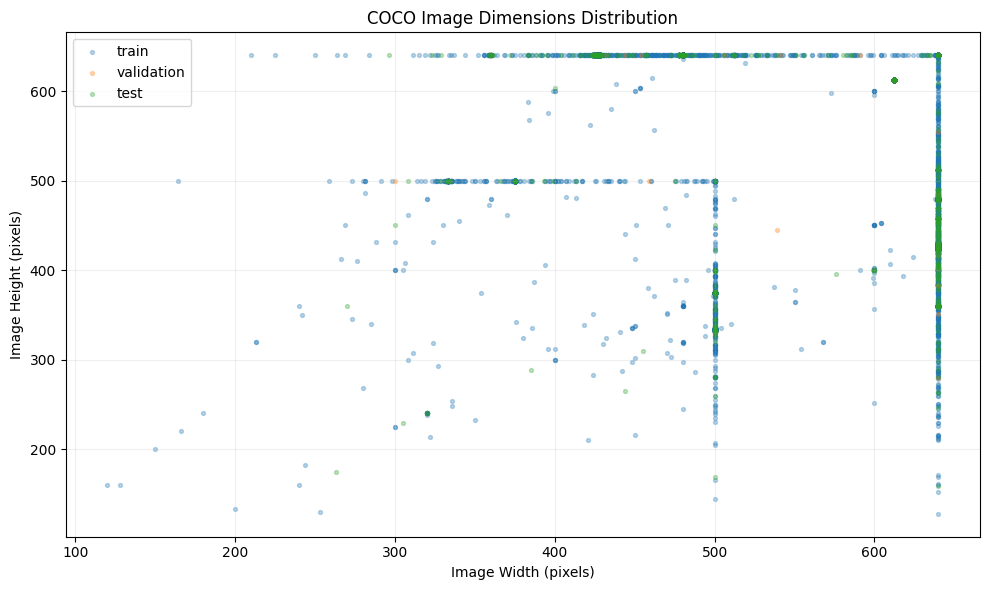

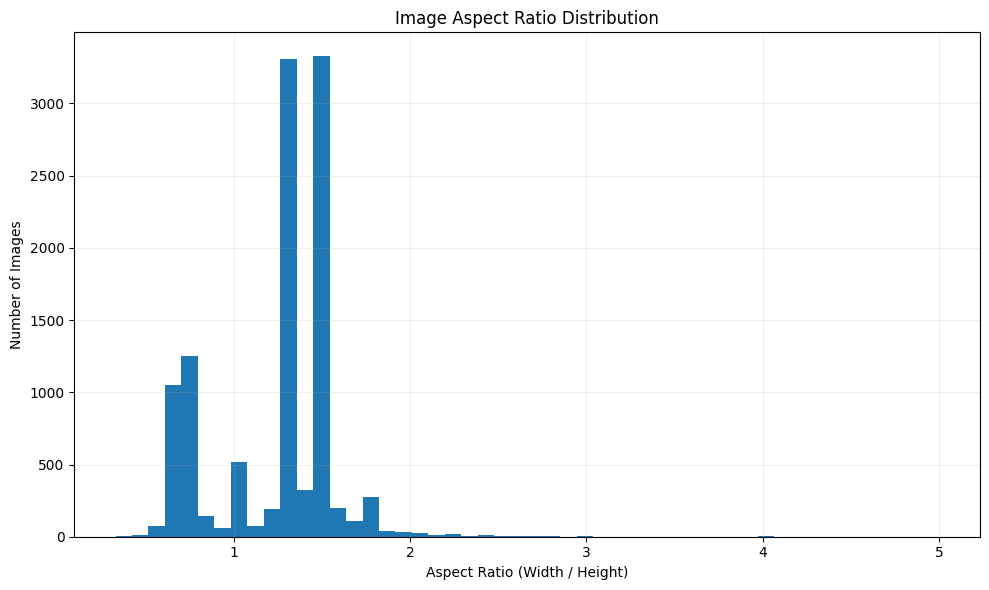

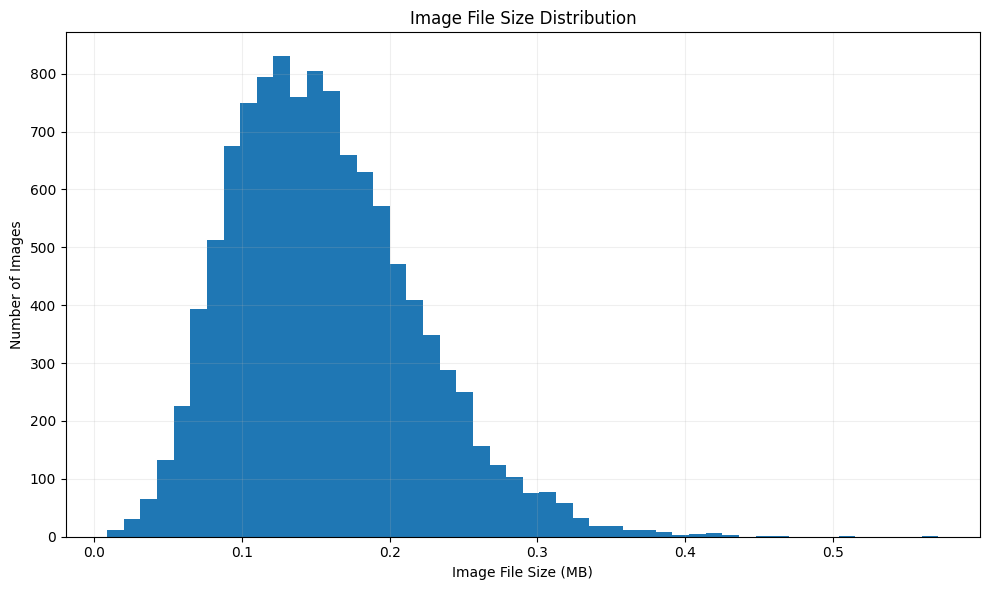

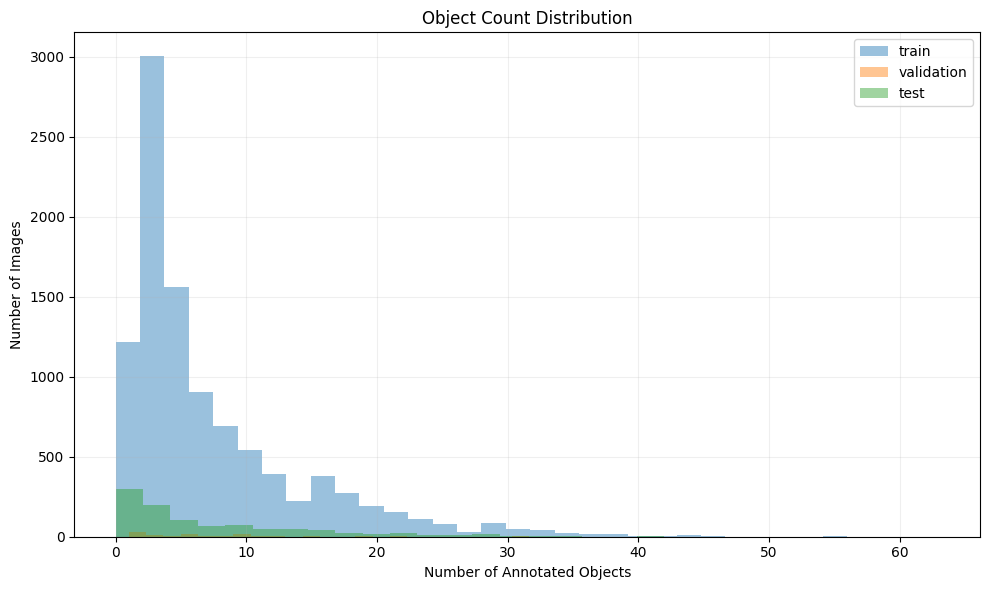

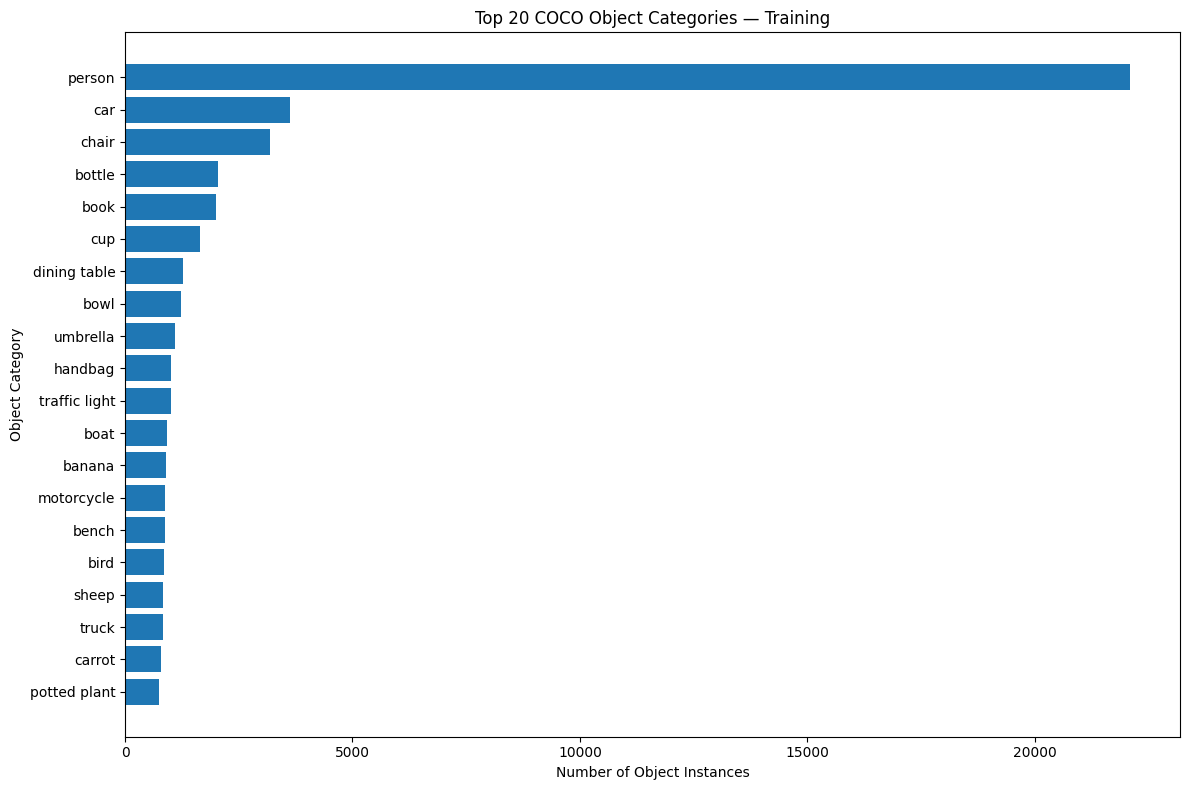

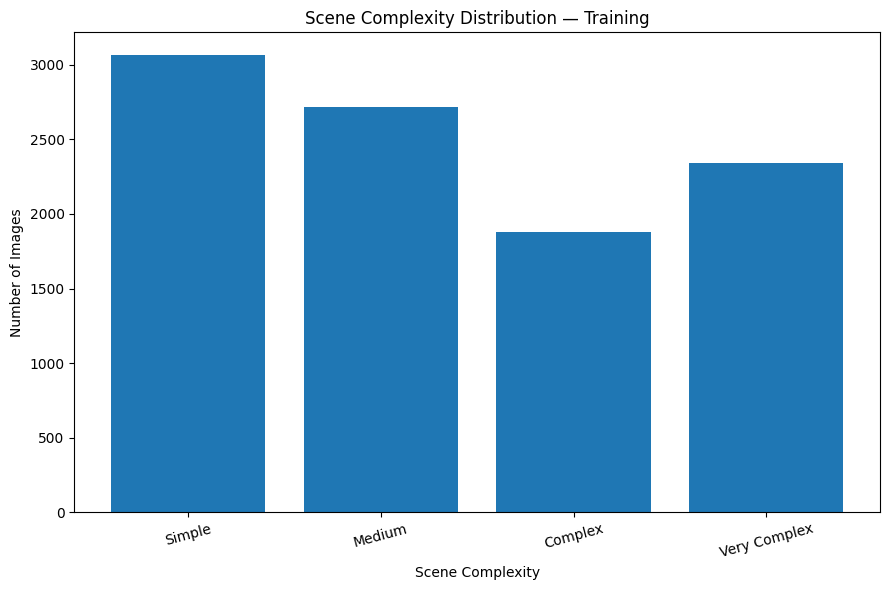

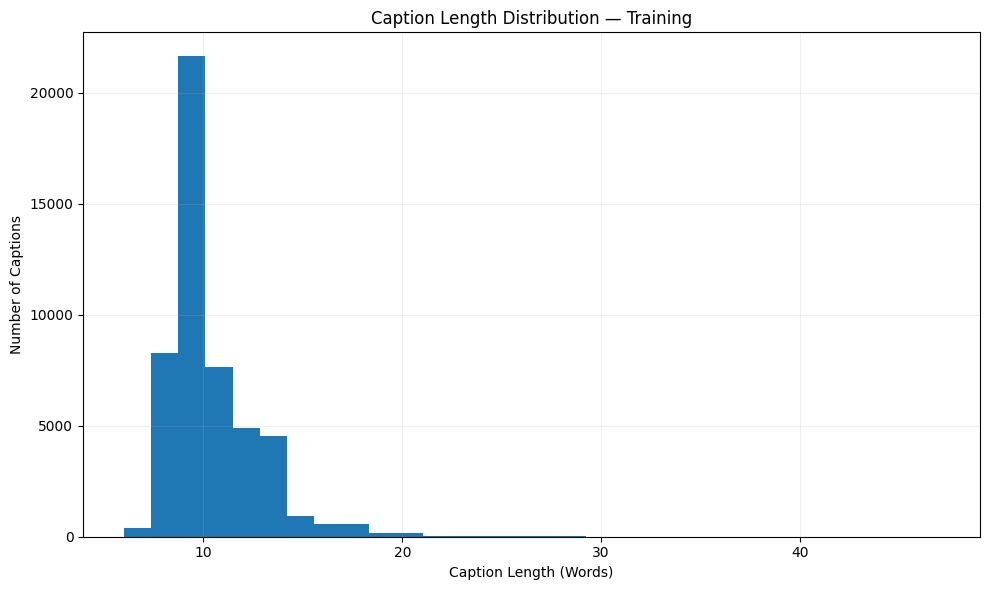

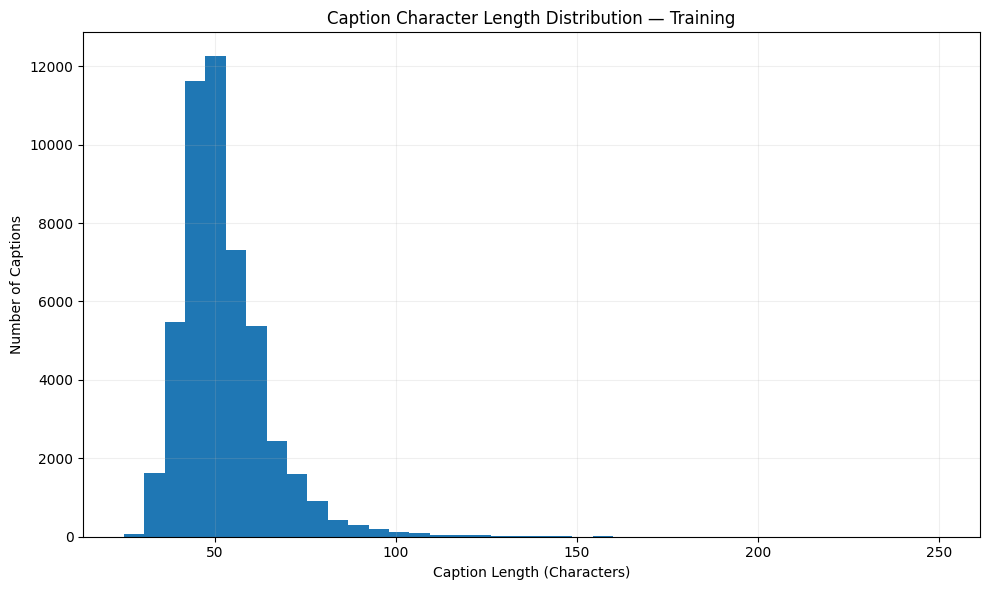

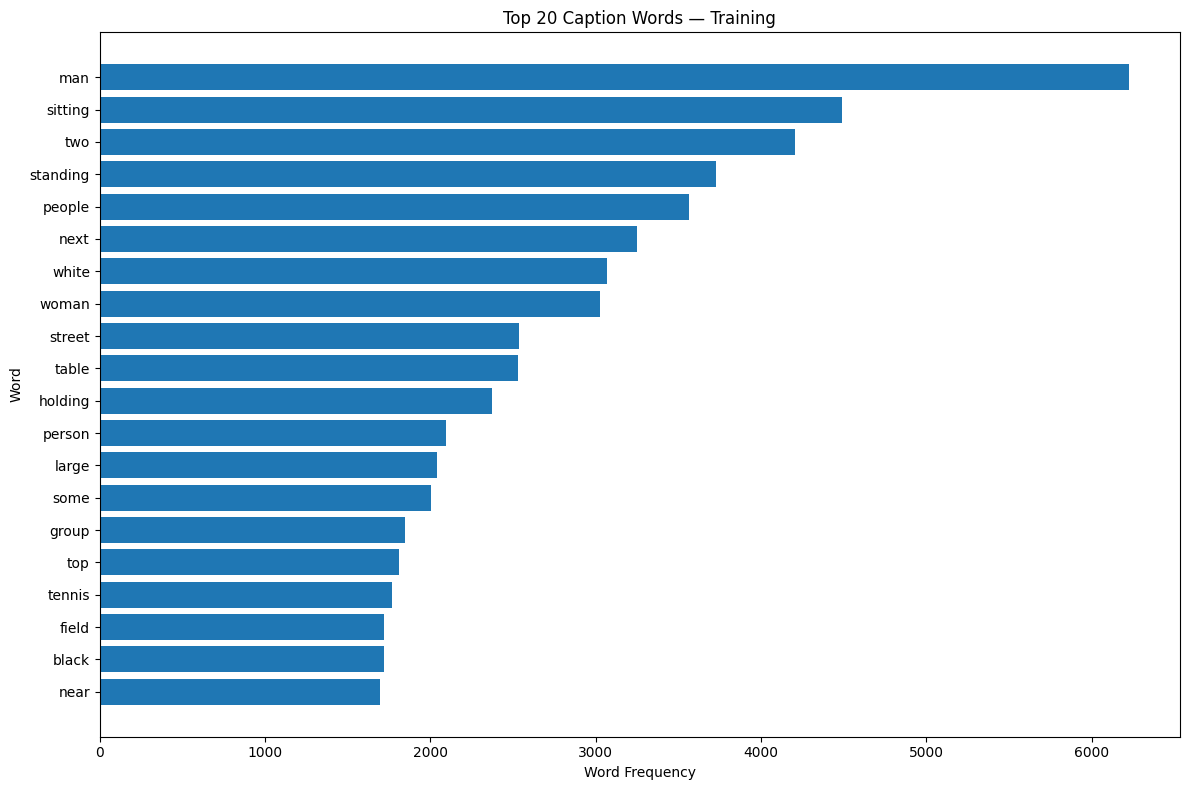

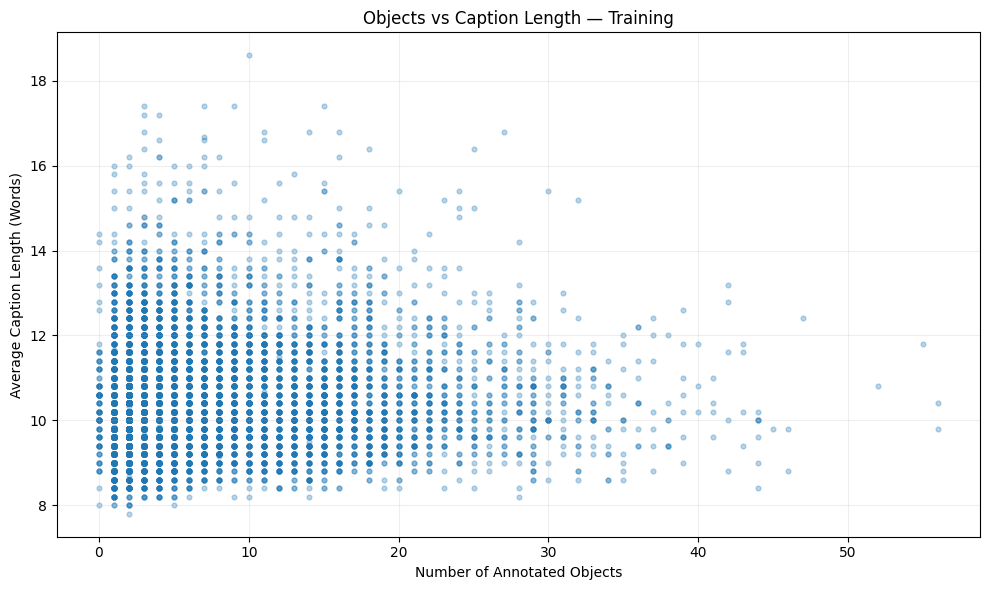


STEP 7 — FINAL EDA SUMMARY
Total images analyzed: 11100
Total captions analyzed: 55525
Total object annotations: 80652
Training vocabulary size: 9804

Figures saved: 10
Tables saved: 9

Report saved:
/content/drive/MyDrive/Image_Captioning_Phase1/reports/before_preprocessing_eda_report.json

[PASS] STEP 7 EDA ANALYSIS COMPLETED.


In [ ]:

# ============================================================
# STEP 7 — BEFORE-PREPROCESSING DATA EXPLORATION
# MS-COCO 2017 | 11,100 Images
# ============================================================

import os
import re
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter, defaultdict
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. PROJECT CONFIGURATION
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

RAW_DIR = PROJECT_DIR / "data/raw"
SPLITS_DIR = PROJECT_DIR / "data/splits"

REPORTS_DIR = PROJECT_DIR / "reports"

FIGURES_DIR = REPORTS_DIR / "figures"
TABLES_DIR = REPORTS_DIR / "tables"

for directory in [FIGURES_DIR, TABLES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

DATASETS = {

    "train": {
        "ids": SPLITS_DIR / "train_ids.json",
        "captions": SPLITS_DIR / "train_ground_truth.json",
        "instances": SPLITS_DIR / "train_instances.json",
        "images": RAW_DIR / "train2017"
    },

    "validation": {
        "ids": SPLITS_DIR / "validation_ids.json",
        "captions": SPLITS_DIR / "validation_ground_truth.json",
        "instances": SPLITS_DIR / "validation_instances.json",
        "images": RAW_DIR / "validation"
    },

    "test": {
        "ids": SPLITS_DIR / "test_ids.json",
        "captions": SPLITS_DIR / "test_ground_truth.json",
        "instances": SPLITS_DIR / "test_instances.json",
        "images": RAW_DIR / "val2017"
    }

}

EXPECTED_COUNTS = {
    "train": 10000,
    "validation": 100,
    "test": 1000
}

print("=" * 70)
print("STEP 7 — BEFORE-PREPROCESSING DATA EXPLORATION")
print("=" * 70)

# ------------------------------------------------------------
# 2. VERIFY INPUT FILES
# ------------------------------------------------------------

for split, paths in DATASETS.items():

    for key, path in paths.items():

        if not path.exists():

            raise FileNotFoundError(
                f"Missing {key} file for {split}: {path}"
            )

print("\n[PASS] All EDA input files found.")

# ------------------------------------------------------------
# 3. LOAD DATASETS
# ------------------------------------------------------------

data = {}

for split, paths in DATASETS.items():

    with open(paths["ids"], "r") as f:
        ids = json.load(f)

    with open(paths["captions"], "r") as f:
        captions = json.load(f)

    with open(paths["instances"], "r") as f:
        instances = json.load(f)

    assert len(ids) == EXPECTED_COUNTS[split]

    assert len(captions["images"]) == EXPECTED_COUNTS[split]

    assert len(instances["images"]) == EXPECTED_COUNTS[split]

    data[split] = {

        "ids": ids,

        "captions": captions,

        "instances": instances,

        "image_dir": paths["images"]

    }

    print(
        f"[OK] {split.upper()}: "
        f"{len(ids)} images loaded."
    )

# ------------------------------------------------------------
# 4. IMAGE STATISTICS
# ------------------------------------------------------------

image_rows = []

for split, dataset in data.items():

    print(f"\nAnalyzing {split.upper()} image metadata...")

    for record in tqdm(dataset["ids"]):

        image_id = record["image_id"]

        width = record["width"]

        height = record["height"]

        filename = record["file_name"]

        image_path = dataset["image_dir"] / filename

        if not image_path.exists():

            raise FileNotFoundError(
                f"Image missing: {image_path}"
            )

        file_size_bytes = image_path.stat().st_size

        aspect_ratio = width / height

        megapixels = (width * height) / 1_000_000

        image_rows.append({

            "split": split,

            "image_id": image_id,

            "file_name": filename,

            "width": width,

            "height": height,

            "pixels": width * height,

            "megapixels": megapixels,

            "aspect_ratio": aspect_ratio,

            "file_size_bytes": file_size_bytes,

            "file_size_mb": file_size_bytes / (1024 ** 2)

        })

image_df = pd.DataFrame(image_rows)

assert len(image_df) == 11100

assert image_df["image_id"].nunique() == 11100

# ------------------------------------------------------------
# 5. IMAGE STATISTICS SUMMARY
# ------------------------------------------------------------

image_summary = image_df.groupby("split").agg(

    image_count=("image_id", "count"),

    min_width=("width", "min"),

    max_width=("width", "max"),

    mean_width=("width", "mean"),

    median_width=("width", "median"),

    min_height=("height", "min"),

    max_height=("height", "max"),

    mean_height=("height", "mean"),

    median_height=("height", "median"),

    mean_megapixels=("megapixels", "mean"),

    median_megapixels=("megapixels", "median"),

    mean_aspect_ratio=("aspect_ratio", "mean"),

    mean_file_size_mb=("file_size_mb", "mean"),

    median_file_size_mb=("file_size_mb", "median")

).round(3)

image_summary.to_csv(
    TABLES_DIR / "image_statistics.csv"
)

print("\nIMAGE STATISTICS")
print("-" * 70)

print(image_summary)

# ------------------------------------------------------------
# 6. OBJECTS PER IMAGE
# ------------------------------------------------------------

object_rows = []

all_category_info = {}

for split, dataset in data.items():

    instances = dataset["instances"]

    annotations = instances["annotations"]

    categories = instances["categories"]

    category_mapping = {
        cat["id"]: cat["name"]
        for cat in categories
    }

    all_category_info[split] = category_mapping

    object_counter = Counter(

        annotation["image_id"]

        for annotation in annotations

    )

    for record in dataset["ids"]:

        image_id = record["image_id"]

        object_count = object_counter.get(
            image_id, 0
        )

        object_rows.append({

            "split": split,

            "image_id": image_id,

            "object_count": object_count

        })

objects_df = pd.DataFrame(object_rows)

objects_df.to_csv(
    TABLES_DIR / "objects_per_image.csv",
    index=False
)

# ------------------------------------------------------------
# 7. OBJECT CATEGORY STATISTICS
# ------------------------------------------------------------

category_rows = []

for split, dataset in data.items():

    category_mapping = all_category_info[split]

    annotations = dataset["instances"]["annotations"]

    category_counter = Counter(

        annotation["category_id"]

        for annotation in annotations

    )

    category_image_counter = defaultdict(set)

    for annotation in annotations:

        category_image_counter[
            annotation["category_id"]
        ].add(annotation["image_id"])

    for category_id, category_name in category_mapping.items():

        category_rows.append({

            "split": split,

            "category_id": category_id,

            "category_name": category_name,

            "instance_count": category_counter.get(
                category_id, 0
            ),

            "image_count": len(
                category_image_counter[category_id]
            )

        })

category_df = pd.DataFrame(category_rows)

category_df.to_csv(
    TABLES_DIR / "object_category_statistics.csv",
    index=False
)

# ------------------------------------------------------------
# 8. OBJECT DISTRIBUTION SUMMARY
# ------------------------------------------------------------

object_summary = objects_df.groupby("split").agg(

    image_count=("image_id", "count"),

    total_objects=("object_count", "sum"),

    mean_objects=("object_count", "mean"),

    median_objects=("object_count", "median"),

    min_objects=("object_count", "min"),

    max_objects=("object_count", "max")

).round(3)

object_summary["images_without_objects"] = (

    objects_df[
        objects_df["object_count"] == 0
    ].groupby("split")["image_id"].count()

).fillna(0).astype(int)

object_summary["images_with_objects"] = (

    object_summary["image_count"]

    - object_summary["images_without_objects"]

)

object_summary.to_csv(
    TABLES_DIR / "object_summary.csv"
)

print("\nOBJECT STATISTICS")
print("-" * 70)

print(object_summary)

# ------------------------------------------------------------
# 9. TOP 20 OBJECT CATEGORIES — TRAINING
# ------------------------------------------------------------

train_categories = category_df[
    category_df["split"] == "train"
].sort_values(
    "instance_count",
    ascending=False
)

top_20_categories = train_categories.head(20)

top_20_categories.to_csv(
    TABLES_DIR / "top_20_object_categories.csv",
    index=False
)

print("\nTOP 20 OBJECT CATEGORIES — TRAINING")
print("-" * 70)

print(
    top_20_categories[
        ["category_name", "instance_count", "image_count"]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 10. SCENE COMPLEXITY ANALYSIS
# ------------------------------------------------------------

def classify_scene(count):

    if count <= 2:
        return "Simple"

    elif count <= 5:
        return "Medium"

    elif count <= 10:
        return "Complex"

    else:
        return "Very Complex"

objects_df["scene_complexity"] = (
    objects_df["object_count"].apply(classify_scene)
)

complexity_order = [
    "Simple",
    "Medium",
    "Complex",
    "Very Complex"
]

scene_counts = pd.crosstab(
    objects_df["split"],
    objects_df["scene_complexity"]
)

scene_counts = scene_counts.reindex(
    columns=complexity_order,
    fill_value=0
)

scene_counts.to_csv(
    TABLES_DIR / "scene_complexity_statistics.csv"
)

print("\nSCENE COMPLEXITY DISTRIBUTION")
print("-" * 70)

print(scene_counts)

# ------------------------------------------------------------
# 11. CAPTION TEXT ANALYSIS
# ------------------------------------------------------------

caption_rows = []

for split, dataset in data.items():

    annotations = dataset["captions"]["annotations"]

    print(f"\nAnalyzing {split.upper()} captions...")

    for annotation in tqdm(annotations):

        caption = annotation["caption"]

        words = caption.strip().split()

        caption_rows.append({

            "split": split,

            "image_id": annotation["image_id"],

            "caption_id": annotation["id"],

            "caption": caption,

            "word_count": len(words),

            "character_count": len(caption),

            "unique_words": len(set(words))

        })

caption_df = pd.DataFrame(caption_rows)

assert caption_df["caption"].notna().all()

assert (caption_df["word_count"] > 0).all()

# ------------------------------------------------------------
# 12. CAPTION SUMMARY STATISTICS
# ------------------------------------------------------------

caption_summary = caption_df.groupby("split").agg(

    total_captions=("caption_id", "count"),

    mean_words=("word_count", "mean"),

    median_words=("word_count", "median"),

    min_words=("word_count", "min"),

    max_words=("word_count", "max"),

    std_words=("word_count", "std"),

    mean_characters=("character_count", "mean"),

    median_characters=("character_count", "median"),

    min_characters=("character_count", "min"),

    max_characters=("character_count", "max")

).round(3)

caption_summary.to_csv(
    TABLES_DIR / "caption_statistics.csv"
)

print("\nCAPTION STATISTICS")
print("-" * 70)

print(caption_summary)

# ------------------------------------------------------------
# 13. PER-IMAGE CAPTION SUMMARY
# ------------------------------------------------------------

caption_per_image = caption_df.groupby(
    ["split", "image_id"]
).agg(

    caption_count=("caption_id", "count"),

    mean_caption_words=("word_count", "mean"),

    mean_caption_characters=("character_count", "mean"),

    max_caption_words=("word_count", "max")

).reset_index()

caption_per_image.to_csv(
    TABLES_DIR / "caption_summary.csv",
    index=False
)

# ------------------------------------------------------------
# 14. VOCABULARY ANALYSIS
# ------------------------------------------------------------

STOPWORDS = set("""

a an the and or but if while with at by for from
in into on onto of off over under to up down
is are was were be been being
have has had do does did
i you he she it we they
this that these those
my your his her its our their
me him them us
as about after before between through
during without within
who whom which what when where
there here
can could will would should may might must
not no nor so than too very
""".split())

vocabulary_rows = []

for split in data:

    split_captions = caption_df[
        caption_df["split"] == split
    ]["caption"]

    word_counter = Counter()

    for caption in split_captions:

        tokens = re.findall(
            r"[a-z0-9]+(?:'[a-z]+)?",
            caption.lower()
        )

        filtered_tokens = [

            token for token in tokens

            if token not in STOPWORDS

        ]

        word_counter.update(filtered_tokens)

    vocabulary_rows.append({

        "split": split,

        "total_tokens": sum(word_counter.values()),

        "unique_words": len(word_counter),

        "top_20_words": word_counter.most_common(20)

    })

vocabulary_report = {}

for row in vocabulary_rows:

    vocabulary_report[row["split"]] = {

        "total_tokens": row["total_tokens"],

        "unique_words": row["unique_words"],

        "top_20_words": row["top_20_words"]

    }

train_word_counter = Counter()

for caption in caption_df[
    caption_df["split"] == "train"
]["caption"]:

    tokens = re.findall(
        r"[a-z0-9]+(?:'[a-z]+)?",
        caption.lower()
    )

    train_word_counter.update(

        token for token in tokens

        if token not in STOPWORDS

    )

top_words_df = pd.DataFrame(

    train_word_counter.most_common(20),

    columns=["word", "frequency"]

)

top_words_df.to_csv(
    TABLES_DIR / "top_20_caption_words.csv",
    index=False
)

print("\nVOCABULARY STATISTICS")
print("-" * 70)

for row in vocabulary_rows:

    print(f"\n{row['split'].upper()}")

    print("Total tokens:", row["total_tokens"])

    print("Unique words:", row["unique_words"])

    print("Top words:", row["top_20_words"][:10])

# ------------------------------------------------------------
# 15. OBJECTS AND CAPTION RELATIONSHIP
# ------------------------------------------------------------

relationship_df = objects_df.merge(

    caption_per_image,

    on=["split", "image_id"],

    how="inner"

)

assert len(relationship_df) == 11100

correlation_results = {}

for split in ["train", "validation", "test"]:

    subset = relationship_df[
        relationship_df["split"] == split
    ]

    pearson = subset[
        ["object_count", "mean_caption_words"]
    ].corr(method="pearson").iloc[0, 1]

    spearman = subset[
        ["object_count", "mean_caption_words"]
    ].corr(method="spearman").iloc[0, 1]

    correlation_results[split] = {

        "pearson_object_caption_length": float(pearson),

        "spearman_object_caption_length": float(spearman)

    }

print("\nOBJECT / CAPTION CORRELATION")
print("-" * 70)

for split, results in correlation_results.items():

    print(f"\n{split.upper()}")

    print(
        "Pearson:",
        round(results["pearson_object_caption_length"], 4)
    )

    print(
        "Spearman:",
        round(results["spearman_object_caption_length"], 4)
    )

# ------------------------------------------------------------
# 16. FIGURE 1 — IMAGE DIMENSIONS
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for split in ["train", "validation", "test"]:

    subset = image_df[
        image_df["split"] == split
    ]

    plt.scatter(
        subset["width"],
        subset["height"],
        alpha=0.3,
        s=8,
        label=split
    )

plt.xlabel("Image Width (pixels)")
plt.ylabel("Image Height (pixels)")
plt.title("COCO Image Dimensions Distribution")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "image_dimensions.png",
    dpi=300
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 17. FIGURE 2 — ASPECT RATIO
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.hist(
    image_df["aspect_ratio"],
    bins=50
)

plt.xlabel("Aspect Ratio (Width / Height)")
plt.ylabel("Number of Images")
plt.title("Image Aspect Ratio Distribution")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "aspect_ratio_distribution.png",
    dpi=300
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 18. FIGURE 3 — IMAGE FILE SIZE
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.hist(
    image_df["file_size_mb"],
    bins=50
)

plt.xlabel("Image File Size (MB)")
plt.ylabel("Number of Images")
plt.title("Image File Size Distribution")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "image_file_size.png",
    dpi=300
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 19. FIGURE 4 — OBJECTS PER IMAGE
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for split in ["train", "validation", "test"]:

    subset = objects_df[
        objects_df["split"] == split
    ]

    plt.hist(
        subset["object_count"],
        bins=30,
        alpha=0.45,
        label=split
    )

plt.xlabel("Number of Annotated Objects")
plt.ylabel("Number of Images")
plt.title("Object Count Distribution")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "objects_per_image.png",
    dpi=300
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 20. FIGURE 5 — TOP 20 OBJECT CATEGORIES
# ------------------------------------------------------------

plt.figure(figsize=(12, 8))

plot_categories = top_20_categories.sort_values(
    "instance_count"
)

plt.barh(
    plot_categories["category_name"],
    plot_categories["instance_count"]
)

plt.xlabel("Number of Object Instances")
plt.ylabel("Object Category")
plt.title("Top 20 COCO Object Categories — Training")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_20_object_categories.png",
    dpi=300
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 21. FIGURE 6 — SCENE COMPLEXITY
# ------------------------------------------------------------

train_scene_counts = scene_counts.loc["train"]

plt.figure(figsize=(9, 6))

plt.bar(
    train_scene_counts.index,
    train_scene_counts.values
)

plt.xlabel("Scene Complexity")
plt.ylabel("Number of Images")
plt.title("Scene Complexity Distribution — Training")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "scene_complexity_distribution.png",
    dpi=300
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 22. FIGURE 7 — CAPTION LENGTH IN WORDS
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

train_word_lengths = caption_df[
    caption_df["split"] == "train"
]["word_count"]

plt.hist(
    train_word_lengths,
    bins=30
)

plt.xlabel("Caption Length (Words)")
plt.ylabel("Number of Captions")
plt.title("Caption Length Distribution — Training")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "caption_length_words.png",
    dpi=300
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 23. FIGURE 8 — CAPTION LENGTH IN CHARACTERS
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

train_char_lengths = caption_df[
    caption_df["split"] == "train"
]["character_count"]

plt.hist(
    train_char_lengths,
    bins=40
)

plt.xlabel("Caption Length (Characters)")
plt.ylabel("Number of Captions")
plt.title("Caption Character Length Distribution — Training")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "caption_length_characters.png",
    dpi=300
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 24. FIGURE 9 — TOP 20 CAPTION WORDS
# ------------------------------------------------------------

plt.figure(figsize=(12, 8))

plot_words = top_words_df.sort_values(
    "frequency"
)

plt.barh(
    plot_words["word"],
    plot_words["frequency"]
)

plt.xlabel("Word Frequency")
plt.ylabel("Word")
plt.title("Top 20 Caption Words — Training")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_20_caption_words.png",
    dpi=300
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 25. FIGURE 10 — OBJECTS VS CAPTION LENGTH
# ------------------------------------------------------------

train_relationship = relationship_df[
    relationship_df["split"] == "train"
]

plt.figure(figsize=(10, 6))

plt.scatter(
    train_relationship["object_count"],
    train_relationship["mean_caption_words"],
    alpha=0.3,
    s=12
)

plt.xlabel("Number of Annotated Objects")
plt.ylabel("Average Caption Length (Words)")
plt.title("Objects vs Caption Length — Training")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "objects_caption_relationship.png",
    dpi=300
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 26. SAVE EDA REPORT
# ------------------------------------------------------------

report = {

    "project": "MS-COCO 2017 Image Captioning",

    "step": "STEP 7 - Before Preprocessing EDA",

    "total_images": len(image_df),

    "dataset_sizes": EXPECTED_COUNTS,

    "image_statistics": (
        image_summary.reset_index().to_dict("records")
    ),

    "object_statistics": (
        object_summary.reset_index().to_dict("records")
    ),

    "caption_statistics": (
        caption_summary.reset_index().to_dict("records")
    ),

    "scene_complexity": {

        split: {

            category: int(scene_counts.loc[split, category])

            for category in complexity_order

        }

        for split in scene_counts.index

    },

    "top_20_object_categories": (
        top_20_categories[
            ["category_name", "instance_count", "image_count"]
        ].to_dict("records")
    ),

    "vocabulary_statistics": vocabulary_report,

    "object_caption_correlations": correlation_results,

    "analysis_stage": "BEFORE_PREPROCESSING",

    "status": "COMPLETED"

}

REPORT_FILE = (
    REPORTS_DIR / "before_preprocessing_eda_report.json"
)

with open(REPORT_FILE, "w") as f:

    json.dump(
        report,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 27. FINAL EDA SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)

print("STEP 7 — FINAL EDA SUMMARY")

print("=" * 70)

print("Total images analyzed:", len(image_df))

print("Total captions analyzed:", len(caption_df))

print(
    "Total object annotations:",
    sum(
        len(dataset["instances"]["annotations"])
        for dataset in data.values()
    )
)

print(
    "Training vocabulary size:",
    vocabulary_report["train"]["unique_words"]
)

print("\nFigures saved:", len(list(FIGURES_DIR.glob("*.png"))))

print("Tables saved:", len(list(TABLES_DIR.glob("*.csv"))))

print("\nReport saved:")

print(REPORT_FILE)

print("\n[PASS] STEP 7 EDA ANALYSIS COMPLETED.")


In [ ]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

REPORTS_DIR = PROJECT_DIR / "reports"
TABLES_DIR = REPORTS_DIR / "tables"

objects_path = TABLES_DIR / "objects_per_image.csv"
summary_path = TABLES_DIR / "object_summary.csv"

# Load per-image object counts
objects_df = pd.read_csv(objects_path)

print("=" * 65)
print("VALIDATION OBJECT COUNT AUDIT")
print("=" * 65)

validation_df = objects_df[
    objects_df["split"].str.lower() == "validation"
]

print("Validation images:", len(validation_df))
print("Images with objects:",
      (validation_df["object_count"] > 0).sum())

print("Images without objects:",
      (validation_df["object_count"] == 0).sum())

print("Total object annotations:",
      validation_df["object_count"].sum())

# Verify expected values
assert len(validation_df) == 100
assert validation_df["object_count"].sum() == 813
assert (validation_df["object_count"] > 0).sum() == 100
assert (validation_df["object_count"] == 0).sum() == 0

print("\n[PASS] Validation object counts are correct.")

# Inspect the existing summary
summary_df = pd.read_csv(summary_path)

print("\nCURRENT OBJECT SUMMARY")
print(summary_df.to_string(index=False))

VALIDATION OBJECT COUNT AUDIT
Validation images: 100
Images with objects: 100
Images without objects: 0
Total object annotations: 813

[PASS] Validation object counts are correct.

CURRENT OBJECT SUMMARY
     split  image_count  total_objects  mean_objects  median_objects  min_objects  max_objects  images_without_objects  images_with_objects
      test         1000           7777         7.777             5.0            0           63                     8.0                992.0
     train        10000          72062         7.206             4.0            0           56                   102.0               9898.0
validation          100            813         8.130             6.0            1           41                     NaN                  NaN


In [ ]:
import pandas as pd
import json
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

TABLES_DIR = PROJECT_DIR / "reports" / "tables"

objects_path = TABLES_DIR / "objects_per_image.csv"
summary_path = TABLES_DIR / "object_summary.csv"

# Load the original per-image object counts
objects_df = pd.read_csv(objects_path)

# Recalculate summary for every split
summary_rows = []

for split in ["train", "validation", "test"]:

    df = objects_df[
        objects_df["split"].str.lower() == split
    ]

    counts = df["object_count"]

    summary_rows.append({
        "split": split,
        "image_count": len(df),
        "total_objects": int(counts.sum()),
        "mean_objects": round(counts.mean(), 3),
        "median_objects": float(counts.median()),
        "min_objects": int(counts.min()),
        "max_objects": int(counts.max()),
        "images_without_objects": int((counts == 0).sum()),
        "images_with_objects": int((counts > 0).sum())
    })

# Create corrected summary
corrected_summary = pd.DataFrame(summary_rows)

# Save corrected CSV
corrected_summary.to_csv(summary_path, index=False)

print("=" * 65)
print("CORRECTED OBJECT SUMMARY")
print("=" * 65)

print(corrected_summary.to_string(index=False))

# Verify all expected values
expected = {
    "train": (10000, 72062, 102, 9898),
    "validation": (100, 813, 0, 100),
    "test": (1000, 7777, 8, 992)
}

for _, row in corrected_summary.iterrows():

    values = (
        row["image_count"],
        row["total_objects"],
        row["images_without_objects"],
        row["images_with_objects"]
    )

    assert values == expected[row["split"]], (
        f"Mismatch in {row['split']}: {values}"
    )

print("\n[PASS] All object statistics verified.")
print("[PASS] Corrected object_summary.csv saved.")


CORRECTED OBJECT SUMMARY
     split  image_count  total_objects  mean_objects  median_objects  min_objects  max_objects  images_without_objects  images_with_objects
     train        10000          72062         7.206             4.0            0           56                     102                 9898
validation          100            813         8.130             6.0            1           41                       0                  100
      test         1000           7777         7.777             5.0            0           63                       8                  992

[PASS] All object statistics verified.
[PASS] Corrected object_summary.csv saved.


In [ ]:
import json
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

REPORT_PATH = (
    PROJECT_DIR
    / "reports"
    / "before_preprocessing_eda_report.json"
)

with open(REPORT_PATH, "r", encoding="utf-8") as f:
    report = json.load(f)

print("=" * 65)
print("EDA REPORT STRUCTURE AUDIT")
print("=" * 65)

print("\nTOP-LEVEL KEYS:")
for key in report.keys():
    print("-", key)

print("\nOBJECT-RELATED SECTIONS:")

def inspect_object_sections(data, path=""):
    if isinstance(data, dict):
        for key, value in data.items():
            current_path = f"{path}.{key}" if path else key

            if "object" in key.lower() or "scene" in key.lower():
                print(f"\n[{current_path}]")
                print(json.dumps(
                    value,
                    ensure_ascii=False,
                    indent=2
                )[:5000])

            if isinstance(value, (dict, list)):
                inspect_object_sections(value, current_path)

    elif isinstance(data, list):
        for index, value in enumerate(data):
            if isinstance(value, (dict, list)):
                inspect_object_sections(
                    value,
                    f"{path}[{index}]"
                )

inspect_object_sections(report)

print("\n[PASS] EDA report loaded and inspected.")

EDA REPORT STRUCTURE AUDIT

TOP-LEVEL KEYS:
- project
- step
- total_images
- dataset_sizes
- image_statistics
- object_statistics
- caption_statistics
- scene_complexity
- top_20_object_categories
- vocabulary_statistics
- object_caption_correlations
- analysis_stage
- status

OBJECT-RELATED SECTIONS:

[object_statistics]
[
  {
    "split": "test",
    "image_count": 1000,
    "total_objects": 7777,
    "mean_objects": 7.777,
    "median_objects": 5.0,
    "min_objects": 0,
    "max_objects": 63,
    "images_without_objects": 8.0,
    "images_with_objects": 992.0
  },
  {
    "split": "train",
    "image_count": 10000,
    "total_objects": 72062,
    "mean_objects": 7.206,
    "median_objects": 4.0,
    "min_objects": 0,
    "max_objects": 56,
    "images_without_objects": 102.0,
    "images_with_objects": 9898.0
  },
  {
    "split": "validation",
    "image_count": 100,
    "total_objects": 813,
    "mean_objects": 8.13,
    "median_objects": 6.0,
    "min_objects": 1,
    "max_obje

In [ ]:
import json
import pandas as pd
from pathlib import Path
import shutil

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

REPORTS_DIR = PROJECT_DIR / "reports"
TABLES_DIR = REPORTS_DIR / "tables"

REPORT_PATH = REPORTS_DIR / "before_preprocessing_eda_report.json"
SUMMARY_PATH = TABLES_DIR / "object_summary.csv"

# 1. Create a backup before modification
BACKUP_PATH = REPORTS_DIR / "before_preprocessing_eda_report_backup.json"

shutil.copy2(REPORT_PATH, BACKUP_PATH)

# 2. Load the corrected object summary
summary_df = pd.read_csv(SUMMARY_PATH)

# 3. Load the existing EDA report
with open(REPORT_PATH, "r", encoding="utf-8") as f:
    report = json.load(f)

# 4. Replace only object_statistics
report["object_statistics"] = (
    summary_df.to_dict(orient="records")
)

# 5. Save safely, rejecting NaN and Infinity
TEMP_PATH = REPORTS_DIR / "eda_report_temp.json"

with open(TEMP_PATH, "w", encoding="utf-8") as f:
    json.dump(
        report,
        f,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )

# Replace original report only after successful serialization
TEMP_PATH.replace(REPORT_PATH)

# 6. Strict JSON verification
def reject_nonstandard_constant(value):
    raise ValueError(f"Invalid JSON constant: {value}")

with open(REPORT_PATH, "r", encoding="utf-8") as f:
    verified_report = json.load(
        f,
        parse_constant=reject_nonstandard_constant
    )

# 7. Verify expected statistics
expected = {
    "train": (10000, 72062, 102, 9898),
    "validation": (100, 813, 0, 100),
    "test": (1000, 7777, 8, 992)
}

for item in verified_report["object_statistics"]:

    split = item["split"]

    actual = (
        item["image_count"],
        item["total_objects"],
        item["images_without_objects"],
        item["images_with_objects"]
    )

    assert actual == expected[split], (
        f"Incorrect statistics for {split}: {actual}"
    )

print("=" * 65)
print("FINAL EDA REPORT VERIFICATION")
print("=" * 65)

print("\nOBJECT STATISTICS:")
for item in verified_report["object_statistics"]:
    print(item)

print("\n[PASS] All object statistics are correct.")
print("[PASS] No NaN or Infinity values.")
print("[PASS] JSON format is strictly valid.")
print("[PASS] All other report sections preserved.")
print("[PASS] Original report backup created.")

print("\nReport:", REPORT_PATH)
print("Backup:", BACKUP_PATH)

FINAL EDA REPORT VERIFICATION

OBJECT STATISTICS:
{'split': 'train', 'image_count': 10000, 'total_objects': 72062, 'mean_objects': 7.206, 'median_objects': 4.0, 'min_objects': 0, 'max_objects': 56, 'images_without_objects': 102, 'images_with_objects': 9898}
{'split': 'validation', 'image_count': 100, 'total_objects': 813, 'mean_objects': 8.13, 'median_objects': 6.0, 'min_objects': 1, 'max_objects': 41, 'images_without_objects': 0, 'images_with_objects': 100}
{'split': 'test', 'image_count': 1000, 'total_objects': 7777, 'mean_objects': 7.777, 'median_objects': 5.0, 'min_objects': 0, 'max_objects': 63, 'images_without_objects': 8, 'images_with_objects': 992}

[PASS] All object statistics are correct.
[PASS] No NaN or Infinity values.
[PASS] JSON format is strictly valid.
[PASS] All other report sections preserved.
[PASS] Original report backup created.

Report: /content/drive/MyDrive/Image_Captioning_Phase1/reports/before_preprocessing_eda_report.json
Backup: /content/drive/MyDrive/Image

In [ ]:
import os
from pathlib import Path
import torch

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

print("=" * 70)
print("STEP 8.1 — ENVIRONMENT AND IMAGE DIRECTORY AUDIT")
print("=" * 70)

# 1. Verify project directory
assert PROJECT_DIR.exists(), "Project directory not found!"

print("\n[OK] Project directory exists.")

# 2. Check GPU
print("\nGPU INFORMATION")
print("-" * 50)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3),
            2
        ),
        "GB"
    )
else:
    print("[WARNING] No GPU detected.")

# 3. Inspect image directories
print("\nIMAGE DIRECTORY INSPECTION")
print("-" * 50)

SEARCH_DIRS = [
    PROJECT_DIR / "data" / "raw",
    PROJECT_DIR / "data" / "processed"
]

for base_dir in SEARCH_DIRS:

    if not base_dir.exists():
        print(f"\n[NOT FOUND] {base_dir}")
        continue

    print(f"\nDirectory: {base_dir}")

    for folder in sorted(base_dir.iterdir()):

        if folder.is_dir():

            image_count = sum(
                1 for _ in folder.glob("*.jpg")
            )

            print(
                f"{folder.name:<25} "
                f"{image_count:>8} JPEG images"
            )

# 4. Verify split files
print("\nSPLIT FILES")
print("-" * 50)

SPLITS_DIR = PROJECT_DIR / "data" / "splits"

for filename in [
    "train_ids.json",
    "validation_ids.json",
    "test_ids.json"
]:

    path = SPLITS_DIR / filename

    print(
        f"{filename:<25}",
        "FOUND" if path.exists() else "MISSING"
    )

print("\n[PASS] Environment inspection completed.")

STEP 8.1 — ENVIRONMENT AND IMAGE DIRECTORY AUDIT

[OK] Project directory exists.

GPU INFORMATION
--------------------------------------------------
PyTorch version: 2.14.1+cpu
CUDA available: False
[WARNING] No GPU detected.

IMAGE DIRECTORY INSPECTION
--------------------------------------------------

Directory: /content/drive/MyDrive/Image_Captioning_Phase1/data/raw
annotations                      0 JPEG images
train2017                    10000 JPEG images
val2017                       1000 JPEG images
validation                     100 JPEG images

Directory: /content/drive/MyDrive/Image_Captioning_Phase1/data/processed
test                             0 JPEG images
train                            0 JPEG images
validation                       0 JPEG images

SPLIT FILES
--------------------------------------------------
train_ids.json            FOUND
validation_ids.json       FOUND
test_ids.json             FOUND

[PASS] Environment inspection completed.


In [ ]:
import torch

print("=" * 60)
print("STEP 8.2 — GPU VERIFICATION")
print("=" * 60)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():

    print("GPU:", torch.cuda.get_device_name(0))

    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3),
            2
        ),
        "GB"
    )

    print("\n[PASS] GPU is ready.")

else:
    print("\n[WARNING] GPU is still unavailable.")

STEP 8.2 — GPU VERIFICATION
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU Memory: 14.56 GB

[PASS] GPU is ready.


In [ ]:
# ============================================================
# STEP 8.3 — INSTALL AND INITIALIZE YOLOv8n
# ============================================================

%pip install -q ultralytics

import torch
import shutil
from pathlib import Path
from ultralytics import YOLO
import ultralytics

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

MODEL_DIR = PROJECT_DIR / "models"
PRETRAINED_DIR = MODEL_DIR / "pretrained"

PRETRAINED_DIR.mkdir(parents=True, exist_ok=True)

WEIGHTS_PATH = PRETRAINED_DIR / "yolov8n.pt"

print("=" * 65)
print("STEP 8.3 — YOLOv8n INITIALIZATION")
print("=" * 65)

# 1. Verify GPU
assert torch.cuda.is_available(), "CUDA GPU is unavailable!"

print("\n[OK] GPU:", torch.cuda.get_device_name(0))
print("[OK] CUDA:", torch.version.cuda)

# 2. Load existing weights or download pretrained weights
if WEIGHTS_PATH.exists():

    print("\n[OK] Existing pretrained weights found.")
    model = YOLO(str(WEIGHTS_PATH))

else:

    print("\nDownloading pretrained YOLOv8n weights...")

    model = YOLO("yolov8n.pt")

    # Locate downloaded checkpoint
    checkpoint = Path(model.ckpt_path)

    if not checkpoint.exists():
        checkpoint = Path("yolov8n.pt")

    assert checkpoint.exists(), (
        "Downloaded model checkpoint was not found."
    )

    shutil.copy2(checkpoint, WEIGHTS_PATH)

    print("[OK] Pretrained weights saved.")

# 3. Move model to GPU
model.to("cuda:0")

# 4. Verify model
device = next(model.model.parameters()).device

print("\nMODEL INFORMATION")
print("-" * 50)

print("Ultralytics version:", ultralytics.__version__)
print("Model:", "YOLOv8n")
print("Number of classes:", len(model.names))
print("Device:", device)
print("Weights:", WEIGHTS_PATH)
print("Weights size (MB):", round(
    WEIGHTS_PATH.stat().st_size / (1024 ** 2), 2
))

# 5. Verify COCO class names
print("\nFIRST 15 COCO CLASSES:")
for class_id in range(15):
    print(class_id, ":", model.names[class_id])

# 6. Final assertions
assert len(model.names) == 80
assert str(device).startswith("cuda")
assert WEIGHTS_PATH.exists()

print("\n[PASS] YOLOv8n initialized successfully.")
print("[PASS] 80 COCO classes loaded.")
print("[PASS] Model running on GPU.")
print("[PASS] Pretrained weights preserved in project.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
STEP 8.3 — YOLOv8n INITIALIZATION

[OK] GPU: Tesla T4
[OK] CUDA: 13.0

[OK] Pretrained weights saved.

MODEL INFORMATION
--------------------------------------------------
Ultralytics version: 8.4.204
Model: YOLOv8n
Number of classes: 80
Device: cuda:0
Weights: /content/drive/MyDrive/Image_Captioning_Phase1/models/pretrained/yolov8n.pt
Weights size (MB): 6.25

FIRST 15 COCO CLASSES:
0 : person
1 : bicycle
2 : car
3 : motorcycle
4 : airplane
5 : bus
6 : train
7 : truck
8 : boat
9 : traffic light
10 : fire hydrant
11 : stop sign
12 : parking meter
13 : bench
14 : bird

[PASS] YOLOv8n initialized successfully.
[PASS] 80 COCO classes loaded.
[PASS] Model running on GPU.
[PASS] Pretrained weights preserv

STEP 8.4 — SINGLE IMAGE OBJECT DETECTION TEST

SELECTED IMAGE
--------------------------------------------------
Image ID: 74
Image path: /content/drive/MyDrive/Image_Captioning_Phase1/data/raw/train2017/000000000074.jpg

DETECTION RESULTS
--------------------------------------------------
Total detected objects: 7

Object 1
Class: dog
Confidence: 0.911
Bounding box: [63.67, 275.98, 359.04, 379.39]

Object 2
Class: bicycle
Confidence: 0.8111
Bounding box: [0.2, 1.82, 163.21, 324.33]

Object 3
Class: person
Confidence: 0.4911
Bounding box: [324.06, 96.29, 342.87, 152.13]

Object 4
Class: person
Confidence: 0.3188
Bounding box: [290.76, 96.11, 316.16, 153.71]

Object 5
Class: person
Confidence: 0.295
Bounding box: [299.7, 94.98, 318.38, 153.68]

Object 6
Class: person
Confidence: 0.286
Bounding box: [472.49, 105.89, 494.08, 148.17]

Object 7
Class: person
Confidence: 0.265
Bounding box: [277.33, 97.01, 292.4, 151.48]

DETECTED CLASS COUNTS
------------------------------------------------

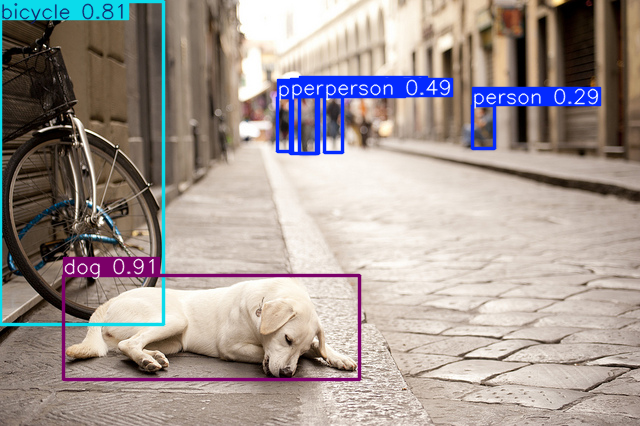


[PASS] Single image inference completed.
[PASS] Detection information extracted.
[PASS] Original image preserved.
[PASS] Annotated image saved.


In [ ]:
# ============================================================
# STEP 8.4 — SINGLE IMAGE OBJECT DETECTION TEST
# ============================================================

import json
import cv2
import torch
from pathlib import Path
from collections import Counter
from IPython.display import display
from PIL import Image

from ultralytics import YOLO

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

TRAIN_DIR = PROJECT_DIR / "data" / "raw" / "train2017"
WEIGHTS_PATH = (
    PROJECT_DIR / "models" / "pretrained" / "yolov8n.pt"
)

OUTPUT_DIR = PROJECT_DIR / "reports" / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_IMAGE = OUTPUT_DIR / "yolov8n_single_image_test.jpg"

print("=" * 65)
print("STEP 8.4 — SINGLE IMAGE OBJECT DETECTION TEST")
print("=" * 65)

# 1. Verify required resources
assert torch.cuda.is_available()
assert TRAIN_DIR.exists()
assert WEIGHTS_PATH.exists()

# 2. Load training IDs
ids_path = PROJECT_DIR / "data" / "splits" / "train_ids.json"

with open(ids_path, "r", encoding="utf-8") as f:
    train_data = json.load(f)

# Handle common JSON structures
if isinstance(train_data, dict):
    for key in ["image_ids", "ids", "images", "train_ids"]:
        if key in train_data:
            train_data = train_data[key]
            break

assert isinstance(train_data, list), "Unexpected train_ids.json structure."

# 3. Find the first existing image
selected_id = None
image_path = None

for item in train_data:

    if isinstance(item, dict):
        selected_id = item.get("image_id", item.get("id"))
        filename = item.get("file_name")

        if filename:
            candidate = TRAIN_DIR / filename
        else:
            candidate = TRAIN_DIR / f"{int(selected_id):012d}.jpg"

    else:
        selected_id = int(item)
        candidate = TRAIN_DIR / f"{selected_id:012d}.jpg"

    if candidate.exists():
        image_path = candidate
        break

assert image_path is not None, "No matching training image found."

print("\nSELECTED IMAGE")
print("-" * 50)
print("Image ID:", selected_id)
print("Image path:", image_path)

# 4. Load model
model = YOLO(str(WEIGHTS_PATH))

# 5. Run inference
results = model.predict(
    source=str(image_path),
    conf=0.25,
    imgsz=640,
    device=0,
    verbose=False,
    save=False
)

result = results[0]

# 6. Extract detections
detections = []

if result.boxes is not None:

    for box in result.boxes:

        class_id = int(box.cls.item())
        confidence = float(box.conf.item())
        coordinates = box.xyxy[0].tolist()

        detections.append({
            "image_id": int(selected_id),
            "class_id": class_id,
            "class_name": model.names[class_id],
            "confidence": round(confidence, 4),
            "bbox_xyxy": [
                round(float(value), 2)
                for value in coordinates
            ]
        })

# 7. Print detection results
print("\nDETECTION RESULTS")
print("-" * 50)

print("Total detected objects:", len(detections))

for index, detection in enumerate(detections, 1):

    print(f"\nObject {index}")
    print("Class:", detection["class_name"])
    print("Confidence:", detection["confidence"])
    print("Bounding box:", detection["bbox_xyxy"])

# 8. Class distribution
class_counts = Counter(
    item["class_name"] for item in detections
)

print("\nDETECTED CLASS COUNTS")
print("-" * 50)

for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

# 9. Save annotated image separately
annotated_image = result.plot()

success = cv2.imwrite(
    str(OUTPUT_IMAGE),
    annotated_image
)

assert success, "Failed to save annotated image."

print("\nANNOTATED IMAGE")
print("-" * 50)
print("Saved to:", OUTPUT_IMAGE)

# Display result
display(
    Image.fromarray(
        cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
    )
)

print("\n[PASS] Single image inference completed.")
print("[PASS] Detection information extracted.")
print("[PASS] Original image preserved.")
print("[PASS] Annotated image saved.")

In [ ]:
# ============================================================
# STEP 8.5 — YOLO vs COCO GROUND TRUTH
# ============================================================

import json
import torch
from pathlib import Path
from ultralytics import YOLO

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

IMAGE_ID = 74

IMAGE_PATH = (
    PROJECT_DIR / "data" / "raw" / "train2017"
    / f"{IMAGE_ID:012d}.jpg"
)

ANNOTATIONS_PATH = (
    PROJECT_DIR / "data" / "raw" / "annotations"
    / "instances_train2017.json"
)

WEIGHTS_PATH = (
    PROJECT_DIR / "models" / "pretrained" / "yolov8n.pt"
)

print("=" * 65)
print("STEP 8.5 — GROUND TRUTH COMPARISON")
print("=" * 65)

# 1. Verify files and GPU
assert torch.cuda.is_available()
assert IMAGE_PATH.exists(), f"Image not found: {IMAGE_PATH}"
assert ANNOTATIONS_PATH.exists(), (
    f"Annotations not found: {ANNOTATIONS_PATH}"
)

# 2. Load COCO annotations
print("\nLoading COCO annotations...")

with open(ANNOTATIONS_PATH, "r", encoding="utf-8") as f:
    coco = json.load(f)

categories = {
    item["id"]: item["name"]
    for item in coco["categories"]
}

# Get ground-truth objects for image 74
ground_truth = []

for annotation in coco["annotations"]:

    if annotation["image_id"] != IMAGE_ID:
        continue

    x, y, w, h = annotation["bbox"]

    ground_truth.append({
        "class_name": categories[annotation["category_id"]],
        "bbox": [x, y, x + w, y + h],
        "iscrowd": annotation.get("iscrowd", 0)
    })

# 3. Run YOLO again with the same settings
model = YOLO(str(WEIGHTS_PATH))

results = model.predict(
    source=str(IMAGE_PATH),
    conf=0.25,
    imgsz=640,
    device=0,
    verbose=False
)

result = results[0]

detections = []

if result.boxes is not None:

    for box in result.boxes:

        class_id = int(box.cls.item())

        detections.append({
            "class_name": model.names[class_id],
            "confidence": float(box.conf.item()),
            "bbox": box.xyxy[0].tolist()
        })

# 4. Calculate Intersection over Union
def calculate_iou(box_a, box_b):

    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])
    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])

    intersection = (
        max(0, x2 - x1) *
        max(0, y2 - y1)
    )

    area_a = (
        max(0, box_a[2] - box_a[0]) *
        max(0, box_a[3] - box_a[1])
    )

    area_b = (
        max(0, box_b[2] - box_b[0]) *
        max(0, box_b[3] - box_b[1])
    )

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0


# 5. Build same-class matching candidates
candidates = []

for det_idx, detection in enumerate(detections):

    for gt_idx, gt in enumerate(ground_truth):

        if detection["class_name"] != gt["class_name"]:
            continue

        iou = calculate_iou(
            detection["bbox"],
            gt["bbox"]
        )

        candidates.append((iou, det_idx, gt_idx))

# Greedy one-to-one matching
candidates.sort(reverse=True)

matched_detections = set()
matched_ground_truth = set()
matches = []

IOU_THRESHOLD = 0.50

for iou, det_idx, gt_idx in candidates:

    if iou < IOU_THRESHOLD:
        break

    if det_idx in matched_detections:
        continue

    if gt_idx in matched_ground_truth:
        continue

    matched_detections.add(det_idx)
    matched_ground_truth.add(gt_idx)

    matches.append({
        "class_name": detections[det_idx]["class_name"],
        "confidence": round(
            detections[det_idx]["confidence"], 4
        ),
        "iou": round(iou, 4)
    })

# 6. Display ground truth
print("\nGROUND TRUTH OBJECTS")
print("-" * 50)

print("Total:", len(ground_truth))

for i, gt in enumerate(ground_truth, 1):
    print(
        f"{i}. {gt['class_name']} | "
        f"BBox: {[round(v, 2) for v in gt['bbox']]}"
    )

# 7. Display YOLO detections
print("\nYOLO DETECTIONS")
print("-" * 50)

print("Total:", len(detections))

for i, det in enumerate(detections, 1):
    print(
        f"{i}. {det['class_name']} | "
        f"Confidence: {det['confidence']:.4f}"
    )

# 8. Display matching results
print("\nMATCHED DETECTIONS — IoU >= 0.50")
print("-" * 50)

for match in matches:
    print(match)

# 9. Summary
true_positives = len(matches)
false_positives = len(detections) - true_positives
false_negatives = len(ground_truth) - true_positives

precision = (
    true_positives / len(detections)
    if detections else 0
)

recall = (
    true_positives / len(ground_truth)
    if ground_truth else 0
)

print("\nCOMPARISON SUMMARY")
print("-" * 50)

print("Ground truth objects:", len(ground_truth))
print("YOLO detections:", len(detections))
print("Matched detections:", true_positives)
print("Unmatched detections:", false_positives)
print("Undetected ground-truth objects:", false_negatives)

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

print("\n[PASS] Ground truth comparison completed.")

STEP 8.5 — GROUND TRUTH COMPARISON

Loading COCO annotations...

GROUND TRUTH OBJECTS
--------------------------------------------------
Total: 8
1. dog | BBox: [61.87, 276.25, 358.29, 379.43]
2. bicycle | BBox: [2.75, 3.66, 162.15, 316.06]
3. person | BBox: [295.55, 93.96, 313.97, 152.79]
4. person | BBox: [326.94, 97.05, 340.49, 122.98]
5. person | BBox: [356.62, 95.47, 372.33, 147.55]
6. person | BBox: [462.08, 105.09, 493.74, 146.99]
7. person | BBox: [277.11, 103.84, 292.44, 150.72]
8. person | BBox: [282.65, 103.41, 294.34, 127.66]

YOLO DETECTIONS
--------------------------------------------------
Total: 7
1. dog | Confidence: 0.9110
2. bicycle | Confidence: 0.8111
3. person | Confidence: 0.4911
4. person | Confidence: 0.3188
5. person | Confidence: 0.2950
6. person | Confidence: 0.2860
7. person | Confidence: 0.2650

MATCHED DETECTIONS — IoU >= 0.50
--------------------------------------------------
{'class_name': 'dog', 'confidence': 0.911, 'iou': 0.9884}
{'class_name': 'bicyc

### Historical implementation — superseded

The following initial Step 8.6 implementation is retained for traceability only. It used incompatible COCO category IDs and YOLO class indices. **Do not use its metrics.** The corrected Step 8.6 cell immediately after it matches classes by class name and is the authoritative result.

In [ ]:

# ================================================================
# SUPERSEDED — STEP 8.6 INITIAL VERSION (DO NOT USE RESULTS)
# This implementation compared COCO category IDs with YOLO class IDs.
# The corrected implementation is in the next cell (STEP 8.6 — CORRECTED EVALUATION).
# ================================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

print("=" * 65)
print("STEP 8.6 — SMALL BATCH EVALUATION")
print("=" * 65)

# ------------------------------------------------
# 1. PATHS AND SETTINGS
# ------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/Image_Captioning_Phase1")

TRAIN_DIR = PROJECT_DIR / "data/raw/train2017"
ANNOTATIONS_PATH = PROJECT_DIR / "data/raw/annotations/instances_train2017.json"
TRAIN_IDS_PATH = PROJECT_DIR / "data/splits/train_ids.json"
WEIGHTS_PATH = PROJECT_DIR / "models/pretrained/yolov8n.pt"

REPORTS_DIR = PROJECT_DIR / "reports"
TABLES_DIR = REPORTS_DIR / "tables"

TABLES_DIR.mkdir(parents=True, exist_ok=True)

CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50
IMAGE_SIZE = 640
BATCH_SIZE = 20

# ------------------------------------------------
# 2. LOAD TRAIN IMAGE IDS
# ------------------------------------------------

with open(TRAIN_IDS_PATH, "r") as f:
    train_data = json.load(f)

if isinstance(train_data, list):
    if train_data and isinstance(train_data[0], dict):
        train_ids = [
            int(x.get("image_id", x.get("id")))
            for x in train_data
        ]
    else:
        train_ids = [int(x) for x in train_data]

elif isinstance(train_data, dict):
    possible_keys = ["image_ids", "train_ids", "ids"]
    selected_key = next(
        (k for k in possible_keys if k in train_data),
        None
    )

    if selected_key is None:
        raise ValueError(
            "Could not identify image IDs in train_ids.json"
        )

    train_ids = [int(x) for x in train_data[selected_key]]

else:
    raise ValueError("Unsupported train_ids.json format")

image_ids = train_ids[:BATCH_SIZE]

print(f"\nSelected images: {len(image_ids)}")

# ------------------------------------------------
# 3. LOAD COCO GROUND TRUTH
# ------------------------------------------------

print("\nLoading COCO annotations...")

with open(ANNOTATIONS_PATH, "r") as f:
    coco_data = json.load(f)

categories = {
    int(cat["id"]): cat["name"]
    for cat in coco_data["categories"]
}

selected_set = set(image_ids)

ground_truth = {
    image_id: []
    for image_id in image_ids
}

for ann in coco_data["annotations"]:

    image_id = int(ann["image_id"])

    if image_id not in selected_set:
        continue

    # Exclude crowd annotations from this diagnostic evaluation.
    if ann.get("iscrowd", 0) == 1:
        continue

    x, y, w, h = ann["bbox"]

    ground_truth[image_id].append({
        "class_id": int(ann["category_id"]),
        "class_name": categories[int(ann["category_id"])],
        "bbox": [x, y, x + w, y + h]
    })

print("[OK] Ground truth loaded.")

# ------------------------------------------------
# 4. LOAD YOLO MODEL
# ------------------------------------------------

model = YOLO(str(WEIGHTS_PATH))

print("[OK] YOLOv8n loaded.")

# ------------------------------------------------
# 5. IOU FUNCTION
# ------------------------------------------------

def calculate_iou(box_a, box_b):

    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])

    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = max(0, box_a[2] - box_a[0]) * max(
        0, box_a[3] - box_a[1]
    )

    area_b = max(0, box_b[2] - box_b[0]) * max(
        0, box_b[3] - box_b[1]
    )

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0

# ------------------------------------------------
# 6. RUN DETECTION AND MATCHING
# ------------------------------------------------

results_per_image = []

total_tp = 0
total_fp = 0
total_fn = 0

for index, image_id in enumerate(image_ids, start=1):

    image_path = TRAIN_DIR / f"{image_id:012d}.jpg"

    if not image_path.exists():
        print(f"[WARNING] Missing image: {image_id}")
        continue

    result = model.predict(
        source=str(image_path),
        conf=CONF_THRESHOLD,
        imgsz=IMAGE_SIZE,
        device=0,
        verbose=False
    )[0]

    detections = []

    for box in result.boxes:

        class_id = int(box.cls[0].item())
        confidence = float(box.conf[0].item())

        bbox = box.xyxy[0].cpu().tolist()

        detections.append({
            "class_id": class_id,
            "class_name": model.names[class_id],
            "confidence": confidence,
            "bbox": [float(v) for v in bbox]
        })

    gt_objects = ground_truth[image_id]

    # Match detections in descending confidence order.
    detections.sort(
        key=lambda x: x["confidence"],
        reverse=True
    )

    matched_gt = set()
    matched_pairs = []

    tp = 0
    fp = 0

    for det in detections:

        best_iou = 0.0
        best_gt_index = None

        for gt_index, gt in enumerate(gt_objects):

            if gt_index in matched_gt:
                continue

            if det["class_id"] != gt["class_id"]:
                continue

            iou = calculate_iou(
                det["bbox"],
                gt["bbox"]
            )

            if iou > best_iou:
                best_iou = iou
                best_gt_index = gt_index

        if (
            best_gt_index is not None
            and best_iou >= IOU_THRESHOLD
        ):

            tp += 1
            matched_gt.add(best_gt_index)

            matched_pairs.append({
                "class_name": det["class_name"],
                "confidence": round(det["confidence"], 4),
                "iou": round(best_iou, 4)
            })

        else:
            fp += 1

    fn = len(gt_objects) - len(matched_gt)

    total_tp += tp
    total_fp += fp
    total_fn += fn

    results_per_image.append({
        "image_id": image_id,
        "ground_truth": len(gt_objects),
        "detections": len(detections),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "matched_pairs": matched_pairs,
        "detections_details": detections
    })

    print(
        f"[{index:02d}/{len(image_ids)}] "
        f"Image {image_id} | "
        f"GT={len(gt_objects)} | "
        f"Det={len(detections)} | "
        f"TP={tp} FP={fp} FN={fn}"
    )

# ------------------------------------------------
# 7. AGGREGATE METRICS
# ------------------------------------------------

precision = (
    total_tp / (total_tp + total_fp)
    if total_tp + total_fp > 0 else 0.0
)

recall = (
    total_tp / (total_tp + total_fn)
    if total_tp + total_fn > 0 else 0.0
)

f1_score = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0 else 0.0
)

summary = {
    "images_evaluated": len(results_per_image),
    "confidence_threshold": CONF_THRESHOLD,
    "iou_threshold": IOU_THRESHOLD,
    "image_size": IMAGE_SIZE,
    "ground_truth_objects": total_tp + total_fn,
    "total_detections": total_tp + total_fp,
    "TP": total_tp,
    "FP": total_fp,
    "FN": total_fn,
    "precision": precision,
    "recall": recall,
    "f1_score": f1_score
}

# ------------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------------

report = {
    "step": "8.6",
    "model": "YOLOv8n",
    "evaluation_type": "Small batch diagnostic",
    "summary": summary,
    "per_image_results": results_per_image
}

json_path = REPORTS_DIR / "yolo_small_batch_evaluation.json"

with open(json_path, "w") as f:
    json.dump(report, f, indent=4)

csv_path = TABLES_DIR / "yolo_small_batch_per_image.csv"

pd.DataFrame([
    {
        "image_id": r["image_id"],
        "ground_truth": r["ground_truth"],
        "detections": r["detections"],
        "TP": r["TP"],
        "FP": r["FP"],
        "FN": r["FN"]
    }
    for r in results_per_image
]).to_csv(csv_path, index=False)

# ------------------------------------------------
# 9. DISPLAY FINAL SUMMARY
# ------------------------------------------------

print("\n" + "=" * 65)
print("SMALL BATCH EVALUATION SUMMARY")
print("=" * 65)

for key, value in summary.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("\nSAVED FILES")
print(json_path)
print(csv_path)

print("\n[PASS] STEP 8.6 completed.")


STEP 8.6 — SMALL BATCH EVALUATION

Selected images: 20

Loading COCO annotations...
[OK] Ground truth loaded.
[OK] YOLOv8n loaded.
[01/20] Image 74 | GT=8 | Det=7 | TP=0 FP=7 FN=8
[02/20] Image 113 | GT=18 | Det=9 | TP=0 FP=9 FN=18
[03/20] Image 133 | GT=2 | Det=1 | TP=0 FP=1 FN=2
[04/20] Image 136 | GT=4 | Det=5 | TP=0 FP=5 FN=4
[05/20] Image 196 | GT=42 | Det=22 | TP=0 FP=22 FN=42
[06/20] Image 321 | GT=3 | Det=5 | TP=0 FP=5 FN=3
[07/20] Image 415 | GT=2 | Det=2 | TP=0 FP=2 FN=2
[08/20] Image 488 | GT=10 | Det=8 | TP=0 FP=8 FN=10
[09/20] Image 490 | GT=2 | Det=2 | TP=0 FP=2 FN=2
[10/20] Image 514 | GT=1 | Det=0 | TP=0 FP=0 FN=1
[11/20] Image 584 | GT=14 | Det=6 | TP=0 FP=6 FN=14
[12/20] Image 595 | GT=1 | Det=1 | TP=0 FP=1 FN=1
[13/20] Image 711 | GT=16 | Det=7 | TP=0 FP=7 FN=16
[14/20] Image 735 | GT=8 | Det=3 | TP=0 FP=3 FN=8
[15/20] Image 772 | GT=3 | Det=2 | TP=0 FP=2 FN=3
[16/20] Image 825 | GT=1 | Det=2 | TP=0 FP=2 FN=1
[17/20] Image 902 | GT=4 | Det=5 | TP=0 FP=5 FN=4
[18/20] 

In [ ]:

# ================================================================
# STEP 8.6 — CORRECTED EVALUATION
# Match classes by NAME instead of category ID
# ================================================================

import json
import pandas as pd
from pathlib import Path

print("=" * 65)
print("STEP 8.6 — CORRECTED SMALL BATCH EVALUATION")
print("=" * 65)

PROJECT_DIR = Path("/content/drive/MyDrive/Image_Captioning_Phase1")

ANNOTATIONS_PATH = (
    PROJECT_DIR / "data/raw/annotations/instances_train2017.json"
)

OLD_REPORT_PATH = (
    PROJECT_DIR / "reports/yolo_small_batch_evaluation.json"
)

REPORTS_DIR = PROJECT_DIR / "reports"
TABLES_DIR = REPORTS_DIR / "tables"

IOU_THRESHOLD = 0.50

# ------------------------------------------------
# 1. LOAD PREVIOUS DETECTIONS
# ------------------------------------------------

with open(OLD_REPORT_PATH, "r") as f:
    old_report = json.load(f)

previous_results = old_report["per_image_results"]

print(f"\nLoaded detections for {len(previous_results)} images.")

# ------------------------------------------------
# 2. LOAD COCO GROUND TRUTH
# ------------------------------------------------

print("\nLoading COCO annotations...")

with open(ANNOTATIONS_PATH, "r") as f:
    coco_data = json.load(f)

categories = {
    int(cat["id"]): cat["name"]
    for cat in coco_data["categories"]
}

image_ids = [
    int(item["image_id"])
    for item in previous_results
]

selected_set = set(image_ids)

ground_truth = {
    image_id: []
    for image_id in image_ids
}

for ann in coco_data["annotations"]:

    image_id = int(ann["image_id"])

    if image_id not in selected_set:
        continue

    if ann.get("iscrowd", 0) == 1:
        continue

    x, y, w, h = ann["bbox"]

    ground_truth[image_id].append({
        "class_name": categories[int(ann["category_id"])],
        "bbox": [x, y, x + w, y + h]
    })

print("[OK] Ground truth loaded.")

# ------------------------------------------------
# 3. IOU FUNCTION
# ------------------------------------------------

def calculate_iou(box_a, box_b):

    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])

    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = (
        max(0, box_a[2] - box_a[0]) *
        max(0, box_a[3] - box_a[1])
    )

    area_b = (
        max(0, box_b[2] - box_b[0]) *
        max(0, box_b[3] - box_b[1])
    )

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0

# ------------------------------------------------
# 4. MATCH BY CLASS NAME
# ------------------------------------------------

corrected_results = []

total_tp = 0
total_fp = 0
total_fn = 0

for item in previous_results:

    image_id = int(item["image_id"])

    detections = item["detections_details"]
    gt_objects = ground_truth[image_id]

    detections = sorted(
        detections,
        key=lambda x: x["confidence"],
        reverse=True
    )

    matched_gt = set()
    matched_pairs = []

    tp = 0
    fp = 0

    for det in detections:

        best_iou = 0.0
        best_gt_index = None

        for gt_index, gt in enumerate(gt_objects):

            if gt_index in matched_gt:
                continue

            # IMPORTANT: Compare class names, not class IDs.
            if det["class_name"] != gt["class_name"]:
                continue

            iou = calculate_iou(
                det["bbox"],
                gt["bbox"]
            )

            if iou > best_iou:
                best_iou = iou
                best_gt_index = gt_index

        if (
            best_gt_index is not None
            and best_iou >= IOU_THRESHOLD
        ):

            tp += 1
            matched_gt.add(best_gt_index)

            matched_pairs.append({
                "class_name": det["class_name"],
                "confidence": round(det["confidence"], 4),
                "iou": round(best_iou, 4)
            })

        else:
            fp += 1

    fn = len(gt_objects) - len(matched_gt)

    total_tp += tp
    total_fp += fp
    total_fn += fn

    corrected_results.append({
        "image_id": image_id,
        "ground_truth": len(gt_objects),
        "detections": len(detections),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "matched_pairs": matched_pairs
    })

    print(
        f"Image {image_id} | "
        f"GT={len(gt_objects)} | "
        f"Det={len(detections)} | "
        f"TP={tp} FP={fp} FN={fn}"
    )

# ------------------------------------------------
# 5. CALCULATE METRICS
# ------------------------------------------------

precision = (
    total_tp / (total_tp + total_fp)
    if total_tp + total_fp > 0 else 0.0
)

recall = (
    total_tp / (total_tp + total_fn)
    if total_tp + total_fn > 0 else 0.0
)

f1_score = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0 else 0.0
)

summary = {
    "images_evaluated": len(corrected_results),
    "confidence_threshold": 0.25,
    "iou_threshold": IOU_THRESHOLD,
    "ground_truth_objects": total_tp + total_fn,
    "total_detections": total_tp + total_fp,
    "TP": total_tp,
    "FP": total_fp,
    "FN": total_fn,
    "precision": precision,
    "recall": recall,
    "f1_score": f1_score
}

# ------------------------------------------------
# 6. SAVE CORRECTED RESULTS
# ------------------------------------------------

corrected_report = {
    "step": "8.6",
    "model": "YOLOv8n",
    "evaluation_type": "Small batch diagnostic",
    "matching_method": "Class name + IoU",
    "summary": summary,
    "per_image_results": corrected_results
}

json_path = (
    REPORTS_DIR / "yolo_small_batch_evaluation_corrected.json"
)

with open(json_path, "w") as f:
    json.dump(corrected_report, f, indent=4)

csv_path = (
    TABLES_DIR / "yolo_small_batch_per_image_corrected.csv"
)

pd.DataFrame(corrected_results).drop(
    columns=["matched_pairs"]
).to_csv(csv_path, index=False)

# ------------------------------------------------
# 7. DISPLAY SUMMARY
# ------------------------------------------------

print("\n" + "=" * 65)
print("CORRECTED EVALUATION SUMMARY")
print("=" * 65)

for key, value in summary.items():

    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("\nSAVED FILES")
print(json_path)
print(csv_path)

print("\n[PASS] Corrected evaluation completed.")



STEP 8.6 — CORRECTED SMALL BATCH EVALUATION

Loaded detections for 20 images.

Loading COCO annotations...
[OK] Ground truth loaded.
Image 74 | GT=8 | Det=7 | TP=5 FP=2 FN=3
Image 113 | GT=18 | Det=9 | TP=8 FP=1 FN=10
Image 133 | GT=2 | Det=1 | TP=1 FP=0 FN=1
Image 136 | GT=4 | Det=5 | TP=4 FP=1 FN=0
Image 196 | GT=42 | Det=22 | TP=16 FP=6 FN=26
Image 321 | GT=3 | Det=5 | TP=2 FP=3 FN=1
Image 415 | GT=2 | Det=2 | TP=2 FP=0 FN=0
Image 488 | GT=10 | Det=8 | TP=7 FP=1 FN=3
Image 490 | GT=2 | Det=2 | TP=2 FP=0 FN=0
Image 514 | GT=1 | Det=0 | TP=0 FP=0 FN=1
Image 584 | GT=14 | Det=6 | TP=4 FP=2 FN=10
Image 595 | GT=1 | Det=1 | TP=1 FP=0 FN=0
Image 711 | GT=16 | Det=7 | TP=5 FP=2 FN=11
Image 735 | GT=8 | Det=3 | TP=2 FP=1 FN=6
Image 772 | GT=3 | Det=2 | TP=2 FP=0 FN=1
Image 825 | GT=1 | Det=2 | TP=1 FP=1 FN=0
Image 902 | GT=4 | Det=5 | TP=3 FP=2 FN=1
Image 962 | GT=3 | Det=2 | TP=2 FP=0 FN=1
Image 1025 | GT=1 | Det=1 | TP=1 FP=0 FN=0
Image 1036 | GT=3 | Det=4 | TP=3 FP=1 FN=0

CORRECTED EVAL

In [ ]:

# ================================================================
# STEP 8.7 — CONFIDENCE THRESHOLD ANALYSIS
# ================================================================

import json
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

print("=" * 70)
print("STEP 8.7 — CONFIDENCE THRESHOLD ANALYSIS")
print("=" * 70)

# ------------------------------------------------
# 1. PATHS AND CONFIGURATION
# ------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/Image_Captioning_Phase1")

TRAIN_DIR = PROJECT_DIR / "data/raw/train2017"

ANNOTATIONS_PATH = (
    PROJECT_DIR / "data/raw/annotations/instances_train2017.json"
)

PREVIOUS_REPORT = (
    PROJECT_DIR / "reports/yolo_small_batch_evaluation_corrected.json"
)

WEIGHTS_PATH = (
    PROJECT_DIR / "models/pretrained/yolov8n.pt"
)

REPORTS_DIR = PROJECT_DIR / "reports"
TABLES_DIR = REPORTS_DIR / "tables"

TABLES_DIR.mkdir(parents=True, exist_ok=True)

LOWEST_CONFIDENCE = 0.001
IOU_THRESHOLD = 0.50
IMAGE_SIZE = 640

CONFIDENCE_THRESHOLDS = [
    0.10,
    0.15,
    0.25,
    0.35,
    0.50
]

# ------------------------------------------------
# 2. LOAD THE 20 IMAGE IDS
# ------------------------------------------------

with open(PREVIOUS_REPORT, "r") as f:
    previous_data = json.load(f)

image_ids = [
    int(item["image_id"])
    for item in previous_data["per_image_results"]
]

print(f"\nImages selected: {len(image_ids)}")

# ------------------------------------------------
# 3. LOAD COCO GROUND TRUTH
# ------------------------------------------------

print("\nLoading COCO annotations...")

with open(ANNOTATIONS_PATH, "r") as f:
    coco_data = json.load(f)

categories = {
    int(cat["id"]): cat["name"]
    for cat in coco_data["categories"]
}

selected_ids = set(image_ids)

ground_truth = {
    image_id: []
    for image_id in image_ids
}

for ann in coco_data["annotations"]:

    image_id = int(ann["image_id"])

    if image_id not in selected_ids:
        continue

    # Exclude crowd annotations consistently.
    if ann.get("iscrowd", 0) == 1:
        continue

    x, y, w, h = ann["bbox"]

    ground_truth[image_id].append({
        "class_name": categories[int(ann["category_id"])],
        "bbox": [x, y, x + w, y + h]
    })

print("[OK] Ground truth loaded.")

# ------------------------------------------------
# 4. LOAD YOLO MODEL
# ------------------------------------------------

model = YOLO(str(WEIGHTS_PATH))

print("[OK] YOLOv8n loaded.")

# ------------------------------------------------
# 5. RUN INFERENCE ONCE AT LOW CONFIDENCE
# ------------------------------------------------

print("\nRunning inference with confidence = 0.001")

all_predictions = {}

for index, image_id in enumerate(image_ids, start=1):

    image_path = TRAIN_DIR / f"{image_id:012d}.jpg"

    if not image_path.exists():
        raise FileNotFoundError(
            f"Missing image: {image_path}"
        )

    result = model.predict(
        source=str(image_path),
        conf=LOWEST_CONFIDENCE,
        imgsz=IMAGE_SIZE,
        device=0,
        verbose=False
    )[0]

    predictions = []

    for box in result.boxes:

        class_id = int(box.cls[0].item())
        confidence = float(box.conf[0].item())
        bbox = box.xyxy[0].cpu().tolist()

        predictions.append({
            "class_name": model.names[class_id],
            "confidence": confidence,
            "bbox": [float(v) for v in bbox]
        })

    all_predictions[image_id] = predictions

    print(
        f"[{index:02d}/{len(image_ids)}] "
        f"Image {image_id} | "
        f"Raw predictions: {len(predictions)}"
    )

print("\n[OK] Inference completed.")

# ------------------------------------------------
# 6. IOU FUNCTION
# ------------------------------------------------

def calculate_iou(box_a, box_b):

    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])

    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = (
        max(0, box_a[2] - box_a[0]) *
        max(0, box_a[3] - box_a[1])
    )

    area_b = (
        max(0, box_b[2] - box_b[0]) *
        max(0, box_b[3] - box_b[1])
    )

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0

# ------------------------------------------------
# 7. EVALUATION FUNCTION
# ------------------------------------------------

def evaluate_threshold(conf_threshold):

    total_tp = 0
    total_fp = 0
    total_fn = 0

    per_image = []

    for image_id in image_ids:

        detections = [
            det for det in all_predictions[image_id]
            if det["confidence"] >= conf_threshold
        ]

        detections.sort(
            key=lambda x: x["confidence"],
            reverse=True
        )

        gt_objects = ground_truth[image_id]

        matched_gt = set()

        tp = 0
        fp = 0

        for det in detections:

            best_iou = 0.0
            best_gt_index = None

            for gt_index, gt in enumerate(gt_objects):

                if gt_index in matched_gt:
                    continue

                if det["class_name"] != gt["class_name"]:
                    continue

                iou = calculate_iou(
                    det["bbox"],
                    gt["bbox"]
                )

                if iou > best_iou:
                    best_iou = iou
                    best_gt_index = gt_index

            if (
                best_gt_index is not None
                and best_iou >= IOU_THRESHOLD
            ):
                tp += 1
                matched_gt.add(best_gt_index)
            else:
                fp += 1

        fn = len(gt_objects) - len(matched_gt)

        total_tp += tp
        total_fp += fp
        total_fn += fn

        per_image.append({
            "image_id": image_id,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "detections": len(detections),
            "ground_truth": len(gt_objects)
        })

    precision = (
        total_tp / (total_tp + total_fp)
        if total_tp + total_fp > 0 else 0.0
    )

    recall = (
        total_tp / (total_tp + total_fn)
        if total_tp + total_fn > 0 else 0.0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0.0
    )

    return {
        "confidence_threshold": conf_threshold,
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,
        "total_detections": total_tp + total_fp,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "per_image_results": per_image
    }

# ------------------------------------------------
# 8. EVALUATE ALL THRESHOLDS
# ------------------------------------------------

print("\nEvaluating confidence thresholds...")

threshold_results = []

for threshold in CONFIDENCE_THRESHOLDS:

    result = evaluate_threshold(threshold)

    threshold_results.append(result)

    print(
        f"\nConfidence: {threshold:.2f} | "
        f"TP: {result['TP']} | "
        f"FP: {result['FP']} | "
        f"FN: {result['FN']} | "
        f"Precision: {result['precision']:.4f} | "
        f"Recall: {result['recall']:.4f} | "
        f"F1: {result['f1_score']:.4f}"
    )

# ------------------------------------------------
# 9. SELECT BEST THRESHOLD BY F1
# ------------------------------------------------

best_result = max(
    threshold_results,
    key=lambda x: x["f1_score"]
)

# ------------------------------------------------
# 10. SAVE RESULTS
# ------------------------------------------------

summary_rows = []

for result in threshold_results:

    summary_rows.append({
        "confidence_threshold": result["confidence_threshold"],
        "TP": result["TP"],
        "FP": result["FP"],
        "FN": result["FN"],
        "total_detections": result["total_detections"],
        "precision": result["precision"],
        "recall": result["recall"],
        "f1_score": result["f1_score"]
    })

summary_df = pd.DataFrame(summary_rows)

csv_path = (
    TABLES_DIR / "yolo_confidence_threshold_analysis.csv"
)

summary_df.to_csv(csv_path, index=False)

json_report = {
    "step": "8.7",
    "model": "YOLOv8n",
    "images_evaluated": len(image_ids),
    "image_size": IMAGE_SIZE,
    "inference_confidence": LOWEST_CONFIDENCE,
    "iou_threshold": IOU_THRESHOLD,
    "threshold_results": threshold_results,
    "best_threshold_by_f1": best_result["confidence_threshold"]
}

json_path = (
    REPORTS_DIR / "yolo_confidence_threshold_analysis.json"
)

with open(json_path, "w") as f:
    json.dump(json_report, f, indent=4)

# ------------------------------------------------
# 11. FINAL COMPARISON TABLE
# ------------------------------------------------

print("\n" + "=" * 70)
print("CONFIDENCE THRESHOLD COMPARISON")
print("=" * 70)

print(
    summary_df.to_string(
        index=False,
        formatters={
            "precision": "{:.4f}".format,
            "recall": "{:.4f}".format,
            "f1_score": "{:.4f}".format
        }
    )
)

print("\n" + "=" * 70)
print("BEST THRESHOLD")
print("=" * 70)

print(
    f"Best confidence threshold by F1: "
    f"{best_result['confidence_threshold']:.2f}"
)

print(f"Best F1-score: {best_result['f1_score']:.4f}")

print("\nSAVED FILES")
print(json_path)
print(csv_path)

print("\n[PASS] STEP 8.7 completed.")


STEP 8.7 — CONFIDENCE THRESHOLD ANALYSIS

Images selected: 20

Loading COCO annotations...
[OK] Ground truth loaded.
[OK] YOLOv8n loaded.

Running inference with confidence = 0.001
[01/20] Image 74 | Raw predictions: 145
[02/20] Image 113 | Raw predictions: 297
[03/20] Image 133 | Raw predictions: 110
[04/20] Image 136 | Raw predictions: 39
[05/20] Image 196 | Raw predictions: 300
[06/20] Image 321 | Raw predictions: 113
[07/20] Image 415 | Raw predictions: 16
[08/20] Image 488 | Raw predictions: 104
[09/20] Image 490 | Raw predictions: 66
[10/20] Image 514 | Raw predictions: 37
[11/20] Image 584 | Raw predictions: 300
[12/20] Image 595 | Raw predictions: 27
[13/20] Image 711 | Raw predictions: 266
[14/20] Image 735 | Raw predictions: 273
[15/20] Image 772 | Raw predictions: 25
[16/20] Image 825 | Raw predictions: 48
[17/20] Image 902 | Raw predictions: 110
[18/20] Image 962 | Raw predictions: 20
[19/20] Image 1025 | Raw predictions: 10
[20/20] Image 1036 | Raw predictions: 115

[OK] I

In [ ]:

# ================================================================
# STEP 8.8 — 100 IMAGE STRATIFIED EVALUATION
# ================================================================

import json
import random
import pandas as pd
from pathlib import Path
from collections import Counter
from ultralytics import YOLO

print("=" * 70)
print("STEP 8.8 — 100 IMAGE STRATIFIED EVALUATION")
print("=" * 70)

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/Image_Captioning_Phase1")

TRAIN_DIR = PROJECT_DIR / "data/raw/train2017"
ANNOTATIONS_PATH = PROJECT_DIR / "data/raw/annotations/instances_train2017.json"
TRAIN_IDS_PATH = PROJECT_DIR / "data/splits/train_ids.json"
WEIGHTS_PATH = PROJECT_DIR / "models/pretrained/yolov8n.pt"

REPORTS_DIR = PROJECT_DIR / "reports"
TABLES_DIR = REPORTS_DIR / "tables"

TABLES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
SAMPLES_PER_GROUP = 25

LOWEST_CONFIDENCE = 0.001
IOU_THRESHOLD = 0.50
IMAGE_SIZE = 640
MAX_DETECTIONS = 1000

CONFIDENCE_THRESHOLDS = [0.10, 0.15, 0.25, 0.35, 0.50]

random.seed(RANDOM_SEED)

# ------------------------------------------------
# 2. LOAD TRAIN IDS
# ------------------------------------------------

with open(TRAIN_IDS_PATH, "r") as f:
    train_data = json.load(f)

if isinstance(train_data, list):
    if train_data and isinstance(train_data[0], dict):
        train_ids = [
            int(x.get("image_id", x.get("id")))
            for x in train_data
        ]
    else:
        train_ids = [int(x) for x in train_data]

elif isinstance(train_data, dict):
    possible_keys = ["image_ids", "train_ids", "ids"]
    selected_key = next(
        (k for k in possible_keys if k in train_data),
        None
    )

    if selected_key is None:
        raise ValueError("Could not identify IDs in train_ids.json")

    train_ids = [int(x) for x in train_data[selected_key]]

else:
    raise ValueError("Unsupported train_ids.json format")

print(f"\nTraining IDs loaded: {len(train_ids)}")

# ------------------------------------------------
# 3. LOAD COCO ANNOTATIONS
# ------------------------------------------------

print("\nLoading COCO annotations...")

with open(ANNOTATIONS_PATH, "r") as f:
    coco_data = json.load(f)

categories = {
    int(cat["id"]): cat["name"]
    for cat in coco_data["categories"]
}

train_set = set(train_ids)

# Count non-crowd objects per image.
object_counts = Counter()

for ann in coco_data["annotations"]:

    image_id = int(ann["image_id"])

    if image_id not in train_set:
        continue

    if ann.get("iscrowd", 0) == 1:
        continue

    object_counts[image_id] += 1

# Include images with zero annotations.
for image_id in train_ids:
    object_counts.setdefault(image_id, 0)

print("[OK] Object counts prepared.")

# ------------------------------------------------
# 4. CREATE STRATIFIED GROUPS
# ------------------------------------------------

groups = {
    "Simple_0_2": [],
    "Medium_3_5": [],
    "Complex_6_10": [],
    "Very_Complex_11_plus": []
}

for image_id in train_ids:

    count = object_counts[image_id]

    if count <= 2:
        groups["Simple_0_2"].append(image_id)

    elif count <= 5:
        groups["Medium_3_5"].append(image_id)

    elif count <= 10:
        groups["Complex_6_10"].append(image_id)

    else:
        groups["Very_Complex_11_plus"].append(image_id)

# Verify enough images exist in each group.
for group_name, ids in groups.items():

    print(f"{group_name}: {len(ids)} available")

    if len(ids) < SAMPLES_PER_GROUP:
        raise ValueError(
            f"Not enough images in {group_name}"
        )

# Select 25 images from each group.
selected_groups = {}

for group_name, ids in groups.items():

    selected_groups[group_name] = random.sample(
        ids,
        SAMPLES_PER_GROUP
    )

image_ids = []

for ids in selected_groups.values():
    image_ids.extend(ids)

assert len(image_ids) == 100
assert len(set(image_ids)) == 100

print("\n[OK] 100 unique images selected.")

# ------------------------------------------------
# 5. PREPARE GROUND TRUTH
# ------------------------------------------------

ground_truth = {
    image_id: []
    for image_id in image_ids
}

selected_set = set(image_ids)

for ann in coco_data["annotations"]:

    image_id = int(ann["image_id"])

    if image_id not in selected_set:
        continue

    if ann.get("iscrowd", 0) == 1:
        continue

    x, y, w, h = ann["bbox"]

    ground_truth[image_id].append({
        "class_name": categories[int(ann["category_id"])],
        "bbox": [x, y, x + w, y + h]
    })

# ------------------------------------------------
# 6. LOAD YOLO MODEL
# ------------------------------------------------

model = YOLO(str(WEIGHTS_PATH))

print("\n[OK] YOLOv8n loaded.")

# ------------------------------------------------
# 7. RUN INFERENCE WITH HIGHER MAX_DET
# ------------------------------------------------

all_predictions = {}

print("\nRunning inference...")
print(f"Confidence: {LOWEST_CONFIDENCE}")
print(f"Maximum detections per image: {MAX_DETECTIONS}")

for index, image_id in enumerate(image_ids, start=1):

    image_path = TRAIN_DIR / f"{image_id:012d}.jpg"

    if not image_path.exists():
        raise FileNotFoundError(str(image_path))

    result = model.predict(
        source=str(image_path),
        conf=LOWEST_CONFIDENCE,
        imgsz=IMAGE_SIZE,
        device=0,
        max_det=MAX_DETECTIONS,
        verbose=False
    )[0]

    predictions = []

    for box in result.boxes:

        class_id = int(box.cls[0].item())
        confidence = float(box.conf[0].item())
        bbox = box.xyxy[0].cpu().tolist()

        predictions.append({
            "class_name": model.names[class_id],
            "confidence": confidence,
            "bbox": [float(v) for v in bbox]
        })

    all_predictions[image_id] = predictions

    print(
        f"[{index:03d}/100] "
        f"Image {image_id} | "
        f"GT={len(ground_truth[image_id])} | "
        f"Raw predictions={len(predictions)}"
    )

print("\n[OK] Inference completed.")

# ------------------------------------------------
# 8. IOU FUNCTION
# ------------------------------------------------

def calculate_iou(box_a, box_b):

    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])

    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = (
        max(0, box_a[2] - box_a[0]) *
        max(0, box_a[3] - box_a[1])
    )

    area_b = (
        max(0, box_b[2] - box_b[0]) *
        max(0, box_b[3] - box_b[1])
    )

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0

# ------------------------------------------------
# 9. EVALUATION FUNCTION
# ------------------------------------------------

def evaluate_threshold(conf_threshold):

    total_tp = 0
    total_fp = 0
    total_fn = 0

    per_image = []

    for image_id in image_ids:

        detections = [
            det for det in all_predictions[image_id]
            if det["confidence"] >= conf_threshold
        ]

        detections.sort(
            key=lambda x: x["confidence"],
            reverse=True
        )

        gt_objects = ground_truth[image_id]
        matched_gt = set()

        tp = 0
        fp = 0

        for det in detections:

            best_iou = 0.0
            best_gt_index = None

            for gt_index, gt in enumerate(gt_objects):

                if gt_index in matched_gt:
                    continue

                if det["class_name"] != gt["class_name"]:
                    continue

                iou = calculate_iou(
                    det["bbox"],
                    gt["bbox"]
                )

                if iou > best_iou:
                    best_iou = iou
                    best_gt_index = gt_index

            if (
                best_gt_index is not None
                and best_iou >= IOU_THRESHOLD
            ):
                tp += 1
                matched_gt.add(best_gt_index)
            else:
                fp += 1

        fn = len(gt_objects) - len(matched_gt)

        total_tp += tp
        total_fp += fp
        total_fn += fn

        per_image.append({
            "image_id": image_id,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "detections": len(detections),
            "ground_truth": len(gt_objects)
        })

    precision = (
        total_tp / (total_tp + total_fp)
        if total_tp + total_fp > 0 else 0.0
    )

    recall = (
        total_tp / (total_tp + total_fn)
        if total_tp + total_fn > 0 else 0.0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0.0
    )

    return {
        "confidence_threshold": conf_threshold,
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,
        "total_detections": total_tp + total_fp,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "per_image_results": per_image
    }

# ------------------------------------------------
# 10. EVALUATE ALL THRESHOLDS
# ------------------------------------------------

threshold_results = []

print("\nEvaluating thresholds...")

for threshold in CONFIDENCE_THRESHOLDS:

    result = evaluate_threshold(threshold)
    threshold_results.append(result)

    print(
        f"Threshold={threshold:.2f} | "
        f"TP={result['TP']} | "
        f"FP={result['FP']} | "
        f"FN={result['FN']} | "
        f"Precision={result['precision']:.4f} | "
        f"Recall={result['recall']:.4f} | "
        f"F1={result['f1_score']:.4f}"
    )

# ------------------------------------------------
# 11. SUMMARY TABLE
# ------------------------------------------------

summary_rows = []

for result in threshold_results:

    summary_rows.append({
        "confidence_threshold": result["confidence_threshold"],
        "TP": result["TP"],
        "FP": result["FP"],
        "FN": result["FN"],
        "total_detections": result["total_detections"],
        "precision": result["precision"],
        "recall": result["recall"],
        "f1_score": result["f1_score"]
    })

summary_df = pd.DataFrame(summary_rows)

best_result = max(
    threshold_results,
    key=lambda x: x["f1_score"]
)

# ------------------------------------------------
# 12. SAVE REPORTS
# ------------------------------------------------

csv_path = (
    TABLES_DIR / "yolo_100_image_threshold_analysis.csv"
)

summary_df.to_csv(csv_path, index=False)

json_report = {
    "step": "8.8",
    "model": "YOLOv8n",
    "images_evaluated": len(image_ids),
    "random_seed": RANDOM_SEED,
    "sampling_method": "Stratified by COCO object count",
    "samples_per_group": SAMPLES_PER_GROUP,
    "groups": {
        name: {
            "selected_image_ids": ids,
            "selected_count": len(ids)
        }
        for name, ids in selected_groups.items()
    },
    "image_size": IMAGE_SIZE,
    "inference_confidence": LOWEST_CONFIDENCE,
    "max_det": MAX_DETECTIONS,
    "iou_threshold": IOU_THRESHOLD,
    "threshold_results": threshold_results,
    "best_threshold_by_f1": best_result["confidence_threshold"],
    "raw_predictions": {
        str(image_id): predictions
        for image_id, predictions in all_predictions.items()
    }
}

json_path = (
    REPORTS_DIR / "yolo_100_image_threshold_analysis.json"
)

with open(json_path, "w") as f:
    json.dump(json_report, f, indent=2)

# ------------------------------------------------
# 13. DISPLAY FINAL RESULTS
# ------------------------------------------------

print("\n" + "=" * 70)
print("100 IMAGE THRESHOLD COMPARISON")
print("=" * 70)

print(
    summary_df.to_string(
        index=False,
        formatters={
            "precision": "{:.4f}".format,
            "recall": "{:.4f}".format,
            "f1_score": "{:.4f}".format
        }
    )
)

print("\nBEST THRESHOLD BY F1:")
print(best_result["confidence_threshold"])

print("\nBEST F1-SCORE:")
print(f"{best_result['f1_score']:.4f}")

print("\nSAVED FILES:")
print(json_path)
print(csv_path)

print("\n[PASS] STEP 8.8 completed.")


STEP 8.8 — 100 IMAGE STRATIFIED EVALUATION

Training IDs loaded: 10000

Loading COCO annotations...
[OK] Object counts prepared.
Simple_0_2: 3064 available
Medium_3_5: 2716 available
Complex_6_10: 1877 available
Very_Complex_11_plus: 2343 available

[OK] 100 unique images selected.

[OK] YOLOv8n loaded.

Running inference...
Confidence: 0.001
Maximum detections per image: 1000
[001/100] Image 500356 | GT=2 | Raw predictions=137
[002/100] Image 88398 | GT=1 | Raw predictions=152
[003/100] Image 20491 | GT=2 | Raw predictions=103
[004/100] Image 576608 | GT=2 | Raw predictions=102
[005/100] Image 222206 | GT=2 | Raw predictions=163
[006/100] Image 201930 | GT=1 | Raw predictions=50
[007/100] Image 184874 | GT=0 | Raw predictions=14
[008/100] Image 112622 | GT=1 | Raw predictions=101
[009/100] Image 572250 | GT=2 | Raw predictions=45
[010/100] Image 82142 | GT=2 | Raw predictions=69
[011/100] Image 526962 | GT=2 | Raw predictions=121
[012/100] Image 575666 | GT=1 | Raw predictions=6
[013/

In [ ]:

# ================================================================
# STEP 8.9 — COMPLEXITY ANALYSIS & MAX_DET AUDIT
# ================================================================

import json
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

print("=" * 70)
print("STEP 8.9 — COMPLEXITY ANALYSIS & MAX_DET AUDIT")
print("=" * 70)

PROJECT_DIR = Path("/content/drive/MyDrive/Image_Captioning_Phase1")

REPORT_PATH = (
    PROJECT_DIR / "reports/yolo_100_image_threshold_analysis.json"
)

ANNOTATIONS_PATH = (
    PROJECT_DIR / "data/raw/annotations/instances_train2017.json"
)

TRAIN_DIR = PROJECT_DIR / "data/raw/train2017"

WEIGHTS_PATH = (
    PROJECT_DIR / "models/pretrained/yolov8n.pt"
)

REPORTS_DIR = PROJECT_DIR / "reports"
TABLES_DIR = REPORTS_DIR / "tables"

# ------------------------------------------------
# 1. LOAD STEP 8.8 REPORT
# ------------------------------------------------

with open(REPORT_PATH, "r") as f:
    report = json.load(f)

threshold_results = report["threshold_results"]
groups = report["groups"]

print("\n[OK] Previous evaluation loaded.")

# ------------------------------------------------
# 2. COMPLEXITY GROUP ANALYSIS
# ------------------------------------------------

print("\n" + "=" * 70)
print("PER-COMPLEXITY EVALUATION")
print("=" * 70)

group_rows = []

for threshold_result in threshold_results:

    threshold = threshold_result["confidence_threshold"]

    per_image = threshold_result["per_image_results"]

    for group_name, group_info in groups.items():

        group_ids = set(
            group_info["selected_image_ids"]
        )

        selected = [
            item for item in per_image
            if item["image_id"] in group_ids
        ]

        tp = sum(x["TP"] for x in selected)
        fp = sum(x["FP"] for x in selected)
        fn = sum(x["FN"] for x in selected)

        precision = (
            tp / (tp + fp)
            if tp + fp > 0 else 0.0
        )

        recall = (
            tp / (tp + fn)
            if tp + fn > 0 else 0.0
        )

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall > 0 else 0.0
        )

        group_rows.append({
            "confidence_threshold": threshold,
            "complexity_group": group_name,
            "images": len(selected),
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "precision": precision,
            "recall": recall,
            "f1_score": f1
        })

group_df = pd.DataFrame(group_rows)

for threshold in [0.15, 0.25, 0.35]:

    print(f"\n--- CONFIDENCE = {threshold:.2f} ---")

    display(
        group_df[
            group_df["confidence_threshold"] == threshold
        ].round(4)
    )

# ------------------------------------------------
# 3. SAVE COMPLEXITY RESULTS
# ------------------------------------------------

complexity_csv = (
    TABLES_DIR / "yolo_complexity_group_evaluation.csv"
)

group_df.to_csv(complexity_csv, index=False)

# ------------------------------------------------
# 4. MAX_DET AUDIT — IMAGE 337675
# ------------------------------------------------

print("\n" + "=" * 70)
print("MAX_DET AUDIT — IMAGE 337675")
print("=" * 70)

AUDIT_IMAGE_ID = 337675
AUDIT_CONFIDENCE = 0.001
EVALUATION_CONFIDENCE = 0.25
IOU_THRESHOLD = 0.50

old_predictions = report["raw_predictions"][
    str(AUDIT_IMAGE_ID)
]

print(
    f"Original raw predictions (max_det=1000): "
    f"{len(old_predictions)}"
)

# ------------------------------------------------
# 5. LOAD GROUND TRUTH FOR AUDIT IMAGE
# ------------------------------------------------

with open(ANNOTATIONS_PATH, "r") as f:
    coco_data = json.load(f)

categories = {
    int(cat["id"]): cat["name"]
    for cat in coco_data["categories"]
}

gt_objects = []

for ann in coco_data["annotations"]:

    if int(ann["image_id"]) != AUDIT_IMAGE_ID:
        continue

    if ann.get("iscrowd", 0) == 1:
        continue

    x, y, w, h = ann["bbox"]

    gt_objects.append({
        "class_name": categories[int(ann["category_id"])],
        "bbox": [x, y, x + w, y + h]
    })

# ------------------------------------------------
# 6. RUN MODEL WITH max_det=3000
# ------------------------------------------------

model = YOLO(str(WEIGHTS_PATH))

image_path = (
    TRAIN_DIR / f"{AUDIT_IMAGE_ID:012d}.jpg"
)

result = model.predict(
    source=str(image_path),
    conf=AUDIT_CONFIDENCE,
    imgsz=640,
    device=0,
    max_det=3000,
    verbose=False
)[0]

new_predictions = []

for box in result.boxes:

    class_id = int(box.cls[0].item())

    new_predictions.append({
        "class_name": model.names[class_id],
        "confidence": float(box.conf[0].item()),
        "bbox": [
            float(v)
            for v in box.xyxy[0].cpu().tolist()
        ]
    })

print(
    f"New raw predictions (max_det=3000): "
    f"{len(new_predictions)}"
)

# ------------------------------------------------
# 7. IOU FUNCTION
# ------------------------------------------------

def calculate_iou(a, b):

    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])

    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = (
        max(0, a[2] - a[0]) *
        max(0, a[3] - a[1])
    )

    area_b = (
        max(0, b[2] - b[0]) *
        max(0, b[3] - b[1])
    )

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0

# ------------------------------------------------
# 8. EVALUATE SINGLE IMAGE
# ------------------------------------------------

def evaluate_single_image(predictions):

    detections = [
        p for p in predictions
        if p["confidence"] >= EVALUATION_CONFIDENCE
    ]

    detections.sort(
        key=lambda x: x["confidence"],
        reverse=True
    )

    matched_gt = set()

    tp = 0
    fp = 0

    for det in detections:

        best_iou = 0.0
        best_index = None

        for i, gt in enumerate(gt_objects):

            if i in matched_gt:
                continue

            if det["class_name"] != gt["class_name"]:
                continue

            iou = calculate_iou(
                det["bbox"],
                gt["bbox"]
            )

            if iou > best_iou:
                best_iou = iou
                best_index = i

        if best_index is not None and best_iou >= IOU_THRESHOLD:
            tp += 1
            matched_gt.add(best_index)
        else:
            fp += 1

    fn = len(gt_objects) - len(matched_gt)

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return {
        "detections": len(detections),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    }

old_metrics = evaluate_single_image(old_predictions)
new_metrics = evaluate_single_image(new_predictions)

print("\nOLD RESULT — max_det=1000")
print(old_metrics)

print("\nNEW RESULT — max_det=3000")
print(new_metrics)

# ------------------------------------------------
# 9. SAVE AUDIT
# ------------------------------------------------

audit = {
    "step": "8.9",
    "complexity_group_results": group_rows,
    "max_det_audit": {
        "image_id": AUDIT_IMAGE_ID,
        "old_max_det": 1000,
        "new_max_det": 3000,
        "old_raw_predictions": len(old_predictions),
        "new_raw_predictions": len(new_predictions),
        "confidence_threshold": EVALUATION_CONFIDENCE,
        "old_metrics": old_metrics,
        "new_metrics": new_metrics
    }
}

json_path = (
    REPORTS_DIR / "yolo_step_8_9_analysis.json"
)

with open(json_path, "w") as f:
    json.dump(audit, f, indent=4)

print("\nSAVED FILES:")
print(complexity_csv)
print(json_path)

print("\n[PASS] STEP 8.9 completed.")


STEP 8.9 — COMPLEXITY ANALYSIS & MAX_DET AUDIT

[OK] Previous evaluation loaded.

PER-COMPLEXITY EVALUATION

--- CONFIDENCE = 0.15 ---


,confidence_threshold,complexity_group,images,TP,FP,FN,precision,recall,f1_score
4,0.15,Simple_0_2,25,28,30,9,0.4828,0.7568,0.5895
5,0.15,Medium_3_5,25,69,36,17,0.6571,0.8023,0.7225
6,0.15,Complex_6_10,25,126,114,64,0.5250,0.6632,0.5860
7,0.15,Very_Complex_11_plus,25,249,192,242,0.5646,0.5071,0.5343



--- CONFIDENCE = 0.25 ---


,confidence_threshold,complexity_group,images,TP,FP,FN,precision,recall,f1_score
8,0.25,Simple_0_2,25,28,18,9,0.6087,0.7568,0.6747
9,0.25,Medium_3_5,25,68,15,18,0.8193,0.7907,0.8047
10,0.25,Complex_6_10,25,111,47,79,0.7025,0.5842,0.6379
11,0.25,Very_Complex_11_plus,25,201,84,290,0.7053,0.4094,0.5180



--- CONFIDENCE = 0.35 ---


,confidence_threshold,complexity_group,images,TP,FP,FN,precision,recall,f1_score
12,0.35,Simple_0_2,25,25,12,12,0.6757,0.6757,0.6757
13,0.35,Medium_3_5,25,66,9,20,0.8800,0.7674,0.8199
14,0.35,Complex_6_10,25,96,29,94,0.7680,0.5053,0.6095
15,0.35,Very_Complex_11_plus,25,166,38,325,0.8137,0.3381,0.4777



MAX_DET AUDIT — IMAGE 337675
Original raw predictions (max_det=1000): 1000
New raw predictions (max_det=3000): 1006

OLD RESULT — max_det=1000
{'detections': 2, 'TP': 1, 'FP': 1, 'FN': 16, 'precision': 0.5, 'recall': 0.058823529411764705, 'f1_score': 0.10526315789473684}

NEW RESULT — max_det=3000
{'detections': 2, 'TP': 1, 'FP': 1, 'FN': 16, 'precision': 0.5, 'recall': 0.058823529411764705, 'f1_score': 0.10526315789473684}

SAVED FILES:
/content/drive/MyDrive/Image_Captioning_Phase1/reports/tables/yolo_complexity_group_evaluation.csv
/content/drive/MyDrive/Image_Captioning_Phase1/reports/yolo_step_8_9_analysis.json

[PASS] STEP 8.9 completed.


In [ ]:
# ================================================================
# STEP 8.10 — FINAL INFERENCE PILOT
# ================================================================

import json
import numpy as np
from pathlib import Path
from PIL import Image
from ultralytics import YOLO
from datetime import datetime

PROJECT_DIR = Path("/content/drive/MyDrive/Image_Captioning_Phase1")

IMAGE_DIR = PROJECT_DIR / "data/raw/train2017"
MODEL_PATH = PROJECT_DIR / "models/pretrained/yolov8n.pt"

INPUT_JSON = PROJECT_DIR / "reports/yolo_100_image_threshold_analysis.json"

OUTPUT_JSON = PROJECT_DIR / "reports/yolo_inference_pilot.json"

# ------------------------------------------------
# 1. VERIFY INPUTS
# ------------------------------------------------

print("=" * 70)
print("STEP 8.10 — FINAL INFERENCE PILOT")
print("=" * 70)

assert IMAGE_DIR.exists(), f"Image directory not found: {IMAGE_DIR}"
assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"
assert INPUT_JSON.exists(), f"Previous evaluation not found: {INPUT_JSON}"

with open(INPUT_JSON, "r") as f:
    previous_data = json.load(f)

raw_predictions = previous_data.get("raw_predictions", {})

assert len(raw_predictions) >= 20, "Not enough images in previous evaluation."

# Select 20 evenly distributed IDs from the previous 100-image sample
all_ids = sorted(int(x) for x in raw_predictions.keys())

indices = np.linspace(0, len(all_ids) - 1, 20, dtype=int)
pilot_ids = [all_ids[i] for i in indices]

print(f"\n[OK] Selected images: {len(pilot_ids)}")

# ------------------------------------------------
# 2. LOAD YOLO MODEL
# ------------------------------------------------

model = YOLO(str(MODEL_PATH))

print("[OK] YOLO model loaded")
print("Device:", "CUDA" if __import__("torch").cuda.is_available() else "CPU")

# ------------------------------------------------
# 3. RUN INFERENCE
# ------------------------------------------------

CONFIDENCE = 0.25
IMAGE_SIZE = 640
MAX_DET = 3000

pilot_results = []

total_detections = 0
missing_images = []

for index, image_id in enumerate(pilot_ids, start=1):

    filename = f"{image_id:012d}.jpg"
    image_path = IMAGE_DIR / filename

    if not image_path.exists():
        missing_images.append(image_id)
        continue

    with Image.open(image_path) as img:
        width, height = img.size

    result = model.predict(
        source=str(image_path),
        conf=CONFIDENCE,
        imgsz=IMAGE_SIZE,
        max_det=MAX_DET,
        device=0,
        verbose=False
    )[0]

    detections = []

    if result.boxes is not None:

        boxes_xyxy = result.boxes.xyxy.cpu().numpy()
        boxes_xywh = result.boxes.xywh.cpu().numpy()
        classes = result.boxes.cls.cpu().numpy().astype(int)
        confidences = result.boxes.conf.cpu().numpy()

        for box_xyxy, box_xywh, class_id, confidence in zip(
            boxes_xyxy,
            boxes_xywh,
            classes,
            confidences
        ):

            detections.append({
                "class_id": int(class_id),
                "class_name": str(model.names[int(class_id)]),
                "confidence": float(confidence),

                "bbox_xyxy": [
                    round(float(v), 3) for v in box_xyxy
                ],

                "bbox_xywh": [
                    round(float(v), 3) for v in box_xywh
                ]
            })

    image_record = {
        "image_id": image_id,
        "file_name": filename,
        "width": width,
        "height": height,
        "num_detections": len(detections),
        "detections": detections
    }

    pilot_results.append(image_record)
    total_detections += len(detections)

    print(
        f"[{index:02d}/20] Image {image_id} "
        f"| Detections: {len(detections)}"
    )

# ------------------------------------------------
# 4. BUILD OUTPUT
# ------------------------------------------------

output_data = {
    "metadata": {
        "project": "MS-COCO Image Captioning",
        "phase": "Phase 1",
        "step": "8.10 Final Inference Pilot",
        "model": "YOLOv8n",
        "confidence_threshold": CONFIDENCE,
        "image_size": IMAGE_SIZE,
        "max_det": MAX_DET,
        "number_of_selected_images": len(pilot_ids),
        "number_of_processed_images": len(pilot_results),
        "total_detections": total_detections,
        "created_at": datetime.now().isoformat()
    },
    "images": pilot_results
}

OUTPUT_JSON.parent.mkdir(parents=True, exist_ok=True)

with open(OUTPUT_JSON, "w") as f:
    json.dump(output_data, f, indent=2)

# ------------------------------------------------
# 5. VALIDATION
# ------------------------------------------------

with open(OUTPUT_JSON, "r") as f:
    verification = json.load(f)

saved_images = verification["images"]

unique_ids = len(set(x["image_id"] for x in saved_images))

valid_boxes = all(
    len(d["bbox_xyxy"]) == 4
    and len(d["bbox_xywh"]) == 4
    and 0 <= d["confidence"] <= 1
    for image in saved_images
    for d in image["detections"]
)

valid_counts = all(
    image["num_detections"] == len(image["detections"])
    for image in saved_images
)

# ------------------------------------------------
# 6. FINAL REPORT
# ------------------------------------------------

print("\n" + "=" * 70)
print("STEP 8.10 — VALIDATION REPORT")
print("=" * 70)

print("Selected images:", len(pilot_ids))
print("Processed images:", len(saved_images))
print("Missing images:", len(missing_images))
print("Unique image IDs:", unique_ids)
print("Total detections:", total_detections)
print("Valid bounding boxes:", valid_boxes)
print("Valid detection counts:", valid_counts)
print("JSON file exists:", OUTPUT_JSON.exists())

print("\nOutput file:")
print(OUTPUT_JSON)

if (
    len(saved_images) == 20
    and len(missing_images) == 0
    and unique_ids == 20
    and valid_boxes
    and valid_counts
):
    print("\n[PASS] STEP 8.10 completed successfully.")
else:
    print("\n[WARNING] Validation did not pass completely.")

STEP 8.10 — FINAL INFERENCE PILOT

[OK] Selected images: 20
[OK] YOLO model loaded
Device: CUDA
[01/20] Image 6447 | Detections: 3
[02/20] Image 34439 | Detections: 9
[03/20] Image 56859 | Detections: 7
[04/20] Image 81998 | Detections: 10
[05/20] Image 93269 | Detections: 6
[06/20] Image 146620 | Detections: 5
[07/20] Image 181763 | Detections: 1
[08/20] Image 191706 | Detections: 2
[09/20] Image 224692 | Detections: 7
[10/20] Image 246084 | Detections: 7
[11/20] Image 291680 | Detections: 20
[12/20] Image 322586 | Detections: 2
[13/20] Image 351268 | Detections: 2
[14/20] Image 375814 | Detections: 16
[15/20] Image 396770 | Detections: 3
[16/20] Image 446559 | Detections: 7
[17/20] Image 470624 | Detections: 1
[18/20] Image 525236 | Detections: 3
[19/20] Image 547493 | Detections: 8
[20/20] Image 576608 | Detections: 2

STEP 8.10 — VALIDATION REPORT
Selected images: 20
Processed images: 20
Missing images: 0
Unique image IDs: 20
Total detections: 121
Valid bounding boxes: True
Valid d

In [ ]:
# ================================================================
# STEP 8.11 — DATASET PREFLIGHT AUDIT
# ================================================================

from pathlib import Path
from PIL import Image
import json

PROJECT_DIR = Path("/content/drive/MyDrive/Image_Captioning_Phase1")

SPLITS = {
    "train": {
        "path": PROJECT_DIR / "data/raw/train2017",
        "expected": 10000
    },
    "validation": {
        "path": PROJECT_DIR / "data/raw/validation",
        "expected": 100
    },
    "test": {
        "path": PROJECT_DIR / "data/raw/val2017",
        "expected": 1000
    }
}

MODEL_PATH = PROJECT_DIR / "models/pretrained/yolov8n.pt"

print("=" * 70)
print("STEP 8.11 — DATASET PREFLIGHT AUDIT")
print("=" * 70)

assert MODEL_PATH.exists(), f"YOLO model not found: {MODEL_PATH}"
print("[OK] YOLO model exists")

all_ids = {}
all_errors = []
total_images = 0

for split_name, config in SPLITS.items():

    folder = config["path"]
    expected = config["expected"]

    print(f"\n--- {split_name.upper()} ---")

    if not folder.exists():
        print("[ERROR] Folder not found:", folder)
        all_errors.append(f"{split_name}: folder missing")
        continue

    image_paths = sorted(
        list(folder.glob("*.jpg")) +
        list(folder.glob("*.jpeg")) +
        list(folder.glob("*.png"))
    )

    ids = []
    unreadable = []

    for image_path in image_paths:

        try:
            image_id = int(image_path.stem)
            ids.append(image_id)

            with Image.open(image_path) as img:
                img.verify()

        except Exception as e:
            unreadable.append({
                "file": image_path.name,
                "error": str(e)
            })

    unique_ids = set(ids)
    duplicate_count = len(ids) - len(unique_ids)

    print("Expected images:", expected)
    print("Found images:", len(image_paths))
    print("Unique IDs:", len(unique_ids))
    print("Duplicate IDs inside split:", duplicate_count)
    print("Unreadable images:", len(unreadable))

    all_ids[split_name] = unique_ids
    total_images += len(image_paths)

    if len(image_paths) != expected:
        all_errors.append(
            f"{split_name}: expected {expected}, found {len(image_paths)}"
        )

    if duplicate_count > 0:
        all_errors.append(f"{split_name}: duplicate image IDs")

    if unreadable:
        all_errors.append(f"{split_name}: unreadable images")

# ------------------------------------------------
# CROSS-SPLIT DUPLICATE CHECK
# ------------------------------------------------

print("\n" + "=" * 70)
print("CROSS-SPLIT ID AUDIT")
print("=" * 70)

split_names = list(all_ids.keys())

for i in range(len(split_names)):
    for j in range(i + 1, len(split_names)):

        a = split_names[i]
        b = split_names[j]

        overlap = all_ids[a].intersection(all_ids[b])

        print(f"{a} vs {b}: overlap = {len(overlap)}")

        if overlap:
            all_errors.append(
                f"ID overlap between {a} and {b}: {len(overlap)}"
            )

# ------------------------------------------------
# FINAL REPORT
# ------------------------------------------------

expected_total = sum(x["expected"] for x in SPLITS.values())

print("\n" + "=" * 70)
print("STEP 8.11 — FINAL REPORT")
print("=" * 70)

print("Expected total:", expected_total)
print("Actual total:", total_images)
print("Model available:", MODEL_PATH.exists())
print("Total errors:", len(all_errors))

if all_errors:
    print("\n[WARNING] PREFLIGHT NOT PASSED")
    for error in all_errors:
        print("-", error)
else:
    print("\n[PASS] DATASET PREFLIGHT COMPLETED")
    print("All 11,100 images are ready for inference.")

STEP 8.11 — DATASET PREFLIGHT AUDIT
[OK] YOLO model exists

--- TRAIN ---
Expected images: 10000
Found images: 10000
Unique IDs: 10000
Duplicate IDs inside split: 0
Unreadable images: 0

--- VALIDATION ---
Expected images: 100
Found images: 100
Unique IDs: 100
Duplicate IDs inside split: 0
Unreadable images: 0

--- TEST ---
Expected images: 1000
Found images: 1000
Unique IDs: 1000
Duplicate IDs inside split: 0
Unreadable images: 0

CROSS-SPLIT ID AUDIT
train vs validation: overlap = 0
train vs test: overlap = 0
validation vs test: overlap = 0

STEP 8.11 — FINAL REPORT
Expected total: 11100
Actual total: 11100
Model available: True
Total errors: 0

[PASS] DATASET PREFLIGHT COMPLETED
All 11,100 images are ready for inference.


In [ ]:
# ================================================================
# STEP 8.12 — FULL YOLO INFERENCE WITH CHECKPOINTS
# ================================================================

import json
import time
import torch

from pathlib import Path
from PIL import Image
from ultralytics import YOLO
from datetime import datetime

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/Image_Captioning_Phase1")

OUTPUT_DIR = PROJECT_DIR / "data/processed/yolo_detections"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = PROJECT_DIR / "models/pretrained/yolov8n.pt"

SPLITS = {
    "train": {
        "path": PROJECT_DIR / "data/raw/train2017",
        "expected": 10000
    },
    "validation": {
        "path": PROJECT_DIR / "data/raw/validation",
        "expected": 100
    },
    "test": {
        "path": PROJECT_DIR / "data/raw/val2017",
        "expected": 1000
    }
}

CONFIDENCE = 0.25
IMAGE_SIZE = 640
MAX_DET = 3000
BATCH_SIZE = 16

assert torch.cuda.is_available(), "CUDA GPU is not available."
assert MODEL_PATH.exists(), "YOLO model not found."

# ------------------------------------------------
# 2. LOAD MODEL
# ------------------------------------------------

print("=" * 70)
print("STEP 8.12 — FULL YOLO INFERENCE")
print("=" * 70)

model = YOLO(str(MODEL_PATH))

print("[OK] Model loaded")
print("[OK] GPU:", torch.cuda.get_device_name(0))
print("[OK] Confidence:", CONFIDENCE)
print("[OK] Image size:", IMAGE_SIZE)
print("[OK] Max detections:", MAX_DET)
print("[OK] Batch size:", BATCH_SIZE)

# ------------------------------------------------
# 3. HELPER FUNCTIONS
# ------------------------------------------------

def load_completed_ids(jsonl_path):

    completed = set()

    if not jsonl_path.exists():
        return completed

    with open(jsonl_path, "r", encoding="utf-8") as f:

        for line_number, line in enumerate(f, start=1):

            if not line.strip():
                continue

            try:
                record = json.loads(line)
                image_id = int(record["image_id"])

                if image_id in completed:
                    raise ValueError(
                        f"Duplicate image ID {image_id} "
                        f"in {jsonl_path.name}"
                    )

                completed.add(image_id)

            except Exception as e:
                raise RuntimeError(
                    f"Invalid JSONL record at line {line_number}: {e}"
                )

    return completed


def build_image_record(result, image_path, image_id):

    detections = []

    if result.boxes is not None:

        boxes_xyxy = result.boxes.xyxy.cpu().numpy()
        boxes_xywh = result.boxes.xywh.cpu().numpy()
        classes = result.boxes.cls.cpu().numpy().astype(int)
        confidences = result.boxes.conf.cpu().numpy()

        for xyxy, xywh, class_id, confidence in zip(
            boxes_xyxy,
            boxes_xywh,
            classes,
            confidences
        ):

            detections.append({
                "class_id": int(class_id),
                "class_name": str(model.names[int(class_id)]),
                "confidence": round(float(confidence), 6),
                "bbox_xyxy": [
                    round(float(v), 3) for v in xyxy
                ],
                "bbox_xywh": [
                    round(float(v), 3) for v in xywh
                ]
            })

    height, width = result.orig_shape

    return {
        "image_id": int(image_id),
        "file_name": image_path.name,
        "width": int(width),
        "height": int(height),
        "num_detections": len(detections),
        "detections": detections
    }


def save_record(file_handle, record):

    file_handle.write(
        json.dumps(record, ensure_ascii=False) + "\n"
    )

    # Persist each completed batch to disk.
    file_handle.flush()


# ------------------------------------------------
# 4. PROCESS ALL SPLITS
# ------------------------------------------------

manifest = {
    "metadata": {
        "project": "MS-COCO Image Captioning",
        "step": "8.12 Full YOLO Inference",
        "model": "YOLOv8n",
        "confidence_threshold": CONFIDENCE,
        "image_size": IMAGE_SIZE,
        "max_det": MAX_DET,
        "batch_size": BATCH_SIZE,
        "device": torch.cuda.get_device_name(0),
        "started_at": datetime.now().isoformat()
    },
    "splits": {}
}

all_errors = []
overall_processed = 0
overall_detections = 0

start_time = time.time()

for split_name, config in SPLITS.items():

    print("\n" + "=" * 70)
    print(f"PROCESSING SPLIT: {split_name.upper()}")
    print("=" * 70)

    image_dir = config["path"]
    expected = config["expected"]

    output_file = OUTPUT_DIR / f"{split_name}.jsonl"

    assert image_dir.exists(), f"Missing directory: {image_dir}"

    image_paths = sorted(image_dir.glob("*.jpg"))

    if len(image_paths) != expected:
        raise RuntimeError(
            f"{split_name}: expected {expected}, "
            f"found {len(image_paths)}"
        )

    completed_ids = load_completed_ids(output_file)

    print("Expected images:", expected)
    print("Already completed:", len(completed_ids))
    print("Remaining:", expected - len(completed_ids))

    split_processed = 0
    split_detections = 0
    split_errors = []

    remaining_paths = [
        p for p in image_paths
        if int(p.stem) not in completed_ids
    ]

    with open(output_file, "a", encoding="utf-8") as output_handle:

        for batch_start in range(0, len(remaining_paths), BATCH_SIZE):

            batch_paths = remaining_paths[
                batch_start:batch_start + BATCH_SIZE
            ]

            batch_number = batch_start // BATCH_SIZE + 1

            try:

                results = model.predict(
                    source=[str(p) for p in batch_paths],
                    conf=CONFIDENCE,
                    imgsz=IMAGE_SIZE,
                    max_det=MAX_DET,
                    device=0,
                    batch=BATCH_SIZE,
                    verbose=False
                )

                if len(results) != len(batch_paths):
                    raise RuntimeError(
                        "Number of results does not match batch size."
                    )

                for image_path, result in zip(batch_paths, results):

                    image_id = int(image_path.stem)

                    record = build_image_record(
                        result,
                        image_path,
                        image_id
                    )

                    save_record(output_handle, record)

                    split_processed += 1
                    split_detections += record["num_detections"]

                print(
                    f"[{split_name}] "
                    f"Batch {batch_number} | "
                    f"Processed: {split_processed}/"
                    f"{len(remaining_paths)} | "
                    f"Detections: {split_detections}"
                )

            except Exception as batch_error:

                print(
                    f"[WARNING] Batch {batch_number} failed. "
                    "Retrying images individually."
                )

                for image_path in batch_paths:

                    image_id = int(image_path.stem)

                    try:

                        result = model.predict(
                            source=str(image_path),
                            conf=CONFIDENCE,
                            imgsz=IMAGE_SIZE,
                            max_det=MAX_DET,
                            device=0,
                            verbose=False
                        )[0]

                        record = build_image_record(
                            result,
                            image_path,
                            image_id
                        )

                        save_record(output_handle, record)

                        split_processed += 1
                        split_detections += record["num_detections"]

                    except Exception as image_error:

                        error_record = {
                            "split": split_name,
                            "image_id": image_id,
                            "file_name": image_path.name,
                            "batch_error": str(batch_error),
                            "image_error": str(image_error)
                        }

                        split_errors.append(error_record)
                        all_errors.append(error_record)

                        print(
                            f"[ERROR] Image {image_id}: "
                            f"{image_error}"
                        )

                print(
                    f"[RECOVERY] Batch {batch_number} finished "
                    "with individual retries."
                )

    # ------------------------------------------------
    # SPLIT CHECKPOINT SUMMARY
    # ------------------------------------------------

    final_completed = load_completed_ids(output_file)

    split_summary = {
        "expected": expected,
        "processed_this_run": split_processed,
        "total_completed": len(final_completed),
        "remaining": expected - len(final_completed),
        "detections_this_run": split_detections,
        "errors_this_run": len(split_errors),
        "output_file": str(output_file)
    }

    manifest["splits"][split_name] = split_summary

    overall_processed += split_processed
    overall_detections += split_detections

    print(f"\n[CHECKPOINT] {split_name.upper()}")
    print(json.dumps(split_summary, indent=2))

    # Save manifest after every split.
    manifest["metadata"]["updated_at"] = datetime.now().isoformat()

    with open(
        OUTPUT_DIR / "inference_manifest.json",
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(manifest, f, indent=2, ensure_ascii=False)

# ------------------------------------------------
# 5. SAVE ERRORS
# ------------------------------------------------

ERROR_FILE = OUTPUT_DIR / "inference_errors.json"

with open(ERROR_FILE, "w", encoding="utf-8") as f:
    json.dump(all_errors, f, indent=2, ensure_ascii=False)

# ------------------------------------------------
# 6. FINAL AUDIT
# ------------------------------------------------

print("\n" + "=" * 70)
print("STEP 8.12 — FINAL AUDIT")
print("=" * 70)

all_splits_passed = True
final_total = 0

for split_name, config in SPLITS.items():

    output_file = OUTPUT_DIR / f"{split_name}.jsonl"
    completed = load_completed_ids(output_file)

    expected = config["expected"]

    print(
        f"{split_name.upper()}: "
        f"{len(completed)}/{expected} completed"
    )

    final_total += len(completed)

    if len(completed) != expected:
        all_splits_passed = False

manifest["metadata"]["finished_at"] = datetime.now().isoformat()
manifest["metadata"]["total_processed_this_run"] = overall_processed
manifest["metadata"]["total_detections_this_run"] = overall_detections
manifest["metadata"]["total_completed"] = final_total
manifest["metadata"]["total_errors"] = len(all_errors)
manifest["metadata"]["elapsed_seconds"] = round(
    time.time() - start_time, 2
)

manifest["metadata"]["status"] = (
    "COMPLETED" if all_splits_passed and not all_errors
    else "INCOMPLETE_OR_ERRORS"
)

with open(
    OUTPUT_DIR / "inference_manifest.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False)

print("\nTotal completed:", final_total)
print("Total detections this run:", overall_detections)
print("Total errors:", len(all_errors))
print("Elapsed seconds:", round(time.time() - start_time, 2))
print("Output directory:", OUTPUT_DIR)

if all_splits_passed and not all_errors:
    print("\n[PASS] ALL 11,100 IMAGES PROCESSED SUCCESSFULLY.")
else:
    print("\n[WARNING] INFERENCE IS INCOMPLETE OR HAS ERRORS.")
    print("The JSONL files contain checkpoints.")
    print("Rerun this cell to resume without repeating completed images.")

STEP 8.12 — FULL YOLO INFERENCE
[OK] Model loaded
[OK] GPU: Tesla T4
[OK] Confidence: 0.25
[OK] Image size: 640
[OK] Max detections: 3000
[OK] Batch size: 16

PROCESSING SPLIT: TRAIN
Expected images: 10000
Already completed: 0
Remaining: 10000
[train] Batch 1 | Processed: 16/10000 | Detections: 80
[train] Batch 2 | Processed: 32/10000 | Detections: 156
[train] Batch 3 | Processed: 48/10000 | Detections: 241
[train] Batch 4 | Processed: 64/10000 | Detections: 326
[train] Batch 5 | Processed: 80/10000 | Detections: 397
[train] Batch 6 | Processed: 96/10000 | Detections: 495
[train] Batch 7 | Processed: 112/10000 | Detections: 574
[train] Batch 8 | Processed: 128/10000 | Detections: 670
[train] Batch 9 | Processed: 144/10000 | Detections: 734
[train] Batch 10 | Processed: 160/10000 | Detections: 812
[train] Batch 11 | Processed: 176/10000 | Detections: 899
[train] Batch 12 | Processed: 192/10000 | Detections: 962
[train] Batch 13 | Processed: 208/10000 | Detections: 1097
[train] Batch 14 

In [ ]:

# ================================================================
# STEP 8.13 — YOLO RESULTS VALIDATION & QUALITY AUDIT
# ================================================================

import json
import math
import csv
from pathlib import Path
from collections import Counter
from datetime import datetime

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/Image_Captioning_Phase1")

OUTPUT_DIR = PROJECT_DIR / "data/processed/yolo_detections"

SPLITS = {
    "train": {
        "path": PROJECT_DIR / "data/raw/train2017",
        "expected": 10000
    },
    "validation": {
        "path": PROJECT_DIR / "data/raw/validation",
        "expected": 100
    },
    "test": {
        "path": PROJECT_DIR / "data/raw/val2017",
        "expected": 1000
    }
}

MANIFEST_FILE = OUTPUT_DIR / "inference_manifest.json"
ERROR_FILE = OUTPUT_DIR / "inference_errors.json"

REPORT_FILE = OUTPUT_DIR / "yolo_quality_audit.json"
CLASS_CSV = OUTPUT_DIR / "yolo_class_distribution.csv"
IMAGE_CSV = OUTPUT_DIR / "yolo_image_statistics.csv"

# ------------------------------------------------
# 2. INITIALIZATION
# ------------------------------------------------

print("=" * 75)
print("STEP 8.13 — YOLO RESULTS VALIDATION & QUALITY AUDIT")
print("=" * 75)

assert OUTPUT_DIR.exists(), f"Missing output directory: {OUTPUT_DIR}"

total_expected = sum(x["expected"] for x in SPLITS.values())

all_records = {}
all_class_counts = Counter()
image_statistics = []

audit = {
    "step": "8.13 YOLO Results Validation & Quality Audit",
    "created_at": datetime.now().isoformat(),
    "expected_total_images": total_expected,
    "splits": {},
    "global": {},
    "checks": {}
}

global_completed = 0
global_detections = 0
global_zero_detection_images = 0
global_invalid_records = 0
global_duplicate_ids = 0
global_missing_ids = 0
global_extra_ids = 0
global_invalid_boxes = 0
global_invalid_confidences = 0

# ------------------------------------------------
# 3. VALIDATE EACH SPLIT
# ------------------------------------------------

for split_name, config in SPLITS.items():

    print("\n" + "-" * 75)
    print(f"AUDITING: {split_name.upper()}")
    print("-" * 75)

    image_dir = config["path"]
    expected = config["expected"]

    jsonl_file = OUTPUT_DIR / f"{split_name}.jsonl"

    assert image_dir.exists(), f"Missing image directory: {image_dir}"
    assert jsonl_file.exists(), f"Missing JSONL file: {jsonl_file}"

    source_paths = sorted(image_dir.glob("*.jpg"))
    source_ids = {int(p.stem) for p in source_paths}

    records = {}
    duplicate_ids = []
    invalid_records = []
    invalid_boxes = 0
    invalid_confidences = 0
    blank_lines = 0

    detections_total = 0
    zero_detection_images = 0
    split_class_counts = Counter()

    with open(jsonl_file, "r", encoding="utf-8") as f:

        for line_number, line in enumerate(f, start=1):

            if not line.strip():
                blank_lines += 1
                continue

            try:
                record = json.loads(line)

                image_id = int(record["image_id"])

                if image_id in records:
                    duplicate_ids.append(image_id)
                    continue

                records[image_id] = record

            except Exception as e:
                invalid_records.append({
                    "line": line_number,
                    "error": str(e)
                })

    result_ids = set(records.keys())

    missing_ids = source_ids - result_ids
    extra_ids = result_ids - source_ids

    split_detections = 0
    split_zero = 0

    for image_id, record in records.items():

        record_errors = []

        detections = record.get("detections")

        if not isinstance(detections, list):
            record_errors.append("detections is not a list")
            detections = []

        declared_count = record.get("num_detections")

        if declared_count != len(detections):
            record_errors.append("num_detections mismatch")

        width = record.get("width")
        height = record.get("height")

        if not isinstance(width, int) or width <= 0:
            record_errors.append("invalid width")

        if not isinstance(height, int) or height <= 0:
            record_errors.append("invalid height")

        for detection in detections:

            try:
                class_id = int(detection["class_id"])
                class_name = str(detection["class_name"])

                confidence = float(detection["confidence"])

                bbox = detection["bbox_xyxy"]

                if len(bbox) != 4:
                    raise ValueError("bbox_xyxy must contain 4 values")

                bbox = [float(v) for v in bbox]

                if not all(math.isfinite(v) for v in bbox):
                    raise ValueError("Non-finite bounding box")

                if not all(0 <= v <= 1 for v in [confidence]):
                    invalid_confidences += 1

                if (
                    bbox[0] < 0 or
                    bbox[1] < 0 or
                    bbox[2] > width or
                    bbox[3] > height or
                    bbox[2] < bbox[0] or
                    bbox[3] < bbox[1]
                ):
                    invalid_boxes += 1

                split_class_counts[(class_id, class_name)] += 1

            except Exception as e:
                record_errors.append(str(e))

        if record_errors:
            invalid_records.append({
                "image_id": image_id,
                "errors": record_errors
            })

        count = len(detections)

        split_detections += count

        if count == 0:
            split_zero += 1

        image_statistics.append({
            "split": split_name,
            "image_id": image_id,
            "file_name": record.get("file_name"),
            "width": width,
            "height": height,
            "num_detections": count
        })

    split_completed = len(result_ids)

    split_summary = {
        "expected_images": expected,
        "source_images": len(source_ids),
        "completed_images": split_completed,
        "missing_images": len(missing_ids),
        "extra_images": len(extra_ids),
        "duplicate_ids": len(duplicate_ids),
        "invalid_records": len(invalid_records),
        "blank_lines": blank_lines,
        "total_detections": split_detections,
        "zero_detection_images": split_zero,
        "average_detections_per_image": (
            round(split_detections / split_completed, 4)
            if split_completed else None
        ),
        "invalid_boxes": invalid_boxes,
        "invalid_confidences": invalid_confidences
    }

    audit["splits"][split_name] = split_summary
    all_records[split_name] = records

    global_completed += split_completed
    global_detections += split_detections
    global_zero_detection_images += split_zero
    global_invalid_records += len(invalid_records)
    global_duplicate_ids += len(duplicate_ids)
    global_missing_ids += len(missing_ids)
    global_extra_ids += len(extra_ids)
    global_invalid_boxes += invalid_boxes
    global_invalid_confidences += invalid_confidences

    all_class_counts.update(split_class_counts)

    print("Expected:", expected)
    print("Completed:", split_completed)
    print("Missing:", len(missing_ids))
    print("Extra:", len(extra_ids))
    print("Duplicates:", len(duplicate_ids))
    print("Invalid records:", len(invalid_records))
    print("Detections:", split_detections)
    print("Zero-detection images:", split_zero)
    print("Average detections/image:", split_summary["average_detections_per_image"])
    print("Invalid boxes:", invalid_boxes)
    print("Invalid confidences:", invalid_confidences)

# ------------------------------------------------
# 4. GLOBAL VALIDATION
# ------------------------------------------------

print("\n" + "=" * 75)
print("GLOBAL VALIDATION")
print("=" * 75)

manifest = None
manifest_error = None

try:
    with open(MANIFEST_FILE, "r", encoding="utf-8") as f:
        manifest = json.load(f)
except Exception as e:
    manifest_error = str(e)

errors_data = None
errors_error = None

try:
    with open(ERROR_FILE, "r", encoding="utf-8") as f:
        errors_data = json.load(f)
except Exception as e:
    errors_error = str(e)

manifest_status = (
    manifest.get("metadata", {}).get("status")
    if isinstance(manifest, dict) else None
)

manifest_completed = (
    manifest.get("metadata", {}).get("total_completed")
    if isinstance(manifest, dict) else None
)

manifest_errors = (
    manifest.get("metadata", {}).get("total_errors")
    if isinstance(manifest, dict) else None
)

error_file_count = (
    len(errors_data) if isinstance(errors_data, list) else None
)

checks = {
    "all_expected_images_completed": global_completed == total_expected,
    "no_missing_images": global_missing_ids == 0,
    "no_extra_images": global_extra_ids == 0,
    "no_duplicate_image_ids": global_duplicate_ids == 0,
    "no_invalid_records": global_invalid_records == 0,
    "no_invalid_bounding_boxes": global_invalid_boxes == 0,
    "no_invalid_confidences": global_invalid_confidences == 0,
    "manifest_exists_and_valid": manifest is not None,
    "error_file_exists_and_valid": errors_data is not None,
    "error_file_empty": isinstance(errors_data, list) and len(errors_data) == 0
}

# ------------------------------------------------
# 5. GLOBAL REPORT
# ------------------------------------------------

audit["global"] = {
    "expected_images": total_expected,
    "completed_images": global_completed,
    "missing_images": global_missing_ids,
    "extra_images": global_extra_ids,
    "duplicate_ids": global_duplicate_ids,
    "invalid_records": global_invalid_records,
    "total_detections": global_detections,
    "zero_detection_images": global_zero_detection_images,
    "average_detections_per_image": (
        round(global_detections / global_completed, 4)
        if global_completed else None
    ),
    "invalid_boxes": global_invalid_boxes,
    "invalid_confidences": global_invalid_confidences,
    "manifest_status": manifest_status,
    "manifest_total_completed": manifest_completed,
    "manifest_total_errors": manifest_errors,
    "error_file_count": error_file_count,
    "manifest_error": manifest_error,
    "error_file_error": errors_error
}

# Check manifest consistency
checks["manifest_completed_matches_jsonl"] = (
    manifest_completed == global_completed
    if manifest_completed is not None else False
)

checks["manifest_reports_completed"] = manifest_status == "COMPLETED"

checks["manifest_error_count_is_zero"] = manifest_errors == 0

checks["error_file_matches_manifest"] = (
    error_file_count == manifest_errors
    if error_file_count is not None and manifest_errors is not None
    else False
)

audit["checks"] = checks

passed = all(checks.values())

audit["status"] = "PASS" if passed else "REVIEW_REQUIRED"

# ------------------------------------------------
# 6. SAVE CLASS DISTRIBUTION
# ------------------------------------------------

with open(CLASS_CSV, "w", newline="", encoding="utf-8") as f:

    writer = csv.writer(f)

    writer.writerow(["class_id", "class_name", "total_detections"])

    for (class_id, class_name), count in all_class_counts.most_common():

        writer.writerow([class_id, class_name, count])

# ------------------------------------------------
# 7. SAVE IMAGE STATISTICS
# ------------------------------------------------

with open(IMAGE_CSV, "w", newline="", encoding="utf-8") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=[
            "split",
            "image_id",
            "file_name",
            "width",
            "height",
            "num_detections"
        ]
    )

    writer.writeheader()
    writer.writerows(image_statistics)

# ------------------------------------------------
# 8. SAVE AUDIT REPORT
# ------------------------------------------------

with open(REPORT_FILE, "w", encoding="utf-8") as f:

    json.dump(audit, f, indent=2, ensure_ascii=False)

# ------------------------------------------------
# 9. FINAL SUMMARY
# ------------------------------------------------

print("\n" + "=" * 75)
print("STEP 8.13 — FINAL AUDIT SUMMARY")
print("=" * 75)

print("Expected images:", total_expected)
print("Completed images:", global_completed)
print("Total detections:", global_detections)
print("Zero-detection images:", global_zero_detection_images)

print("\nCHECKS:")

for name, status in checks.items():
    print(f"[{'PASS' if status else 'FAIL'}] {name}")

print("\nTop 20 detected classes:")

for (class_id, class_name), count in all_class_counts.most_common(20):
    print(f"{class_id:>3} | {class_name:<25} | {count}")

print("\nFINAL STATUS:", audit["status"])

print("\nSaved files:")
print(REPORT_FILE)
print(CLASS_CSV)
print(IMAGE_CSV)

print("=" * 75)


STEP 8.13 — YOLO RESULTS VALIDATION & QUALITY AUDIT

---------------------------------------------------------------------------
AUDITING: TRAIN
---------------------------------------------------------------------------
Expected: 10000
Completed: 10000
Missing: 0
Extra: 0
Duplicates: 0
Invalid records: 0
Detections: 54482
Zero-detection images: 160
Average detections/image: 5.4482
Invalid boxes: 0
Invalid confidences: 0

---------------------------------------------------------------------------
AUDITING: VALIDATION
---------------------------------------------------------------------------
Expected: 100
Completed: 100
Missing: 0
Extra: 0
Duplicates: 0
Invalid records: 0
Detections: 546
Zero-detection images: 0
Average detections/image: 5.46
Invalid boxes: 0
Invalid confidences: 0

---------------------------------------------------------------------------
AUDITING: TEST
---------------------------------------------------------------------------
Expected: 1000
Completed: 1000
Missing:

In [ ]:

# ================================================================
# STEP 8.14 — CROSS-SPLIT INTEGRITY AUDIT
# ================================================================

import json
from pathlib import Path
from collections import Counter

PROJECT_DIR = Path("/content/drive/MyDrive/Image_Captioning_Phase1")

OUTPUT_DIR = PROJECT_DIR / "data/processed/yolo_detections"

SPLITS = {
    "train": 10000,
    "validation": 100,
    "test": 1000
}

print("=" * 75)
print("STEP 8.14 — CROSS-SPLIT INTEGRITY AUDIT")
print("=" * 75)

split_ids = {}
split_filenames = {}
all_checks = {}

# ------------------------------------------------
# 1. LOAD IMAGE IDS FROM JSONL
# ------------------------------------------------

for split_name, expected in SPLITS.items():

    jsonl_file = OUTPUT_DIR / f"{split_name}.jsonl"

    assert jsonl_file.exists(), f"Missing file: {jsonl_file}"

    ids = []
    filenames = {}

    with open(jsonl_file, "r", encoding="utf-8") as f:

        for line_number, line in enumerate(f, start=1):

            if not line.strip():
                continue

            record = json.loads(line)

            image_id = int(record["image_id"])
            filename = record["file_name"]

            ids.append(image_id)
            filenames[image_id] = filename

    split_ids[split_name] = set(ids)
    split_filenames[split_name] = filenames

    duplicate_count = len(ids) - len(set(ids))

    all_checks[f"{split_name}_expected_count"] = (
        len(ids) == expected
    )

    all_checks[f"{split_name}_no_internal_duplicates"] = (
        duplicate_count == 0
    )

    print(f"\n{split_name.upper()}")
    print("Expected:", expected)
    print("Records:", len(ids))
    print("Unique IDs:", len(set(ids)))
    print("Duplicates:", duplicate_count)

# ------------------------------------------------
# 2. CROSS-SPLIT OVERLAP
# ------------------------------------------------

print("\n" + "=" * 75)
print("CROSS-SPLIT OVERLAP")
print("=" * 75)

pairs = [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]

overlap_report = {}

for first, second in pairs:

    overlap = split_ids[first] & split_ids[second]

    overlap_report[f"{first}_{second}"] = sorted(overlap)

    print(f"{first.upper()} vs {second.upper()}: {len(overlap)} overlaps")

    all_checks[f"no_{first}_{second}_overlap"] = (
        len(overlap) == 0
    )

    if overlap:
        print("Sample overlapping IDs:", sorted(overlap)[:20])

# ------------------------------------------------
# 3. FILENAME CONSISTENCY
# ------------------------------------------------

print("\n" + "=" * 75)
print("FILENAME CONSISTENCY")
print("=" * 75)

filename_errors = []

for split_name, filenames in split_filenames.items():

    for image_id, filename in filenames.items():

        expected_filename = f"{image_id:012d}.jpg"

        if filename != expected_filename:

            filename_errors.append({
                "split": split_name,
                "image_id": image_id,
                "actual": filename,
                "expected": expected_filename
            })

print("Filename mismatches:", len(filename_errors))

all_checks["all_filenames_match_image_ids"] = (
    len(filename_errors) == 0
)

# ------------------------------------------------
# 4. GLOBAL SUMMARY
# ------------------------------------------------

total_records = sum(len(ids) for ids in split_ids.values())

unique_global_ids = set().union(*split_ids.values())

print("\n" + "=" * 75)
print("FINAL SUMMARY")
print("=" * 75)

print("Total records:", total_records)
print("Unique global image IDs:", len(unique_global_ids))
print("Cross-split overlaps:", sum(
    len(v) for v in overlap_report.values()
))
print("Filename errors:", len(filename_errors))

all_checks["global_unique_count_matches_total"] = (
    len(unique_global_ids) == total_records
)

print("\nCHECKS:")

for check_name, passed in all_checks.items():

    print(f"[{'PASS' if passed else 'FAIL'}] {check_name}")

final_status = (
    "PASS" if all(all_checks.values())
    else "REVIEW_REQUIRED"
)

report = {
    "step": "8.14 Cross-Split Integrity Audit",
    "status": final_status,
    "total_records": total_records,
    "unique_global_ids": len(unique_global_ids),
    "overlap_report": overlap_report,
    "filename_errors": filename_errors,
    "checks": all_checks
}

report_file = OUTPUT_DIR / "cross_split_integrity_audit.json"

with open(report_file, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, ensure_ascii=False)

print("\nFINAL STATUS:", final_status)
print("Report saved:", report_file)
print("=" * 75)


STEP 8.14 — CROSS-SPLIT INTEGRITY AUDIT

TRAIN
Expected: 10000
Records: 10000
Unique IDs: 10000
Duplicates: 0

VALIDATION
Expected: 100
Records: 100
Unique IDs: 100
Duplicates: 0

TEST
Expected: 1000
Records: 1000
Unique IDs: 1000
Duplicates: 0

CROSS-SPLIT OVERLAP
TRAIN vs VALIDATION: 0 overlaps
TRAIN vs TEST: 0 overlaps
VALIDATION vs TEST: 0 overlaps

FILENAME CONSISTENCY
Filename mismatches: 0

FINAL SUMMARY
Total records: 11100
Unique global image IDs: 11100
Cross-split overlaps: 0
Filename errors: 0

CHECKS:
[PASS] train_expected_count
[PASS] train_no_internal_duplicates
[PASS] validation_expected_count
[PASS] validation_no_internal_duplicates
[PASS] test_expected_count
[PASS] test_no_internal_duplicates
[PASS] no_train_validation_overlap
[PASS] no_train_test_overlap
[PASS] no_validation_test_overlap
[PASS] all_filenames_match_image_ids
[PASS] global_unique_count_matches_total

FINAL STATUS: PASS
Report saved: /content/drive/MyDrive/Image_Captioning_Phase1/data/processed/yolo_dete

In [ ]:

# ================================================================
# STEP 8.15 — COCO GROUND TRUTH vs YOLO DETECTION VALIDATION
# ================================================================

import json
import csv
import gc
import math
from pathlib import Path
from collections import defaultdict, Counter
from datetime import datetime

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/Image_Captioning_Phase1")

YOLO_DIR = PROJECT_DIR / "data/processed/yolo_detections"

OUTPUT_DIR = PROJECT_DIR / "reports/yolo_evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IOU_THRESHOLD = 0.50

SPLITS = {
    "train": {
        "jsonl": YOLO_DIR / "train.jsonl",
        "annotation": "instances_train2017.json",
        "expected": 10000
    },
    "validation": {
        "jsonl": YOLO_DIR / "validation.jsonl",
        "annotation": "instances_train2017.json",
        "expected": 100
    },
    "test": {
        "jsonl": YOLO_DIR / "test.jsonl",
        "annotation": "instances_val2017.json",
        "expected": 1000
    }
}

# ------------------------------------------------
# 2. FIND COCO ANNOTATION FILES
# ------------------------------------------------

print("=" * 75)
print("STEP 8.15 — COCO vs YOLO EVALUATION")
print("=" * 75)

def find_annotation_file(filename):

    candidates = [
        PROJECT_DIR / "data/raw/annotations" / filename,
        PROJECT_DIR / "annotations" / filename,
        PROJECT_DIR / "data/annotations" / filename,
        PROJECT_DIR / filename
    ]

    for path in candidates:
        if path.exists():
            return path

    matches = list(PROJECT_DIR.rglob(filename))

    if matches:
        return matches[0]

    raise FileNotFoundError(
        f"Cannot find {filename} inside {PROJECT_DIR}"
    )

TRAIN_ANNOTATION = find_annotation_file(
    "instances_train2017.json"
)

VAL_ANNOTATION = find_annotation_file(
    "instances_val2017.json"
)

print("[OK] Train annotations:", TRAIN_ANNOTATION)
print("[OK] Validation/Test annotations:", VAL_ANNOTATION)

# ------------------------------------------------
# 3. LOAD YOLO PREDICTIONS
# ------------------------------------------------

print("\nLoading YOLO predictions...")

predictions_by_split = {}

for split_name, config in SPLITS.items():

    jsonl_file = config["jsonl"]

    assert jsonl_file.exists(), f"Missing file: {jsonl_file}"

    records = {}

    with open(jsonl_file, "r", encoding="utf-8") as f:

        for line in f:

            if not line.strip():
                continue

            record = json.loads(line)

            image_id = int(record["image_id"])

            if image_id in records:
                raise ValueError(
                    f"Duplicate image ID {image_id} in {split_name}"
                )

            records[image_id] = record

    if len(records) != config["expected"]:
        raise ValueError(
            f"{split_name}: expected {config['expected']}, "
            f"found {len(records)}"
        )

    predictions_by_split[split_name] = records

    print(
        f"[OK] {split_name}: "
        f"{len(records)} images loaded"
    )

# ------------------------------------------------
# 4. IOU FUNCTION
# ------------------------------------------------

def calculate_iou(box_a, box_b):

    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    x1 = max(ax1, bx1)
    y1 = max(ay1, by1)

    x2 = min(ax2, bx2)
    y2 = min(ay2, by2)

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = max(0, ax2 - ax1) * max(0, ay2 - ay1)
    area_b = max(0, bx2 - bx1) * max(0, by2 - by1)

    union = area_a + area_b - intersection

    if union <= 0:
        return 0.0

    return intersection / union

# ------------------------------------------------
# 5. METRIC FUNCTIONS
# ------------------------------------------------

def calculate_metrics(tp, fp, fn):

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return {
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "precision": round(precision, 6),
        "recall": round(recall, 6),
        "f1_score": round(f1, 6)
    }

# ------------------------------------------------
# 6. EVALUATE ONE IMAGE
# ------------------------------------------------

def evaluate_image(predictions, ground_truth):

    pred_by_class = defaultdict(list)
    gt_by_class = defaultdict(list)

    for pred in predictions:

        name = str(pred["class_name"]).strip().lower()

        bbox = [float(v) for v in pred["bbox_xyxy"]]
        confidence = float(pred["confidence"])

        if (
            len(bbox) != 4 or
            not all(math.isfinite(v) for v in bbox) or
            not math.isfinite(confidence)
        ):
            raise ValueError("Invalid YOLO prediction values")

        pred_by_class[name].append({
            "bbox": bbox,
            "confidence": confidence
        })

    for gt in ground_truth:

        name = gt["class_name"].strip().lower()

        gt_by_class[name].append(gt["bbox"])

    image_counts = Counter()

    class_names = set(pred_by_class) | set(gt_by_class)

    for class_name in class_names:

        preds = sorted(
            pred_by_class[class_name],
            key=lambda x: x["confidence"],
            reverse=True
        )

        gt_boxes = gt_by_class[class_name]

        matched_gt = set()

        for pred in preds:

            best_iou = 0.0
            best_index = None

            for index, gt_box in enumerate(gt_boxes):

                if index in matched_gt:
                    continue

                iou = calculate_iou(
                    pred["bbox"],
                    gt_box
                )

                if iou > best_iou:
                    best_iou = iou
                    best_index = index

            if (
                best_index is not None and
                best_iou >= IOU_THRESHOLD
            ):

                matched_gt.add(best_index)
                image_counts[(class_name, "TP")] += 1

            else:

                image_counts[(class_name, "FP")] += 1

        unmatched = len(gt_boxes) - len(matched_gt)

        image_counts[(class_name, "FN")] += unmatched

    return image_counts

# ------------------------------------------------
# 7. LOAD COCO AND EVALUATE SPLITS
# ------------------------------------------------

def evaluate_annotation_file(annotation_path, split_names):

    print("\n" + "=" * 75)
    print("LOADING:", annotation_path.name)
    print("=" * 75)

    with open(annotation_path, "r", encoding="utf-8") as f:
        coco = json.load(f)

    categories = {
        int(cat["id"]): cat["name"].strip().lower()
        for cat in coco["categories"]
    }

    annotation_image_ids = {
        int(img["id"]) for img in coco["images"]
    }

    print("COCO images:", len(annotation_image_ids))
    print("COCO categories:", len(categories))
    print("COCO annotations:", len(coco["annotations"]))

    # Prepare ground truth only for the requested images.

    target_ids = set()

    for split_name in split_names:
        target_ids.update(
            predictions_by_split[split_name].keys()
        )

    missing_image_ids = target_ids - annotation_image_ids

    gt_by_split = {
        split_name: defaultdict(list)
        for split_name in split_names
    }

    split_for_image = {}

    for split_name in split_names:
        for image_id in predictions_by_split[split_name]:
            split_for_image[image_id] = split_name

    crowd_count = Counter()
    unknown_category_ids = Counter()

    for ann in coco["annotations"]:

        image_id = int(ann["image_id"])

        if image_id not in target_ids:
            continue

        split_name = split_for_image[image_id]

        category_id = int(ann["category_id"])

        if category_id not in categories:

            unknown_category_ids[category_id] += 1
            continue

        # Crowd annotations are excluded from this baseline audit.
        if int(ann.get("iscrowd", 0)) == 1:

            crowd_count[split_name] += 1
            continue

        x, y, width, height = map(float, ann["bbox"])

        bbox_xyxy = [
            x,
            y,
            x + width,
            y + height
        ]

        gt_by_split[split_name][image_id].append({
            "class_name": categories[category_id],
            "bbox": bbox_xyxy
        })

    # Evaluate every image.

    results = {}

    for split_name in split_names:

        print("\nEvaluating:", split_name.upper())

        total_counts = Counter()
        class_counts = defaultdict(Counter)

        image_counts = []

        predictions = predictions_by_split[split_name]
        ground_truth = gt_by_split[split_name]

        for image_id, record in predictions.items():

            preds = record.get("detections", [])
            gt = ground_truth.get(image_id, [])

            counts = evaluate_image(preds, gt)

            image_tp = 0
            image_fp = 0
            image_fn = 0

            for (class_name, metric), count in counts.items():

                class_counts[class_name][metric] += count
                total_counts[metric] += count

                if metric == "TP":
                    image_tp += count
                elif metric == "FP":
                    image_fp += count
                elif metric == "FN":
                    image_fn += count

            image_counts.append({
                "split": split_name,
                "image_id": image_id,
                "yolo_detections": len(preds),
                "ground_truth_objects": len(gt),
                "TP": image_tp,
                "FP": image_fp,
                "FN": image_fn
            })

        class_metrics = {}

        for class_name, counts in class_counts.items():

            class_metrics[class_name] = calculate_metrics(
                counts["TP"],
                counts["FP"],
                counts["FN"]
            )

        results[split_name] = {
            "images_evaluated": len(predictions),
            "images_missing_from_coco": len(missing_image_ids),
            "ground_truth_objects": sum(
                len(x) for x in ground_truth.values()
            ),
            "yolo_detections": sum(
                len(x.get("detections", []))
                for x in predictions.values()
            ),
            "crowd_annotations_excluded": crowd_count[split_name],
            "metrics": calculate_metrics(
                total_counts["TP"],
                total_counts["FP"],
                total_counts["FN"]
            ),
            "per_class": class_metrics,
            "image_statistics": image_counts
        }

        print("Images evaluated:", len(predictions))
        print("Ground truth objects:", results[split_name]["ground_truth_objects"])
        print("YOLO detections:", results[split_name]["yolo_detections"])
        print("Crowd annotations excluded:", crowd_count[split_name])

        print("TP:", total_counts["TP"])
        print("FP:", total_counts["FP"])
        print("FN:", total_counts["FN"])

        print("Precision:", results[split_name]["metrics"]["precision"])
        print("Recall:", results[split_name]["metrics"]["recall"])
        print("F1-score:", results[split_name]["metrics"]["f1_score"])

        # Save per-image statistics.
        image_csv = OUTPUT_DIR / f"{split_name}_image_evaluation.csv"

        with open(image_csv, "w", newline="", encoding="utf-8") as f:

            writer = csv.DictWriter(
                f,
                fieldnames=[
                    "split",
                    "image_id",
                    "yolo_detections",
                    "ground_truth_objects",
                    "TP",
                    "FP",
                    "FN"
                ]
            )

            writer.writeheader()
            writer.writerows(image_counts)

        # Save per-class statistics.
        class_csv = OUTPUT_DIR / f"{split_name}_class_metrics.csv"

        with open(class_csv, "w", newline="", encoding="utf-8") as f:

            writer = csv.writer(f)

            writer.writerow([
                "class_name",
                "TP",
                "FP",
                "FN",
                "precision",
                "recall",
                "f1_score"
            ])

            for class_name, metrics in sorted(
                class_metrics.items()
            ):

                writer.writerow([
                    class_name,
                    metrics["TP"],
                    metrics["FP"],
                    metrics["FN"],
                    metrics["precision"],
                    metrics["recall"],
                    metrics["f1_score"]
                ])

    del coco
    gc.collect()

    return {
        "results": results,
        "missing_image_ids": sorted(missing_image_ids),
        "unknown_category_ids": dict(unknown_category_ids),
        "crowd_annotations_excluded": dict(crowd_count)
    }

# ------------------------------------------------
# 8. RUN EVALUATION
# ------------------------------------------------

evaluation = {}

evaluation["train_validation"] = evaluate_annotation_file(
    TRAIN_ANNOTATION,
    ["train", "validation"]
)

evaluation["test"] = evaluate_annotation_file(
    VAL_ANNOTATION,
    ["test"]
)

# ------------------------------------------------
# 9. SAVE GLOBAL REPORT
# ------------------------------------------------

report = {
    "step": "8.15 COCO Ground Truth vs YOLO Evaluation",
    "created_at": datetime.now().isoformat(),
    "model": "YOLOv8n",
    "confidence_threshold": 0.25,
    "iou_threshold": IOU_THRESHOLD,
    "matching_method": "Confidence-sorted greedy one-to-one matching",
    "crowd_policy": "iscrowd annotations excluded",
    "annotation_mapping": {
        "train": str(TRAIN_ANNOTATION),
        "validation": str(TRAIN_ANNOTATION),
        "test": str(VAL_ANNOTATION)
    },
    "evaluation": evaluation
}

REPORT_FILE = OUTPUT_DIR / "yolo_coco_evaluation_report.json"

with open(REPORT_FILE, "w", encoding="utf-8") as f:

    json.dump(report, f, indent=2, ensure_ascii=False)

# ------------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------------

print("\n" + "=" * 75)
print("STEP 8.15 — FINAL SUMMARY")
print("=" * 75)

for source_name, source_data in evaluation.items():

    print("\nSOURCE:", source_name.upper())

    for split_name, result in source_data["results"].items():

        print("\n", split_name.upper())

        for key, value in result["metrics"].items():
            print(f"{key}: {value}")

    print(
        "Images missing from COCO:",
        len(source_data["missing_image_ids"])
    )

print("\nReport saved:", REPORT_FILE)

print("\nAdditional CSV files saved in:", OUTPUT_DIR)

print("\n[OK] STEP 8.15 EVALUATION COMPLETED")
print("=" * 75)


STEP 8.15 — COCO vs YOLO EVALUATION
[OK] Train annotations: /content/drive/MyDrive/Image_Captioning_Phase1/data/raw/annotations/instances_train2017.json
[OK] Validation/Test annotations: /content/drive/MyDrive/Image_Captioning_Phase1/data/raw/annotations/instances_val2017.json

Loading YOLO predictions...
[OK] train: 10000 images loaded
[OK] validation: 100 images loaded
[OK] test: 1000 images loaded

LOADING: instances_train2017.json
COCO images: 118287
COCO categories: 80
COCO annotations: 860001

Evaluating: TRAIN
Images evaluated: 10000
Ground truth objects: 71237
YOLO detections: 54482
Crowd annotations excluded: 825
TP: 39049
FP: 15433
FN: 32188
Precision: 0.716732
Recall: 0.548156
F1-score: 0.621211

Evaluating: VALIDATION
Images evaluated: 100
Ground truth objects: 805
YOLO detections: 546
Crowd annotations excluded: 8
TP: 410
FP: 136
FN: 395
Precision: 0.750916
Recall: 0.509317
F1-score: 0.606958

LOADING: instances_val2017.json
COCO images: 5000
COCO categories: 80
COCO annot

In [1]:
import json
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

REPORT_PATH = (
    PROJECT_DIR
    / "reports/yolo_evaluation/yolo_coco_evaluation_report.json"
)

assert REPORT_PATH.exists(), f"Report not found: {REPORT_PATH}"

with open(REPORT_PATH, "r", encoding="utf-8") as f:
    report = json.load(f)

print("=" * 75)
print("STEP 8.16 — EVALUATION REPORT STRUCTURE INSPECTION")
print("=" * 75)

print("\nTop-level type:", type(report).__name__)

if isinstance(report, dict):
    print("\nTop-level keys:")
    for key, value in report.items():
        print(f"\n[{key}]")
        print("Type:", type(value).__name__)

        if isinstance(value, dict):
            print("Subkeys:", list(value.keys()))

            for subkey, subvalue in list(value.items())[:3]:
                print(
                    f"  {subkey}: "
                    f"{str(subvalue)[:300]}"
                )

        elif isinstance(value, list):
            print("Length:", len(value))
            if value:
                print("First item:", str(value[0])[:500])

        else:
            print("Value:", str(value)[:500])

print("\n" + "=" * 75)
print("INSPECTION COMPLETED")
print("=" * 75)

STEP 8.16 — EVALUATION REPORT STRUCTURE INSPECTION

Top-level type: dict

Top-level keys:

[step]
Type: str
Value: 8.15 COCO Ground Truth vs YOLO Evaluation

[created_at]
Type: str
Value: 2026-11-07T12:55:25.275437

[model]
Type: str
Value: YOLOv8n

[confidence_threshold]
Type: float
Value: 0.25

[iou_threshold]
Type: float
Value: 0.5

[matching_method]
Type: str
Value: Confidence-sorted greedy one-to-one matching

[crowd_policy]
Type: str
Value: iscrowd annotations excluded

[annotation_mapping]
Type: dict
Subkeys: ['train', 'validation', 'test']
  train: /content/drive/MyDrive/Image_Captioning_Phase1/data/raw/annotations/instances_train2017.json
  validation: /content/drive/MyDrive/Image_Captioning_Phase1/data/raw/annotations/instances_train2017.json
  test: /content/drive/MyDrive/Image_Captioning_Phase1/data/raw/annotations/instances_val2017.json

[evaluation]
Type: dict
Subkeys: ['train_validation', 'test']
  train_validation: {'results': {'train': {'images_evaluated': 10000, 'imag

In [2]:
import json
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

REPORT_PATH = (
    PROJECT_DIR
    / "reports/yolo_evaluation/yolo_coco_evaluation_report.json"
)

YOLO_DIR = (
    PROJECT_DIR
    / "data/processed/yolo_detections"
)

with open(REPORT_PATH, "r", encoding="utf-8") as f:
    report = json.load(f)

print("=" * 75)
print("STEP 8.16.1 — PER-CLASS AND JSONL STRUCTURE")
print("=" * 75)

# --------------------------------------------------
# 1. PER-CLASS STRUCTURE
# --------------------------------------------------

print("\n[1] PER-CLASS METRICS")

evaluation = report["evaluation"]

for section_name, section in evaluation.items():

    results = section.get("results", {})

    for split_name, split_data in results.items():

        print(f"\n--- {split_name.upper()} ---")

        per_class = split_data.get("per_class", {})

        print("Type:", type(per_class).__name__)
        print("Number of classes:", len(per_class))

        if isinstance(per_class, dict):

            for class_name, metrics in list(per_class.items())[:3]:
                print(f"\nClass: {class_name}")
                print("Metrics:", metrics)

        elif isinstance(per_class, list):

            for item in per_class[:3]:
                print(item)

# --------------------------------------------------
# 2. YOLO JSONL STRUCTURE
# --------------------------------------------------

print("\n\n[2] YOLO JSONL RECORD STRUCTURE")

for split in ["train", "validation", "test"]:

    file_path = YOLO_DIR / f"{split}.jsonl"

    print(f"\n--- {split.upper()} ---")
    print("Exists:", file_path.exists())

    if not file_path.exists():
        continue

    with open(file_path, "r", encoding="utf-8") as f:
        first_line = f.readline().strip()

    if first_line:
        record = json.loads(first_line)

        print("Record keys:", list(record.keys()))

        for key, value in record.items():
            print(f"\n{key}:")
            print("Type:", type(value).__name__)
            print("Sample:", str(value)[:700])

print("\n" + "=" * 75)
print("INSPECTION COMPLETED")
print("=" * 75)

STEP 8.16.1 — PER-CLASS AND JSONL STRUCTURE

[1] PER-CLASS METRICS

--- TRAIN ---
Type: dict
Number of classes: 80

Class: dog
Metrics: {'TP': 362, 'FP': 88, 'FN': 99, 'precision': 0.804444, 'recall': 0.785249, 'f1_score': 0.794731}

Class: person
Metrics: {'TP': 14714, 'FP': 4367, 'FN': 6932, 'precision': 0.771134, 'recall': 0.679756, 'f1_score': 0.722567}

Class: bicycle
Metrics: {'TP': 234, 'FP': 90, 'FN': 339, 'precision': 0.722222, 'recall': 0.408377, 'f1_score': 0.521739}

--- VALIDATION ---
Type: dict
Number of classes: 71

Class: frisbee
Metrics: {'TP': 4, 'FP': 2, 'FN': 4, 'precision': 0.666667, 'recall': 0.5, 'f1_score': 0.571429}

Class: person
Metrics: {'TP': 162, 'FP': 35, 'FN': 119, 'precision': 0.822335, 'recall': 0.576512, 'f1_score': 0.677824}

Class: oven
Metrics: {'TP': 1, 'FP': 5, 'FN': 0, 'precision': 0.166667, 'recall': 1.0, 'f1_score': 0.285714}

--- TEST ---
Type: dict
Number of classes: 79

Class: bear
Metrics: {'TP': 9, 'FP': 3, 'FN': 1, 'precision': 0.75, 're

In [4]:
def resolve_image(split, file_name):

    image_roots = [
        PROJECT_DIR / "data/raw/train2017",
        PROJECT_DIR / "data/raw/images/train2017",
        PROJECT_DIR / "data/processed/images_rgb",
        PROJECT_DIR / "data/processed/images",
    ]

    # Validation images belong to train2017
    if split.upper() in ["TRAIN", "VALIDATION"]:
        preferred = [
            PROJECT_DIR / "data/raw/train2017",
            PROJECT_DIR / "data/raw/images/train2017",
            PROJECT_DIR / "data/processed/images_rgb",
        ]

    else:
        preferred = [
            PROJECT_DIR / "data/raw/val2017",
            PROJECT_DIR / "data/raw/images/val2017",
            PROJECT_DIR / "data/processed/images_rgb",
        ]

    for root in preferred + image_roots:
        candidate = root / file_name

        if candidate.is_file():
            return candidate

    raise FileNotFoundError(
        f"Image not found: {file_name} for {split}"
    )

In [6]:
from pathlib import Path

TARGET = "000000233938.jpg"

SEARCH_ROOTS = [
    PROJECT_DIR / "data",
    PROJECT_DIR / "images",
]

print("=" * 65)
print("IMAGE PATH DIAGNOSTIC")
print("=" * 65)

# 1. فحص المجلدات المعروفة
for folder in [
    PROJECT_DIR / "data/raw",
    PROJECT_DIR / "data/raw/train2017",
    PROJECT_DIR / "data/raw/val2017",
    PROJECT_DIR / "data/raw/images/train2017",
    PROJECT_DIR / "data/raw/images/val2017",
    PROJECT_DIR / "data/processed/images_rgb",
    PROJECT_DIR / "data/processed/images",
]:
    if folder.exists():
        count = sum(1 for _ in folder.glob("*.jpg"))
        print(f"[EXISTS] {folder} | JPG files: {count}")
    else:
        print(f"[MISSING] {folder}")

# 2. البحث عن الصورة المطلوبة داخل مجلدات المشروع
print("\nSearching for:", TARGET)

found = []

for root in SEARCH_ROOTS:
    if root.exists():
        for path in root.rglob(TARGET):
            found.append(path)

if found:
    for path in found:
        print("[FOUND]", path)
else:
    print("[NOT FOUND] Image does not exist in searched folders.")

# 3. عرض المجلدات الموجودة داخل data/raw
raw_dir = PROJECT_DIR / "data/raw"

if raw_dir.exists():
    print("\nFolders inside data/raw:")
    for item in sorted(raw_dir.iterdir()):
        if item.is_dir():
            print(" -", item.name)


IMAGE PATH DIAGNOSTIC
[EXISTS] /content/drive/MyDrive/Image_Captioning_Phase1/data/raw | JPG files: 0
[EXISTS] /content/drive/MyDrive/Image_Captioning_Phase1/data/raw/train2017 | JPG files: 10000
[EXISTS] /content/drive/MyDrive/Image_Captioning_Phase1/data/raw/val2017 | JPG files: 1000
[MISSING] /content/drive/MyDrive/Image_Captioning_Phase1/data/raw/images/train2017
[MISSING] /content/drive/MyDrive/Image_Captioning_Phase1/data/raw/images/val2017
[MISSING] /content/drive/MyDrive/Image_Captioning_Phase1/data/processed/images_rgb
[MISSING] /content/drive/MyDrive/Image_Captioning_Phase1/data/processed/images

Searching for: 000000233938.jpg
[FOUND] /content/drive/MyDrive/Image_Captioning_Phase1/data/raw/validation/000000233938.jpg

Folders inside data/raw:
 - annotations
 - train2017
 - val2017
 - validation


In [7]:
def resolve_image(split, file_name):

    candidates = {
        "train": [
            PROJECT_DIR / "data/raw/train2017" / file_name,
        ],
        "validation": [
            PROJECT_DIR / "data/raw/validation" / file_name,
            PROJECT_DIR / "data/raw/val2017" / file_name,
        ],
        "test": [
            PROJECT_DIR / "data/raw/validation" / file_name,
            PROJECT_DIR / "data/raw/val2017" / file_name,
        ],
    }

    for candidate in candidates[split]:
        if candidate.exists():
            return candidate

    raise FileNotFoundError(
        f"Image not found: {file_name} for {split}"
    )

### Step 8.17 — qualitative inspection helpers

The following image-resolver helper cells support visualization and manual inspection. They are diagnostic utilities, not additional dataset splits or evaluation results.

In [15]:
# ============================================================
# STEP 8.17 — YOLO QUALITATIVE VISUALIZATION & ERROR ANALYSIS
# ============================================================

import json
import random
from pathlib import Path
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# -----------------------------
# 1. CONFIGURATION
# -----------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/Image_Captioning_Phase1")

ANNOTATIONS_DIR = PROJECT_DIR / "data/raw/annotations"
DETECTIONS_DIR = PROJECT_DIR / "data/processed/yolo_detections"

OUTPUT_DIR = PROJECT_DIR / "reports/yolo_evaluation/step_8_17"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IOU_THRESHOLD = 0.50
CONFIDENCE_THRESHOLD = 0.25

SAMPLES_PER_SPLIT = 4
RANDOM_SEED = 42

random.seed(RANDOM_SEED)

# Corrected paths pointing to raw image data split folders
SPLITS = {
    "train": {
        "annotation": ANNOTATIONS_DIR / "instances_train2017.json",
        "image_dir": PROJECT_DIR / "data/raw/train2017",
    },
    "validation": {
        "annotation": ANNOTATIONS_DIR / "instances_train2017.json",
        "image_dir": PROJECT_DIR / "data/raw/validation",
    },
    "test": {
        "annotation": ANNOTATIONS_DIR / "instances_val2017.json",
        "image_dir": PROJECT_DIR / "data/raw/val2017",
    },
}

# -----------------------------
# 2. FIND JSONL FILES
# -----------------------------

jsonl_files = list(DETECTIONS_DIR.rglob("*.jsonl"))

def find_jsonl(split):
    candidates = []

    for path in jsonl_files:
        name = path.name.lower()

        if split == "train" and "train" in name:
            candidates.append(path)
        elif split == "validation" and (
            "validation" in name or "val" in name
        ):
            candidates.append(path)
        elif split == "test" and "test" in name:
            candidates.append(path)

    if len(candidates) != 1:
        raise RuntimeError(
            f"Expected one JSONL for {split}, found: {candidates}"
        )

    return candidates[0]

PREDICTION_FILES = {
    split: find_jsonl(split)
    for split in SPLITS
}

print("Prediction files:")
for split, path in PREDICTION_FILES.items():
    print(f"{split.upper():12}: {path}")

# -----------------------------
# 3. LOAD COCO ANNOTATIONS
# -----------------------------

def load_coco(path):
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    categories = {
        category["id"]: category["name"]
        for category in data["categories"]
    }

    annotations = defaultdict(list)

    for ann in data["annotations"]:
        if ann.get("iscrowd", 0) == 1:
            continue

        x, y, w, h = ann["bbox"]

        if w <= 0 or h <= 0:
            continue

        annotations[ann["image_id"]].append({
            "class_id": ann["category_id"],
            "class_name": categories[ann["category_id"]],
            "bbox": [x, y, x + w, y + h],
        })

    images = {
        image["id"]: image
        for image in data["images"]
    }

    return images, annotations, categories

COCO_CACHE = {}

for split, config in SPLITS.items():
    annotation_path = config["annotation"]

    if annotation_path not in COCO_CACHE:
        COCO_CACHE[annotation_path] = load_coco(annotation_path)

# -----------------------------
# 4. LOAD YOLO PREDICTIONS
# -----------------------------

def load_predictions(path):
    records = {}

    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue

            record = json.loads(line)
            records[record["image_id"]] = record

    return records

PREDICTIONS = {
    split: load_predictions(path)
    for split, path in PREDICTION_FILES.items()
}

# -----------------------------
# 5. IMAGE UTILITIES
# -----------------------------

def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0.0



def normalize_class_name(name):
    return str(name).strip().lower()


def match_detections(gt_objects, predictions):
    predictions = sorted(
        predictions,
        key=lambda x: x.get("confidence", 0),
        reverse=True
    )

    matched_gt = set()
    matches = []

    for pred in predictions:
        pred_box = pred["bbox_xyxy"]
        pred_class = normalize_class_name(pred["class_name"])

        best_iou = 0.0
        best_gt_index = None

        for index, gt in enumerate(gt_objects):
            if index in matched_gt:
                continue

            gt_class = normalize_class_name(gt["class_name"])

            # Compare class names, not COCO/YOLO numeric IDs.
            if gt_class != pred_class:
                continue

            iou = calculate_iou(pred_box, gt["bbox"])

            if iou > best_iou:
                best_iou = iou
                best_gt_index = index

        if best_gt_index is not None and best_iou >= IOU_THRESHOLD:
            matched_gt.add(best_gt_index)

            matches.append({
                "type": "TP",
                "prediction": pred,
                "ground_truth": gt_objects[best_gt_index],
                "iou": best_iou,
            })

        else:
            matches.append({
                "type": "FP",
                "prediction": pred,
                "ground_truth": None,
                "iou": best_iou,
            })

    for index, gt in enumerate(gt_objects):
        if index not in matched_gt:
            matches.append({
                "type": "FN",
                "prediction": None,
                "ground_truth": gt,
                "iou": 0.0,
            })

    return matches


# -----------------------------
# 6. IMAGE PATH RESOLUTION
# -----------------------------

IMAGE_ROOTS = {
    "train": [
        PROJECT_DIR / "data/raw/train2017",
    ],
    "validation": [
        PROJECT_DIR / "data/raw/validation",
        PROJECT_DIR / "data/raw/val2017",
    ],
    "test": [
        PROJECT_DIR / "data/raw/val2017",
        PROJECT_DIR / "data/raw/validation",
    ],
}

def resolve_image(split, file_name):
    file_name_clean = Path(file_name).name
    for root in IMAGE_ROOTS[split]:
        candidate = root / file_name_clean

        if candidate.exists():
            return candidate

    raise FileNotFoundError(
        f"Image not found: {file_name_clean} for {split}"
    )

# -----------------------------
# 7. VISUALIZATION
# -----------------------------

COLORS = {
    "TP": "lime",
    "FP": "red",
    "FN": "orange",
}

def draw_box(ax, box, label, color, linewidth=2):
    x1, y1, x2, y2 = box

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=linewidth,
        edgecolor=color,
        facecolor="none",
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        max(0, y1 - 5),
        label,
        color="white",
        fontsize=8,
        backgroundcolor=color,
    )


def visualize_image(split, image_id, image_info, gt_objects, predictions):
    image_path = resolve_image(split, image_info["file_name"])

    image = Image.open(image_path).convert("RGB")

    matches = match_detections(gt_objects, predictions)

    fig, ax = plt.subplots(figsize=(12, 9))
    ax.imshow(image)

    for match in matches:
        if match["type"] == "TP":
            pred = match["prediction"]

            draw_box(
                ax,
                pred["bbox_xyxy"],
                f'TP {pred["class_name"]} {pred["confidence"]:.2f}',
                COLORS["TP"],
            )

        elif match["type"] == "FP":
            pred = match["prediction"]

            draw_box(
                ax,
                pred["bbox_xyxy"],
                f'FP {pred["class_name"]} {pred["confidence"]:.2f}',
                COLORS["FP"],
            )

        else:
            gt = match["ground_truth"]

            draw_box(
                ax,
                gt["bbox"],
                f'FN {gt["class_name"]}',
                COLORS["FN"],
            )

    tp = sum(m["type"] == "TP" for m in matches)
    fp = sum(m["type"] == "FP" for m in matches)
    fn = sum(m["type"] == "FN" for m in matches)

    ax.set_title(
        f"{split.upper()} | Image ID: {image_id}\n"
        f"TP: {tp} | FP: {fp} | FN: {fn}",
        fontsize=13,
    )

    ax.axis("off")

    output_path = OUTPUT_DIR / f"{split}_{image_id}_analysis.png"

    plt.tight_layout()
    plt.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    return {
        "split": split,
        "image_id": image_id,
        "file_name": image_info["file_name"],
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "image_path": str(image_path),
        "visualization_path": str(output_path),
    }

# -----------------------------
# 8. SELECT REPRESENTATIVE IMAGES
# -----------------------------

all_results = []

for split, config in SPLITS.items():

    print("\n" + "=" * 65)
    print(f"PROCESSING {split.upper()}")
    print("=" * 65)

    images, gt_annotations, categories = COCO_CACHE[
        config["annotation"]
    ]

    predictions = PREDICTIONS[split]

    common_ids = sorted(
        set(images.keys()) & set(predictions.keys())
    )

    if not common_ids:
        raise RuntimeError(
            f"No common image IDs for {split}"
        )

    # Prefer images containing both detections and GT objects.
    selected = []

    for image_id in common_ids:
        gt = gt_annotations.get(image_id, [])
        preds = [
            p for p in predictions[image_id]["detections"]
            if p.get("confidence", 0) >= CONFIDENCE_THRESHOLD
        ]

        if gt and preds:
            selected.append(image_id)

    # Add zero-detection / empty-GT cases if necessary.
    if len(selected) < SAMPLES_PER_SPLIT:
        for image_id in common_ids:
            if image_id not in selected:
                selected.append(image_id)

            if len(selected) >= SAMPLES_PER_SPLIT:
                break

    random.shuffle(selected)
    selected = selected[:SAMPLES_PER_SPLIT]

    print(f"Selected images: {selected}")

    for image_id in selected:
        image_info = images[image_id]
        gt_objects = gt_annotations.get(image_id, [])

        preds = [
            p for p in predictions[image_id]["detections"]
            if p.get("confidence", 0) >= CONFIDENCE_THRESHOLD
        ]

        result = visualize_image(
            split,
            image_id,
            image_info,
            gt_objects,
            preds,
        )

        all_results.append(result)

        print(
            f"Image {image_id}: "
            f"TP={result['TP']} | "
            f"FP={result['FP']} | "
            f"FN={result['FN']}"
        )

# -----------------------------
# 9. SAVE ANALYSIS REPORT
# -----------------------------

report = {
    "step": "8.17",
    "title": "YOLO Qualitative Visualization & Error Analysis",
    "iou_threshold": IOU_THRESHOLD,
    "confidence_threshold": CONFIDENCE_THRESHOLD,
    "matching_method": "Confidence-sorted greedy one-to-one matching",
    "crowd_policy": "iscrowd annotations excluded",
    "samples_per_split": SAMPLES_PER_SPLIT,
    "results": all_results,
}

report_path = OUTPUT_DIR / "step_8_17_visual_analysis_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=4, ensure_ascii=False)

# -----------------------------
# 10. FINAL SUMMARY
# -----------------------------

print("\n" + "=" * 70)
print("STEP 8.17 — FINAL SUMMARY")
print("=" * 70)

for split in SPLITS:
    rows = [r for r in all_results if r["split"] == split]

    print(f"\n{split.upper()}")
    print(f"Visualized images: {len(rows)}")
    print(f"TP: {sum(r['TP'] for r in rows)}")
    print(f"FP: {sum(r['FP'] for r in rows)}")
    print(f"FN: {sum(r['FN'] for r in rows)}")

print("\n[OK] Visualizations saved:", OUTPUT_DIR)
print("[OK] Report saved:", report_path)
print("\nSTEP 8.17 COMPLETED")


Output hidden; open in https://colab.research.google.com to view.

In [10]:
def resolve_image(split, file_name):

    file_name = Path(file_name).name

    image_dirs = {
        "train": [
            PROJECT_DIR / "data/raw/train2017",
        ],
        "validation": [
            PROJECT_DIR / "data/raw/validation",
            PROJECT_DIR / "data/raw/val2017",
        ],
        "test": [
            PROJECT_DIR / "data/raw/val2017",
            PROJECT_DIR / "data/raw/validation",
        ],
    }

    if split not in image_dirs:
        raise ValueError(f"Unknown split: {split}")

    for image_dir in image_dirs[split]:
        candidate = image_dir / file_name

        if candidate.is_file():
            return candidate

    searched = "\n".join(
        str(directory / file_name)
        for directory in image_dirs[split]
    )

    raise FileNotFoundError(
        f"Image not found: {file_name} for {split}\n"
        f"Searched paths:\n{searched}"
    )

In [16]:

# ============================================================
# STEP 8.18 — YOLO ERROR ANALYSIS & CLASS-WISE FAILURE STATS
# ============================================================

import json
import csv
from pathlib import Path
from collections import defaultdict

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

DETECTIONS_DIR = (
    PROJECT_DIR / "data/processed/yolo_detections"
)

REPORT_DIR = (
    PROJECT_DIR / "reports/yolo_evaluation/step_8_18"
)

REPORT_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "validation", "test"]

# ------------------------------------------------------------
# 2. LOAD EXISTING EVALUATION REPORT
# ------------------------------------------------------------

REPORT_PATH = (
    PROJECT_DIR /
    "reports/yolo_evaluation/yolo_coco_evaluation_report.json"
)

assert REPORT_PATH.exists(), (
    f"Evaluation report missing: {REPORT_PATH}"
)

with open(REPORT_PATH, "r", encoding="utf-8") as f:
    evaluation = json.load(f)

# ------------------------------------------------------------
# 3. EXTRACT PER-CLASS METRICS
# ------------------------------------------------------------

all_rows = []
global_classes = defaultdict(
    lambda: {"TP": 0, "FP": 0, "FN": 0}
)

for split in SPLITS:

    print("\n" + "=" * 65)
    print(f"ANALYZING {split.upper()}")
    print("=" * 65)

    if split in ["train", "validation"]:
        source = evaluation["evaluation"]["train_validation"]
    else:
        source = evaluation["evaluation"]["test"]

    results = source["results"][split]

    per_class = results["per_class"]

    split_rows = []

    for class_name, metrics in per_class.items():

        tp = metrics["TP"]
        fp = metrics["FP"]
        fn = metrics["FN"]

        precision = tp / (tp + fp) if tp + fp else 0
        recall = tp / (tp + fn) if tp + fn else 0

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0
        )

        row = {
            "split": split,
            "class_name": class_name,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "precision": round(precision, 6),
            "recall": round(recall, 6),
            "f1_score": round(f1, 6),
        }

        split_rows.append(row)
        all_rows.append(row)

        global_classes[class_name]["TP"] += tp
        global_classes[class_name]["FP"] += fp
        global_classes[class_name]["FN"] += fn

    # --------------------------------------------------------
    # TOP FAILURE CLASSES
    # --------------------------------------------------------

    worst_recall = sorted(
        split_rows,
        key=lambda x: x["recall"]
    )[:10]

    most_fp = sorted(
        split_rows,
        key=lambda x: x["FP"],
        reverse=True
    )[:10]

    most_fn = sorted(
        split_rows,
        key=lambda x: x["FN"],
        reverse=True
    )[:10]

    print("\nTOP 10 CLASSES — LOWEST RECALL")

    for row in worst_recall:
        print(
            f"{row['class_name']:20} "
            f"Recall={row['recall']:.4f} "
            f"FN={row['FN']}"
        )

    print("\nTOP 10 CLASSES — MOST FALSE POSITIVES")

    for row in most_fp:
        print(
            f"{row['class_name']:20} "
            f"FP={row['FP']}"
        )

    print("\nTOP 10 CLASSES — MOST FALSE NEGATIVES")

    for row in most_fn:
        print(
            f"{row['class_name']:20} "
            f"FN={row['FN']}"
        )

# ------------------------------------------------------------
# 4. GLOBAL CLASS-WISE METRICS
# ------------------------------------------------------------

global_rows = []

for class_name, values in global_classes.items():

    tp = values["TP"]
    fp = values["FP"]
    fn = values["FN"]

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    global_rows.append({
        "class_name": class_name,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": round(precision, 6),
        "recall": round(recall, 6),
        "f1_score": round(f1, 6),
    })

global_rows.sort(
    key=lambda x: x["f1_score"]
)

# ------------------------------------------------------------
# 5. SAVE CSV FILES
# ------------------------------------------------------------

def save_csv(filename, rows):

    if not rows:
        return

    path = REPORT_DIR / filename

    with open(path, "w", newline="", encoding="utf-8") as f:

        writer = csv.DictWriter(
            f,
            fieldnames=list(rows[0].keys())
        )

        writer.writeheader()
        writer.writerows(rows)

    print("[SAVED]", path)


save_csv("class_wise_metrics_all_splits.csv", all_rows)
save_csv("global_class_wise_metrics.csv", global_rows)

# ------------------------------------------------------------
# 6. GLOBAL SUMMARY
# ------------------------------------------------------------

summary = {
    "step": "8.18",
    "title": "YOLO Error Analysis and Class-wise Failure Statistics",
    "classes_analyzed": len(global_rows),
    "splits": {},
    "global_metrics": {
        "TP": sum(x["TP"] for x in global_rows),
        "FP": sum(x["FP"] for x in global_rows),
        "FN": sum(x["FN"] for x in global_rows),
    },
    "worst_classes_by_f1": global_rows[:10],
    "highest_fp_classes": sorted(
        global_rows,
        key=lambda x: x["FP"],
        reverse=True
    )[:10],
    "highest_fn_classes": sorted(
        global_rows,
        key=lambda x: x["FN"],
        reverse=True
    )[:10],
}

for split in SPLITS:

    rows = [r for r in all_rows if r["split"] == split]

    summary["splits"][split] = {
        "classes_analyzed": len(rows),
        "TP": sum(r["TP"] for r in rows),
        "FP": sum(r["FP"] for r in rows),
        "FN": sum(r["FN"] for r in rows),
    }

# ------------------------------------------------------------
# 7. SAVE JSON REPORT
# ------------------------------------------------------------

json_path = REPORT_DIR / "step_8_18_error_analysis_report.json"

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4, ensure_ascii=False)

# ------------------------------------------------------------
# 8. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 8.18 — FINAL SUMMARY")
print("=" * 70)

for split, values in summary["splits"].items():
    print(f"\n{split.upper()}")
    for key, value in values.items():
        print(f"{key}: {value}")

print("\nGLOBAL METRICS")
print(summary["global_metrics"])

print("\nCLASSES ANALYZED:", summary["classes_analyzed"])

print("\n[OK] CSV reports saved")
print("[OK] JSON report saved:", json_path)

print("\nSTEP 8.18 COMPLETED")



ANALYZING TRAIN

TOP 10 CLASSES — LOWEST RECALL
hair drier           Recall=0.0000 FN=18
handbag              Recall=0.1375 FN=872
book                 Recall=0.1424 FN=1680
backpack             Recall=0.1732 FN=592
spoon                Recall=0.1899 FN=384
toothbrush           Recall=0.2189 FN=132
knife                Recall=0.2509 FN=427
fork                 Recall=0.2797 FN=309
bench                Recall=0.2920 FN=616
banana               Recall=0.3152 FN=604

TOP 10 CLASSES — MOST FALSE POSITIVES
person               FP=4367
car                  FP=735
chair                FP=732
bottle               FP=492
dining table         FP=399
cup                  FP=376
umbrella             FP=327
bowl                 FP=322
book                 FP=313
carrot               FP=251

TOP 10 CLASSES — MOST FALSE NEGATIVES
person               FN=6932
chair                FN=1982
car                  FN=1691
book                 FN=1680
bottle               FN=1120
cup                  FN=912

In [6]:
# ============================================================
# STEP 8.19 — YOLO EVALUATION CONSISTENCY & FINAL AUDIT
# ============================================================

import json
import math
import csv
from pathlib import Path
from datetime import datetime, timezone

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

EVAL_DIR = PROJECT_DIR / "reports/yolo_evaluation"

STEP_815 = EVAL_DIR / "yolo_coco_evaluation_report.json"

STEP_818 = (
    EVAL_DIR
    / "step_8_18"
    / "step_8_18_error_analysis_report.json"
)

CLASS_METRICS_CSV = (
    EVAL_DIR
    / "step_8_18"
    / "global_class_wise_metrics.csv"
)

OUTPUT_DIR = EVAL_DIR / "step_8_19"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert STEP_815.exists(), f"Missing: {STEP_815}"
assert STEP_818.exists(), f"Missing: {STEP_818}"
assert CLASS_METRICS_CSV.exists(), f"Missing: {CLASS_METRICS_CSV}"

with open(STEP_815, "r", encoding="utf-8") as f:
    report_815 = json.load(f)

with open(STEP_818, "r", encoding="utf-8") as f:
    report_818 = json.load(f)

audit = {
    "step": "8.19",
    "created_at": datetime.now(timezone.utc).isoformat(),
    "checks": {},
    "results": {},
}

def check(name, condition, details=None):
    audit["checks"][name] = {
        "status": "PASS" if condition else "FAIL",
        "details": details,
    }
    print(
        f"[{'PASS' if condition else 'FAIL'}] {name}"
    )

print("=" * 70)
print("STEP 8.19 — EVALUATION CONSISTENCY AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. EXTRACT METRICS
# ------------------------------------------------------------

evaluation = report_815["evaluation"]

splits = {
    "train": evaluation["train_validation"]["results"]["train"],
    "validation": evaluation["train_validation"]["results"]["validation"],
    "test": evaluation["test"]["results"]["test"],
}

global_tp = 0
global_fp = 0
global_fn = 0

for split, data in splits.items():

    metrics = data["metrics"]

    tp = metrics["TP"]
    fp = metrics["FP"]
    fn = metrics["FN"]

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    global_tp += tp
    global_fp += fp
    global_fn += fn

    check(
        f"{split}_precision_consistency",
        math.isclose(
            precision,
            metrics["precision"],
            abs_tol=1e-5
        )
    )

    check(
        f"{split}_recall_consistency",
        math.isclose(
            recall,
            metrics["recall"],
            abs_tol=1e-5
        )
    )

    check(
        f"{split}_f1_consistency",
        math.isclose(
            f1,
            metrics["f1_score"],
            abs_tol=1e-5
        )
    )

    check(
        f"{split}_tp_fp_fn_consistency",
        tp + fp == data["yolo_detections"]
        and tp + fn == data["ground_truth_objects"]
    )

    audit["results"][split] = {
        "images_evaluated": data["images_evaluated"],
        "ground_truth_objects": data["ground_truth_objects"],
        "yolo_detections": data["yolo_detections"],
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": round(precision, 6),
        "recall": round(recall, 6),
        "f1_score": round(f1, 6),
    }

# ------------------------------------------------------------
# 2. GLOBAL METRICS
# ------------------------------------------------------------

global_precision = global_tp / (global_tp + global_fp)
global_recall = global_tp / (global_tp + global_fn)

global_f1 = (
    2 * global_precision * global_recall
    / (global_precision + global_recall)
)

global_818 = report_818["global_metrics"]

check(
    "global_tp_consistency",
    global_tp == global_818["TP"]
)

check(
    "global_fp_consistency",
    global_fp == global_818["FP"]
)

check(
    "global_fn_consistency",
    global_fn == global_818["FN"]
)

audit["global_metrics"] = {
    "TP": global_tp,
    "FP": global_fp,
    "FN": global_fn,
    "precision": round(global_precision, 6),
    "recall": round(global_recall, 6),
    "f1_score": round(global_f1, 6),
}

# ------------------------------------------------------------
# 3. CLASS COUNT
# ------------------------------------------------------------

with open(CLASS_METRICS_CSV, "r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    class_metrics = list(reader)

check(
    "global_class_count",
    len(class_metrics) == 80,
    {"classes": len(class_metrics)}
)

# ------------------------------------------------------------
# 4. FINAL STATUS
# ------------------------------------------------------------

all_passed = all(
    item["status"] == "PASS"
    for item in audit["checks"].values()
)

audit["final_status"] = (
    "PASS" if all_passed else "FAIL"
)

audit_path = (
    OUTPUT_DIR
    / "step_8_19_consistency_audit.json"
)

with open(audit_path, "w", encoding="utf-8") as f:
    json.dump(audit, f, indent=4, ensure_ascii=False)

print("\n" + "=" * 70)
print("STEP 8.19 FINAL SUMMARY")
print("=" * 70)

print("Global TP:", global_tp)
print("Global FP:", global_fp)
print("Global FN:", global_fn)

print("Precision:", round(global_precision, 6))
print("Recall:", round(global_recall, 6))
print("F1-score:", round(global_f1, 6))

print("\nChecks:", len(audit["checks"]))
print("Passed:", sum(
    x["status"] == "PASS"
    for x in audit["checks"].values()
))
print("Failed:", sum(
    x["status"] == "FAIL"
    for x in audit["checks"].values()
))

print("\nFINAL STATUS:", audit["final_status"])
print("Report saved:", audit_path)


STEP 8.19 — EVALUATION CONSISTENCY AUDIT
[PASS] train_precision_consistency
[PASS] train_recall_consistency
[PASS] train_f1_consistency
[PASS] train_tp_fp_fn_consistency
[PASS] validation_precision_consistency
[PASS] validation_recall_consistency
[PASS] validation_f1_consistency
[PASS] validation_tp_fp_fn_consistency
[PASS] test_precision_consistency
[PASS] test_recall_consistency
[PASS] test_f1_consistency
[PASS] test_tp_fp_fn_consistency
[PASS] global_tp_consistency
[PASS] global_fp_consistency
[PASS] global_fn_consistency
[PASS] global_class_count

STEP 8.19 FINAL SUMMARY
Global TP: 43297
Global FP: 17441
Global FN: 36426
Precision: 0.712849
Recall: 0.543093
F1-score: 0.616499

Checks: 16
Passed: 16
Failed: 0

FINAL STATUS: PASS
Report saved: /content/drive/MyDrive/Image_Captioning_Phase1/reports/yolo_evaluation/step_8_19/step_8_19_consistency_audit.json


In [ ]:
import json
import csv
import math
from pathlib import Path
from datetime import datetime, timezone

# ============================================================
# STEP 8.20 — YOLO DETECTION PIPELINE FINAL AUDIT
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Image_Captioning_Phase1"
)

YOLO_DIR = PROJECT_DIR / "data/processed/yolo_detections"
EVAL_DIR = PROJECT_DIR / "reports/yolo_evaluation"

OUTPUT_DIR = EVAL_DIR / "step_8_20"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

REPORT_PATH = OUTPUT_DIR / "step_8_20_final_pipeline_audit.json"

EXPECTED_COUNTS = {
    "train": 10000,
    "validation": 100,
    "test": 1000
}

EXPECTED_MODEL = "YOLOv8n"
EXPECTED_CONFIDENCE = 0.25
EXPECTED_IOU = 0.50

checks = []
diagnostics = []


# ------------------------------------------------------------
# HELPERS
# ------------------------------------------------------------

def add_check(name, passed, details=None):
    checks.append({
        "name": name,
        "status": "PASS" if passed else "FAIL",
        "details": details
    })
    symbol = "[PASS]" if passed else "[FAIL]"
    print(f"{symbol} {name}")
    if details is not None:
        print(f"       {details}")


def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def find_value(obj, candidate_keys):
    """Find a value by key, including nested dictionaries."""
    if isinstance(obj, dict):
        for key in candidate_keys:
            if key in obj:
                return obj[key]
        for value in obj.values():
            result = find_value(value, candidate_keys)
            if result is not None:
                return result
    elif isinstance(obj, list):
        for item in obj:
            result = find_value(item, candidate_keys)
            if result is not None:
                return result
    return None


def close_enough(a, b, tolerance=1e-6):
    try:
        return math.isclose(
            float(a), float(b),
            rel_tol=tolerance,
            abs_tol=tolerance
        )
    except (TypeError, ValueError):
        return False


def read_jsonl_audit(path, split, expected_count):
    result = {
        "records": 0,
        "unique_ids": 0,
        "duplicate_ids": 0,
        "invalid_records": 0,
        "invalid_boxes": 0,
        "invalid_confidences": 0,
        "detection_count": 0,
        "zero_detection_images": 0,
        "ids": set(),
        "filenames": set()
    }

    if not path.exists():
        add_check(
            f"{split}: JSONL file exists",
            False,
            str(path)
        )
        return result

    add_check(
        f"{split}: JSONL file exists",
        True,
        str(path)
    )

    seen_ids = set()
    seen_filenames = set()
    line_errors = []

    with open(path, "r", encoding="utf-8") as f:
        for line_number, line in enumerate(f, start=1):
            if not line.strip():
                continue

            try:
                record = json.loads(line)
            except Exception as e:
                result["invalid_records"] += 1
                line_errors.append(
                    f"Line {line_number}: invalid JSON ({e})"
                )
                continue

            result["records"] += 1

            required = {
                "image_id", "file_name",
                "width", "height",
                "num_detections", "detections"
            }

            if not isinstance(record, dict) or not required.issubset(record):
                result["invalid_records"] += 1
                continue

            image_id = record["image_id"]
            filename = record["file_name"]
            detections = record["detections"]

            if image_id in seen_ids:
                result["duplicate_ids"] += 1

            seen_ids.add(image_id)
            result["ids"].add(image_id)

            if filename in seen_filenames:
                diagnostics.append(
                    f"{split}: duplicate filename {filename}"
                )

            seen_filenames.add(filename)
            result["filenames"].add(filename)

            if not isinstance(detections, list):
                result["invalid_records"] += 1
                continue

            if record["num_detections"] != len(detections):
                result["invalid_records"] += 1

            result["detection_count"] += len(detections)

            if len(detections) == 0:
                result["zero_detection_images"] += 1

            for det in detections:
                if not isinstance(det, dict):
                    result["invalid_records"] += 1
                    continue

                confidence = det.get("confidence")
                bbox = det.get("bbox_xyxy")

                try:
                    confidence = float(confidence)
                    if (
                        not math.isfinite(confidence)
                        or confidence < 0
                        or confidence > 1
                    ):
                        result["invalid_confidences"] += 1
                except (TypeError, ValueError):
                    result["invalid_confidences"] += 1

                try:
                    if (
                        not isinstance(bbox, (list, tuple))
                        or len(bbox) != 4
                    ):
                        raise ValueError("Invalid bbox format")

                    x1, y1, x2, y2 = map(float, bbox)

                    if not all(
                        math.isfinite(v)
                        for v in [x1, y1, x2, y2]
                    ):
                        raise ValueError("Non-finite bbox")

                    if x2 <= x1 or y2 <= y1:
                        raise ValueError("Invalid bbox dimensions")

                except (TypeError, ValueError):
                    result["invalid_boxes"] += 1

    result["unique_ids"] = len(seen_ids)

    add_check(
        f"{split}: expected record count",
        result["records"] == expected_count,
        f"Expected={expected_count}, Actual={result['records']}"
    )

    add_check(
        f"{split}: unique image IDs",
        result["unique_ids"] == expected_count
        and result["duplicate_ids"] == 0,
        f"Unique={result['unique_ids']}, "
        f"Duplicates={result['duplicate_ids']}"
    )

    add_check(
        f"{split}: record structure and detection counts",
        result["invalid_records"] == 0,
        f"Invalid records={result['invalid_records']}"
    )

    add_check(
        f"{split}: bounding boxes validity",
        result["invalid_boxes"] == 0,
        f"Invalid boxes={result['invalid_boxes']}"
    )

    add_check(
        f"{split}: confidence validity",
        result["invalid_confidences"] == 0,
        f"Invalid confidences={result['invalid_confidences']}"
    )

    return result


# ------------------------------------------------------------
# 1. PROJECT AND DIRECTORY CHECK
# ------------------------------------------------------------

print("=" * 70)
print("STEP 8.20 — YOLO DETECTION PIPELINE FINAL AUDIT")
print("=" * 70)

add_check(
    "Project directory exists",
    PROJECT_DIR.exists(),
    str(PROJECT_DIR)
)

add_check(
    "YOLO detections directory exists",
    YOLO_DIR.exists(),
    str(YOLO_DIR)
)

add_check(
    "Evaluation reports directory exists",
    EVAL_DIR.exists(),
    str(EVAL_DIR)
)


# ------------------------------------------------------------
# 2. JSONL FILES AUDIT
# ------------------------------------------------------------

split_results = {}

for split, expected in EXPECTED_COUNTS.items():
    print(f"\n--- {split.upper()} JSONL AUDIT ---")

    path = YOLO_DIR / f"{split}.jsonl"

    split_results[split] = read_jsonl_audit(
        path, split, expected
    )


# ------------------------------------------------------------
# 3. CROSS-SPLIT INTEGRITY
# ------------------------------------------------------------

print("\n--- CROSS-SPLIT INTEGRITY ---")

all_ids = {}
all_filenames = {}

for split, result in split_results.items():
    all_ids[split] = result["ids"]
    all_filenames[split] = result["filenames"]

overlaps = {}

split_names = list(all_ids.keys())

for i in range(len(split_names)):
    for j in range(i + 1, len(split_names)):
        a = split_names[i]
        b = split_names[j]

        overlap = all_ids[a] & all_ids[b]

        overlaps[f"{a}_{b}"] = len(overlap)

        add_check(
            f"No image ID overlap: {a} vs {b}",
            len(overlap) == 0,
            f"Overlap={len(overlap)}"
        )

total_unique_ids = len(set.union(*all_ids.values()))

expected_total = sum(EXPECTED_COUNTS.values())

add_check(
    "Global unique image count",
    total_unique_ids == expected_total,
    f"Expected={expected_total}, Actual={total_unique_ids}"
)


# ------------------------------------------------------------
# 4. QUALITY AUDIT REPORT
# ------------------------------------------------------------

print("\n--- STEP 8.13 QUALITY AUDIT ---")

quality_path = YOLO_DIR / "yolo_quality_audit.json"

quality_report = None

add_check(
    "Step 8.13 quality report exists",
    quality_path.exists(),
    str(quality_path)
)

if quality_path.exists():
    try:
        quality_report = load_json(quality_path)

        quality_total = find_value(
            quality_report,
            ["expected_total_images", "total_images", "total_records", "total"]
        )

        if quality_total is not None:
            add_check(
                "Quality audit global image count",
                int(quality_total) == expected_total,
                f"Reported={quality_total}, Expected={expected_total}"
            )
        else:
            diagnostics.append(
                "Could not locate global image count in quality report."
            )

    except Exception as e:
        add_check(
            "Quality audit JSON readable",
            False,
            str(e)
        )


# ------------------------------------------------------------
# 5. CROSS-SPLIT AUDIT REPORT
# ------------------------------------------------------------

print("\n--- STEP 8.14 CROSS-SPLIT REPORT ---")

integrity_path = YOLO_DIR / "cross_split_integrity_audit.json"

add_check(
    "Step 8.14 report exists",
    integrity_path.exists(),
    str(integrity_path)
)

if integrity_path.exists():
    try:
        integrity_report = load_json(integrity_path)

        integrity_text = json.dumps(
            integrity_report
        ).lower()

        reported_pass = (
            "pass" in integrity_text
            and "fail" not in integrity_text
        )

        add_check(
            "Step 8.14 report indicates successful audit",
            reported_pass,
            "Checked report status text."
        )

    except Exception as e:
        add_check(
            "Step 8.14 JSON readable",
            False,
            str(e)
        )


# ------------------------------------------------------------
# 6. YOLO EVALUATION REPORT
# ------------------------------------------------------------

print("\n--- STEP 8.15 COCO VS YOLO EVALUATION ---")

evaluation_path = (
    EVAL_DIR / "yolo_coco_evaluation_report.json"
)

evaluation_report = None

add_check(
    "Step 8.15 evaluation report exists",
    evaluation_path.exists(),
    str(evaluation_path)
)

evaluation_metrics = {}

if evaluation_path.exists():
    try:
        evaluation_report = load_json(evaluation_path)

        model_name = find_value(
            evaluation_report,
            ["model", "model_name"]
        )

        confidence = find_value(
            evaluation_report,
            ["confidence_threshold", "conf_threshold"]
        )

        iou_threshold = find_value(
            evaluation_report,
            ["iou_threshold", "iou"]
        )

        if model_name is not None:
            add_check(
                "Evaluation model is YOLOv8n",
                str(model_name).lower() == EXPECTED_MODEL.lower(),
                f"Reported={model_name}"
            )
        else:
            diagnostics.append(
                "Model name not found in evaluation report."
            )

        if confidence is not None:
            add_check(
                "Confidence threshold is 0.25",
                close_enough(confidence, EXPECTED_CONFIDENCE),
                f"Reported={confidence}"
            )
        else:
            diagnostics.append(
                "Confidence threshold not found."
            )

        if iou_threshold is not None:
            add_check(
                "IoU threshold is 0.50",
                close_enough(iou_threshold, EXPECTED_IOU),
                f"Reported={iou_threshold}"
            )
        else:
            diagnostics.append(
                "IoU threshold not found."
            )

        evaluation_data = evaluation_report.get(
            "evaluation", {}
        )

        if isinstance(evaluation_data, dict):
            for split in EXPECTED_COUNTS:
                split_data = evaluation_data.get(split)

                if isinstance(split_data, dict):
                    evaluation_metrics[split] = split_data

    except Exception as e:
        add_check(
            "Evaluation report readable",
            False,
            str(e)
        )


# ------------------------------------------------------------
# 7. STEP 8.17 VISUAL ANALYSIS REPORT
# ------------------------------------------------------------

print("\n--- STEP 8.17 VISUAL ANALYSIS ---")

visual_dir = EVAL_DIR / "step_8_17"
visual_report_path = EVAL_DIR / "step_8_17/step_8_17_visual_analysis_report.json"

add_check(
    "Step 8.17 directory exists",
    visual_dir.exists(),
    str(visual_dir)
)

add_check(
    name="Step 8.17 JSON report exists",
    passed=visual_report_path.exists(),
    details=str(visual_report_path)
)

if visual_report_path.exists():
    try:
        visual_report = load_json(visual_report_path)
        print(
            "Visual report loaded successfully."
        )
    except Exception as e:
        add_check(
            "Step 8.17 JSON readable",
            False,
            str(e)
        )


# ------------------------------------------------------------
# 8. STEP 8.18 CLASS-WISE ERROR ANALYSIS
# ------------------------------------------------------------

print("\n--- STEP 8.18 CLASS-WISE ERROR ANALYSIS ---")

step18_dir = EVAL_DIR / "step_8_18"

step18_json = (
    step18_dir / "step_8_18_error_analysis_report.json"
)

class_csv = (
    step18_dir / "class_wise_metrics_all_splits.csv"
)

global_csv = (
    step18_dir / "global_class_wise_metrics.csv"
)

for label, path in [
    ("Step 8.18 JSON report", step18_json),
    ("Class-wise metrics CSV", class_csv),
    ("Global class-wise metrics CSV", global_csv)
]:
    add_check(
        f"{label} exists",
        path.exists(),
        str(path)
    )

if step18_json.exists():
    try:
        step18_report = load_json(step18_json)
        add_check(
            "Step 8.18 JSON readable",
            True
        )
    except Exception as e:
        add_check(
            "Step 8.18 JSON readable",
            False,
            str(e)
        )

for label, path in [
    ("Class-wise CSV", class_csv),
    ("Global class-wise CSV", global_csv)
]:
    if path.exists():
        try:
            with open(path, "r", encoding="utf-8-sig") as f:
                reader = csv.DictReader(f)
                headers = reader.fieldnames or []
                rows = list(reader)

            add_check(
                f"{label} readable",
                len(headers) > 0,
                f"Rows={len(rows)}, Columns={headers}"
            )

        except Exception as e:
            add_check(
                f"{label} readable",
                False,
                str(e)
            )


# ------------------------------------------------------------
# 9. STEP 8.19 CONSISTENCY AUDIT
# ------------------------------------------------------------

print("\n--- STEP 8.19 CONSISTENCY AUDIT ---")

step19_path = (
    EVAL_DIR
    / "step_8_19"
    / "step_8_19_consistency_audit.json"
)

add_check(
    "Step 8.19 report exists",
    step19_path.exists(),
    str(step19_path)
)

step19_passed = None

if step19_path.exists():
    try:
        step19_report = load_json(step19_path)

        passed_count = find_value(
            step19_report,
            ["passed", "passed_checks", "checks_passed"]
        )

        failed_count = find_value(
            step19_report,
            ["failed", "failed_checks", "checks_failed"]
        )

        status = find_value(
            step19_report,
            ["final_status", "status", "result"]
        )

        if passed_count is not None and failed_count is not None:
            step19_passed = (
                int(passed_count) == 16
                and int(failed_count) == 0
            )

            add_check(
                "Step 8.19: 16 checks passed, 0 failed",
                step19_passed,
                f"Passed={passed_count}, Failed={failed_count}"
            )

        elif status is not None:
            step19_passed = (
                str(status).upper() in ["PASS", "PASSED", "SUCCESS"]
            )

            add_check(
                "Step 8.19 final status",
                step19_passed,
                f"Status={status}"
            )
        else:
            diagnostics.append(
                "Could not identify Step 8.19 status fields."
            )

    except Exception as e:
        add_check(
            "Step 8.19 JSON readable",
            False,
            str(e)
        )


# ------------------------------------------------------------
# 10. SOURCE-DRIVEN GLOBAL METRICS VERIFICATION
# ------------------------------------------------------------

print("\n--- SOURCE-DRIVEN GLOBAL METRICS VERIFICATION ---")

STEP_815_PATH = EVAL_DIR / "yolo_coco_evaluation_report.json"
STEP_818_PATH = (
    EVAL_DIR / "step_8_18" / "step_8_18_error_analysis_report.json"
)
STEP_819_PATH = (
    EVAL_DIR / "step_8_19" / "step_8_19_consistency_audit.json"
)

# Load the three authoritative reports directly.
source_reports_readable = all(
    path.exists()
    for path in [STEP_815_PATH, STEP_818_PATH, STEP_819_PATH]
)

add_check(
    "Step 8.15, 8.18 and 8.19 source reports exist",
    source_reports_readable,
    {
        "step_8_15": str(STEP_815_PATH),
        "step_8_18": str(STEP_818_PATH),
        "step_8_19": str(STEP_819_PATH)
    }
)

tp = fp = fn = 0
computed_precision = computed_recall = computed_f1 = 0.0
split_metrics_from_815 = {}

if source_reports_readable:
    report_815_source = load_json(STEP_815_PATH)
    report_818_source = load_json(STEP_818_PATH)
    report_819_source = load_json(STEP_819_PATH)

    evaluation_source = report_815_source["evaluation"]

    split_data = {
        "train": evaluation_source["train_validation"]["results"]["train"],
        "validation": evaluation_source["train_validation"]["results"]["validation"],
        "test": evaluation_source["test"]["results"]["test"]
    }

    # Verify each split's arithmetic and collect counts from Step 8.15.
    for split, data in split_data.items():
        metrics = data["metrics"]

        split_tp = int(metrics["TP"])
        split_fp = int(metrics["FP"])
        split_fn = int(metrics["FN"])

        split_precision = (
            split_tp / (split_tp + split_fp)
            if split_tp + split_fp else 0.0
        )
        split_recall = (
            split_tp / (split_tp + split_fn)
            if split_tp + split_fn else 0.0
        )
        split_f1 = (
            2 * split_precision * split_recall
            / (split_precision + split_recall)
            if split_precision + split_recall else 0.0
        )

        add_check(
            f"{split}: Step 8.15 precision arithmetic",
            close_enough(split_precision, metrics["precision"], 1e-5),
            f"Computed={split_precision:.6f}, Reported={metrics['precision']}"
        )
        add_check(
            f"{split}: Step 8.15 recall arithmetic",
            close_enough(split_recall, metrics["recall"], 1e-5),
            f"Computed={split_recall:.6f}, Reported={metrics['recall']}"
        )
        add_check(
            f"{split}: Step 8.15 F1 arithmetic",
            close_enough(split_f1, metrics["f1_score"], 1e-5),
            f"Computed={split_f1:.6f}, Reported={metrics['f1_score']}"
        )
        add_check(
            f"{split}: TP/FP and TP/FN totals",
            split_tp + split_fp == int(data["yolo_detections"])
            and split_tp + split_fn == int(data["ground_truth_objects"]),
            {
                "TP+FP": split_tp + split_fp,
                "YOLO detections": data["yolo_detections"],
                "TP+FN": split_tp + split_fn,
                "Ground truth": data["ground_truth_objects"]
            }
        )

        split_metrics_from_815[split] = {
            "TP": split_tp,
            "FP": split_fp,
            "FN": split_fn,
            "precision": split_precision,
            "recall": split_recall,
            "f1_score": split_f1
        }

    # Global counts are calculated from the actual Step 8.15 split reports.
    tp = sum(x["TP"] for x in split_metrics_from_815.values())
    fp = sum(x["FP"] for x in split_metrics_from_815.values())
    fn = sum(x["FN"] for x in split_metrics_from_815.values())

    computed_precision = tp / (tp + fp) if tp + fp else 0.0
    computed_recall = tp / (tp + fn) if tp + fn else 0.0
    computed_f1 = (
        2 * computed_precision * computed_recall
        / (computed_precision + computed_recall)
        if computed_precision + computed_recall else 0.0
    )

    # Compare Step 8.15 global totals against Step 8.18 class-wise totals.
    global_818 = report_818_source["global_metrics"]

    for metric, actual in [("TP", tp), ("FP", fp), ("FN", fn)]:
        add_check(
            f"Step 8.15 vs Step 8.18 global {metric}",
            actual == int(global_818[metric]),
            f"Step 8.15={actual}, Step 8.18={global_818[metric]}"
        )

    # Compare Step 8.15 global totals against Step 8.19 consistency report.
    global_819 = report_819_source["global_metrics"]

    for metric, actual in [("TP", tp), ("FP", fp), ("FN", fn)]:
        add_check(
            f"Step 8.15 vs Step 8.19 global {metric}",
            actual == int(global_819[metric]),
            f"Step 8.15={actual}, Step 8.19={global_819[metric]}"
        )

    # Compare every split against the split totals stored in Step 8.18.
    for split, values in split_metrics_from_815.items():
        step18_split = report_818_source.get("splits", {}).get(split, {})

        for metric in ["TP", "FP", "FN"]:
            add_check(
                f"{split}: Step 8.15 vs Step 8.18 {metric}",
                metric in step18_split
                and values[metric] == int(step18_split[metric]),
                f"Step 8.15={values[metric]}, "
                f"Step 8.18={step18_split.get(metric)}"
            )

    # Compare recomputed global metrics with Step 8.19's saved values.
    for metric, actual in [
        ("precision", computed_precision),
        ("recall", computed_recall),
        ("f1_score", computed_f1)
    ]:
        add_check(
            f"Global {metric} matches Step 8.19",
            close_enough(actual, global_819[metric], 1e-5),
            f"Recomputed={actual:.6f}, Step 8.19={global_819[metric]}"
        )

    # Confirm the report configuration instead of assuming it.
    add_check(
        "Step 8.15 model metadata",
        str(report_815_source.get("model", "")).lower()
        == EXPECTED_MODEL.lower(),
        f"Reported={report_815_source.get('model')}"
    )
    add_check(
        "Step 8.15 confidence metadata",
        close_enough(
            report_815_source.get("confidence_threshold"),
            EXPECTED_CONFIDENCE
        ),
        f"Reported={report_815_source.get('confidence_threshold')}"
    )
    add_check(
        "Step 8.15 IoU metadata",
        close_enough(
            report_815_source.get("iou_threshold"),
            EXPECTED_IOU
        ),
        f"Reported={report_815_source.get('iou_threshold')}"
    )

else:
    diagnostics.append(
        "Global metrics were not recomputed because one or more source reports are missing."
    )
    add_check(
        "Global metrics recomputed from source reports",
        False,
        "Missing Step 8.15, 8.18 or 8.19 report."
    )

# ------------------------------------------------------------
# 11. FINAL SUMMARY
# ------------------------------------------------------------

passed_checks = sum(
    item["status"] == "PASS" for item in checks
)

failed_checks = sum(
    item["status"] == "FAIL" for item in checks
)

final_status = (
    "PASS" if failed_checks == 0 else "FAIL"
)

summary = {
    "step": "8.20",
    "title": "YOLO Detection Pipeline Final Audit",
    "created_at": datetime.now(timezone.utc).isoformat(),
    "model": EXPECTED_MODEL,
    "confidence_threshold": EXPECTED_CONFIDENCE,
    "iou_threshold": EXPECTED_IOU,
    "expected_split_counts": EXPECTED_COUNTS,
    "actual_split_counts": {
        split: {
            "records": result["records"],
            "unique_ids": result["unique_ids"],
            "detections": result["detection_count"],
            "zero_detection_images": result["zero_detection_images"],
            "duplicate_ids": result["duplicate_ids"],
            "invalid_records": result["invalid_records"],
            "invalid_boxes": result["invalid_boxes"],
            "invalid_confidences": result["invalid_confidences"]
        }
        for split, result in split_results.items()
    },
    "cross_split_overlaps": overlaps,
    "global_unique_image_ids": total_unique_ids,
    "global_metrics": {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": computed_precision,
        "recall": computed_recall,
        "f1": computed_f1
    },
    "checks": checks,
    "passed_checks": passed_checks,
    "failed_checks": failed_checks,
    "total_checks": len(checks),
    "diagnostics": diagnostics,
    "final_status": final_status,
    "interpretation": (
        "Pipeline integrity and report consistency audit. "
        "PASS does not imply high detection accuracy."
    )
}

with open(REPORT_PATH, "w", encoding="utf-8") as f:
    json.dump(
        summary,
        f,
        indent=4,
        ensure_ascii=False
    )

print("\n" + "=" * 70)
print("STEP 8.20 — FINAL AUDIT SUMMARY")
print("=" * 70)

print(f"Total checks : {len(checks)}")
print(f"Passed       : {passed_checks}")
print(f"Failed       : {failed_checks}")

print("\nGlobal detection metrics:")
print(f"TP        : {tp:,}")
print(f"FP        : {fp:,}")
print(f"FN        : {fn:,}")
print(f"Precision : {computed_precision:.6f}")
print(f"Recall    : {computed_recall:.6f}")
print(f"F1-score  : {computed_f1:.6f}")
